# When does a movement signal deserve a scouting adjustment?

We test sparse Combine turn-response profiles against conventional scouting traits and our previous duration/sequence lead. The cohort comprises 74 defensive-front rookies: 23 in 2023, 22 in 2024 and 29 in 2025. Pressure is the supplied recorded timestamp indicator averaged over eligible rookie records; missing timestamps are not independently established negative events. Charted get-off is supporting, not a replacement primary outcome or pure reaction-time measurement.

The 2025 class has already informed prior investigations. Every result here is exploratory. No untouched confirmation or contest-win claim follows from these computations. Public outputs contain aggregate diagnostics; private player profiles remain temporary.


In [1]:
import os,sys,json,hashlib,tempfile,contextlib
from pathlib import Path
from IPython.display import display,Image
DATA=Path(os.environ.get('BDB_DATA_ROOT','/kaggle/input/nfl-big-data-bowl-2027')).resolve()
if not (DATA/'players.csv').exists():
    options=list(Path('/kaggle/input').rglob('players.csv')) if Path('/kaggle/input').exists() else []
    if len(options)!=1:raise FileNotFoundError('Attach official competition data or set BDB_DATA_ROOT')
    DATA=options[0].parent
WORK=Path(os.environ.get('BDB_WORK_ROOT',tempfile.mkdtemp(prefix='bdb_pooled_'))).resolve();WORK.mkdir(exist_ok=True)
os.chdir(WORK);sys.path.insert(0,str(WORK))
MODULES={'analysis.py': '"""Combine-to-game research. No competition data are bundled or fabricated."""\nfrom pathlib import Path\nimport json, hashlib, argparse, platform\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor\n\nSEED=20271006\nBASE=[\'combine_height\',\'combine_weight\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\']\nCONTEXT=[\'cushion\',\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\']\nCATS=[\'route_ran\',\'team_coverage_man_zone\',\'offense_formation\',\'in_motion_at_ball_snap\']\nMOTION=[\'entry_speed\',\'speed_retention\',\'exit_gain\',\'braking_impulse\',\'turn_angle\',\'curvature_energy\',\'jerk_rms\',\'signature_area\']\nCUT_ROUTES={\'OUT\',\'SLANT\',\'POST\',\'CORNER\',\'HITCH\'}\n\ndef movement(g,window=7):\n    """Largest interior heading change; fixed +/-0.5s event window, yards/seconds."""\n    g=g.sort_values(\'time\').copy()\n    t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    if len(t)<21 or np.any(np.diff(t)<=0): raise ValueError(\'short or duplicate/nonmonotone trajectory\')\n    dt=np.diff(t)\n    if not np.allclose(dt,.1,atol=.015): raise ValueError(\'irregular sampling; do not interpolate missing cuts\')\n    p=g[[\'x\',\'y\']].to_numpy(float)\n    if not np.isfinite(p).all(): raise ValueError(\'nonfinite coordinates\')\n    p=savgol_filter(p,window,3,axis=0)\n    v=np.gradient(p,.1,axis=0);a=np.gradient(v,.1,axis=0)\n    speed=np.linalg.norm(v,axis=1)\n    theta=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    k=np.arange(5,len(p)-5)\n    score=np.abs(theta[k+3]-theta[k-3]);score[(speed[k-3]<1)|(speed[k+3]<1)]=0\n    if score.max()<np.deg2rad(25): raise ValueError(\'no qualifying turn\')\n    c=int(k[np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-10))[0]]);sl=slice(c-5,c+6)\n    turn=theta[c+3]-theta[c-3]\n    tangent=v[c-3]/speed[c-3];normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-5])@np.stack([tangent,normal],axis=1)\n    q[:,1]*=1 if turn>=0 else -1\n    # Antisymmetric level-two path signature, equal to signed area with closing chord.\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])\n    sp=speed[sl];at=np.gradient(sp,.1)\n    omega=np.gradient(theta,.1)[sl];curv=omega/np.maximum(sp,1)\n    out=dict(entry_speed=float(np.mean(sp[:3])),speed_retention=float(sp.min()/np.mean(sp[:3])),\n      exit_gain=float(np.mean(sp[-3:])-sp.min()),braking_impulse=float(np.trapezoid(np.maximum(-at,0),dx=.1)),\n      turn_angle=float(abs(turn)),curvature_energy=float(np.trapezoid(curv**2*sp,dx=.1)),\n      jerk_rms=float(np.sqrt(np.mean(np.gradient(a[sl],.1,axis=0)**2))),signature_area=float(area))\n    diag={\'t\':np.arange(-5,6)*.1,\'q\':q,\'speed\':sp,\'tangential_acceleration\':at,\'cut_index\':c}\n    return out,diag\n\ndef inventory(root):\n    """Stream all CSVs; retain observed counts/schema/hash, never treat descriptions as measured counts."""\n    rows=[]\n    for p in sorted(Path(root).glob(\'*.csv\')):\n        count=0;ids=set();years=set();cols=None\n        for c in pd.read_csv(p,chunksize=200000):\n            count+=len(c);cols=list(c.columns)\n            if \'nfl_id\' in c: ids.update(c.nfl_id.dropna().astype(int))\n            for key in (\'season\',\'draft_year\'):\n                if key in c:years.update(c[key].dropna().astype(int))\n        h=hashlib.sha256()\n        with p.open(\'rb\') as f:\n            for b in iter(lambda:f.read(8*1024*1024),b\'\'): h.update(b)\n        rows.append(dict(file=p.name,rows=count,unique_players=len(ids),years=sorted(years),columns=cols,sha256=h.hexdigest()))\n    return rows\n\ndef prepare(root,out):\n    root,out=Path(root),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(root/\'players.csv\');combine=pd.read_csv(root/\'combine_results.csv\');games=pd.read_csv(root/\'games.csv\')\n    for d,key in [(players,[\'nfl_id\']),(combine,[\'nfl_id\',\'draft_year\']),(games,[\'game_id\'])]:\n        if d.duplicated(key).any():raise ValueError(\'duplicate metadata join key\')\n    ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\']);pieces=[]\n    drill_counts={}\n    for c in pd.read_csv(root/\'combine_tracking.csv\',chunksize=200000):\n        c=c[c.nfl_id.isin(ids)&c.entity_type.eq(\'PLAYER\')&c.drill_type.eq(\'SKILL_DRILLS_WR\')]\n        pieces.append(c)\n        for name,n in c.drill_name.value_counts().items():drill_counts[name]=drill_counts.get(name,0)+int(n)\n    track=pd.concat(pieces,ignore_index=True);features=[];rejects=[]\n    for keys,g in track.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:\n            f,_=movement(g);features.append(dict(nfl_id=keys[0],draft_year=keys[1],event_id=keys[2],drill_name=g.drill_name.iloc[0],**f))\n        except ValueError as e:rejects.append(dict(event_id=keys[2],reason=str(e)))\n    f=pd.DataFrame(features)\n    if f.empty:raise ValueError(\'no qualifying WR turns; inspect drill availability before changing protocol\')\n    f.to_csv(out/\'attempt_features.csv\',index=False)\n    # Choose one homologous drill using Combine availability only, before NFL outcomes.\n    availability=f.groupby([\'drill_name\',\'draft_year\']).nfl_id.nunique().unstack(fill_value=0).reindex(columns=[2023,2024,2025],fill_value=0)\n    minimum=availability.min(axis=1);eligible=minimum[minimum>=5]\n    if eligible.empty:raise ValueError(\'no qualifying drill shared by >=5 WRs in every class; inspect availability\')\n    selected=sorted(eligible.index,key=lambda k:(-eligible[k],k))[0]\n    f=f[f.drill_name.eq(selected)]\n    agg=f.groupby([\'nfl_id\',\'draft_year\'])[MOTION].median().reset_index()\n    pp=pd.read_csv(root/\'player_play.csv\')\n    if pp.duplicated([\'game_id\',\'play_id\',\'nfl_id\']).any():raise ValueError(\'duplicate player-play key\')\n    pp=pp.merge(games[[\'game_id\',\'season\',\'season_type\']],on=\'game_id\',validate=\'many_to_one\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    d=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(CUT_ROUTES)&pp.play_nullified_by_penalty.eq(\'N\')].copy()\n    d=d[np.isfinite(d.separation_at_pass_forward)&(d.separation_at_pass_forward>=0)]\n    d=d.merge(combine,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(agg,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    # Each player must have >=20 measured routes. Threshold is frozen before labels are inspected.\n    n=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(n[n>=20].index)]\n    audit={\'status\':\'actual_data_prepared\',\'draft_class_players\':d.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\n      \'draft_class_routes\':d.groupby(\'draft_year\').size().to_dict(),\'wr_roster_players\':len(ids),\'qualifying_attempts\':len(f),\n      \'selected_drill\':selected,\'drill_player_availability\':availability.to_dict(),\'excluded_attempts\':rejects,\'drill_frame_counts\':drill_counts,\'target_only_fraction\':float(d.target.mean()) if len(d) else None,\n      \'game_tracking_use\':\'Primary outcome uses official separation; game trajectory replication remains secondary and unrun.\'}\n    temp=out/\'private_analysis_rows.csv.tmp\';d.to_csv(temp,index=False);temp.replace(out/\'private_analysis_rows.csv\');\n    if len(pd.read_csv(out/\'private_analysis_rows.csv\'))!=len(d):raise ValueError(\'analysis CSV roundtrip row mismatch\')\n    d.to_pickle(out/\'private_analysis_rows.pkl\');(out/\'population_audit.json\').write_text(json.dumps(audit,indent=2))\n    return d,f,audit\n\ndef model(d,nums,kind,alpha=10):\n    numeric=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n    cats=Pipeline([(\'impute\',SimpleImputer(strategy=\'most_frequent\')),(\'onehot\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))])\n    pre=ColumnTransformer([(\'numeric\',numeric,nums),(\'category\',cats,CATS)])\n    reg=Ridge(alpha=alpha) if kind==\'ridge\' else RandomForestRegressor(n_estimators=200,min_samples_leaf=20,max_depth=6,max_features=.8,random_state=SEED,n_jobs=2)\n    return Pipeline([(\'pre\',pre),(\'reg\',reg)])\n\ndef weights(d):return 1/d.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy()\ndef score(d,p):return float(np.average((d.separation_at_pass_forward.to_numpy()-p)**2,weights=weights(d)))\n\ndef compare(d,out):\n    """Player-disjoint, rookie-season-disjoint validation and locked 2025 test."""\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);d=d.copy()\n    if not (d.season==d.draft_year).all():raise ValueError(\'rookie seasons required\')\n    for col in MOTION:\n        d[col+\'_mass\']=d[col]*d.combine_weight/200\n        d[col+\'_man\']=d[col]*d.team_coverage_man_zone.eq(\'MAN_COVERAGE\').astype(int)\n    families={\'conventional\':BASE+CONTEXT,\'tracking\':BASE+CONTEXT+MOTION,\n      \'physical_context_interactions\':BASE+CONTEXT+MOTION+[c+s for c in MOTION for s in (\'_mass\',\'_man\')],\n      \'scouting_reference\':BASE+CONTEXT+[\'ngs_college_production_score\']}\n    a,b,t=[d[d.draft_year.eq(y)] for y in (2023,2024,2025)]\n    if min(x.nfl_id.nunique() for x in (a,b,t))<10:raise ValueError(\'fewer than ten WRs in a class; insufficient locked-cohort study\')\n    assert not(set(a.nfl_id)&set(b.nfl_id) or set(a.nfl_id)&set(t.nfl_id) or set(b.nfl_id)&set(t.nfl_id))\n    dev=pd.concat([a,b]);results=[];pred={};selections={}\n    for kind in (\'ridge\',\'forest\'):\n      for family,nums in families.items():\n        options=(1,10,100) if kind==\'ridge\' else (10,)\n        vals=[]\n        for alpha in options:\n            m=model(a,nums,kind,alpha);m.fit(a,a.separation_at_pass_forward,reg__sample_weight=weights(a));vals.append((score(b,m.predict(b)),alpha))\n        _,alpha=min(vals);selections[kind+\'_\'+family]={\'alpha\':alpha,\'validation_mse\':min(vals)[0]}\n        m=model(dev,nums,kind,alpha);m.fit(dev,dev.separation_at_pass_forward,reg__sample_weight=weights(dev));p=m.predict(t)\n        name=kind+\'_\'+family;pred[name]=p\n        results.append({\'model\':name,\'test_player_balanced_mse\':score(t,p),\'test_rmse_yards\':score(t,p)**.5,\'validation_mse\':min(vals)[0]})\n    # Primary contrast is ridge tracking vs ridge conventional. Others exploratory.\n    losses=pd.DataFrame({\'nfl_id\':t.nfl_id,\'baseline\':(t.separation_at_pass_forward-pred[\'ridge_conventional\'])**2,\'tracking\':(t.separation_at_pass_forward-pred[\'ridge_tracking\'])**2}).groupby(\'nfl_id\').mean()\n    delta=(losses.baseline-losses.tracking).to_numpy();rng=np.random.default_rng(SEED)\n    boots=np.mean(rng.choice(delta,(5000,len(delta)),replace=True),axis=1)\n    report={\'status\':\'actual_data_completed\',\'primary_delta_mse_yards_squared\':float(delta.mean()),\'player_bootstrap_ci95\':np.quantile(boots,[.025,.975]).tolist(),\n      \'test_players\':len(delta),\'test_routes\':len(t),\'results\':results,\'selection\':selections,\n      \'interpretation\':\'positive delta favors motion; CI crossing zero is inconclusive; cohort-generalization requires more years\',\n      \'selection_warning\':\'Exploratory models cannot replace the preregistered primary contrast after observing test labels.\'}\n    pd.DataFrame(results).to_csv(out/\'model_comparisons.csv\',index=False)\n    (out/\'experiment_results.json\').write_text(json.dumps(report,indent=2))\n    pp=t[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in pred.items():pp[k]=v\n    pp.to_csv(out/\'private_test_predictions.csv\',index=False)\n    return report\n\ndef plot_motion(diag,path,label):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'text.color\':\'#e6edf6\',\'axes.labelcolor\':\'#c2cfde\',\'xtick.color\':\'#8aa0b6\',\'ytick.color\':\'#8aa0b6\',\'axes.edgecolor\':\'#304359\',\'axes.facecolor\':\'#102236\',\'figure.facecolor\':\'#071421\'})\n    fig,ax=plt.subplots(1,3,figsize=(16,5),layout=\'constrained\');q=diag[\'q\'];t=diag[\'t\'];s=diag[\'speed\'];a=diag[\'tangential_acceleration\']\n    sc=ax[0].scatter(q[:,0],q[:,1],c=s,cmap=\'plasma\',s=80,zorder=3);ax[0].plot(q[:,0],q[:,1],color=\'#39dbbd\',alpha=.8);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Along entry direction · yards\',ylabel=\'Across entry direction · yards\',title=\'THE SHAPE OF THE CUT\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\',shrink=.7)\n    ax[1].plot(t,s,lw=3,color=\'#39dbbd\');ax[1].axvline(0,color=\'#efb455\',ls=\':\');ax[1].set(xlabel=\'Seconds from largest turn\',ylabel=\'Speed · yd/s\',title=\'BRAKE → TURN → RECOVER\')\n    ax[2].plot(s,a,lw=2,color=\'#efb455\');ax[2].scatter(s,a,c=t,cmap=\'cool\',s=40);ax[2].axhline(0,color=\'#304359\');ax[2].set(xlabel=\'Speed · yd/s\',ylabel=\'Tangential acceleration · yd/s²\',title=\'MOVEMENT PHASE PORTRAIT\')\n    for z in ax:z.grid(alpha=.12)\n    fig.suptitle(label,fontsize=17,fontweight=\'bold\');fig.savefig(path,dpi=150);plt.close(fig)\n\ndef run(root,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    (out/\'inventory.json\').write_text(json.dumps(inventory(root),indent=2))\n    d,f,audit=prepare(root,out);report=compare(d,out)\n    # Selected example by sorted ID, independent of outcomes. Read only WR tracking rows.\n    chosen=f.sort_values([\'nfl_id\',\'event_id\']).iloc[0];parts=[]\n    for c in pd.read_csv(Path(root)/\'combine_tracking.csv\',chunksize=200000):parts.append(c[c.event_id.eq(chosen.event_id)&c.entity_type.eq(\'PLAYER\')])\n    g=pd.concat(parts);_,diag=movement(g);plot_motion(diag,out/\'actual_combine_geometry.png\',\'Observed Combine trajectory · selected without NFL outcomes\')\n    (out/\'actual_combine_geometry.html\').write_text(motion_html(diag,\'Observed Combine attempt · selected independently of NFL outcomes\'))\n    return report\n\n\ndef game_transfer(root,d,out):\n    """Secondary descriptive mechanics replication; game motion never a prospect predictor."""\n    out=Path(out);pieces=[];ids=set(d.nfl_id)\n    keys=d[[\'game_id\',\'play_id\',\'nfl_id\']].drop_duplicates()\n    for year in (2023,2024,2025):\n        p=Path(root)/f\'game_tracking_{year}.csv\';parts=[]\n        for c in pd.read_csv(p,chunksize=200000):\n            c=c[c.nfl_id.isin(ids)].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],how=\'inner\',validate=\'many_to_one\');parts.append(c)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\']):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if snap.empty or release.empty:continue\n            g=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:\n                f,_=movement(g);pieces.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            except ValueError:continue\n    pd.DataFrame(pieces).to_csv(out/\'private_game_motion.csv\',index=False)\n    return {\'status\':\'descriptive_only\',\'qualifying_game_turns\':len(pieces),\'note\':\'No 22-player coverage reconstruction. Game movement is outcome-side diagnostic, never a pre-draft predictor.\'}\n\ndef motion_html(diag,label):\n    """Offline SVG animation of measured samples, not a generated football replay."""\n    import html\n    data=json.dumps({k:diag[k].tolist() for k in (\'t\',\'q\',\'speed\',\'tangential_acceleration\')})\n    template=\'\'\'<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Inside the cut</title><style>\nbody{background:#071421;color:#e6edf6;font:17px system-ui;margin:0;padding:4vw}main{max-width:1000px;margin:auto}.tag{color:#39dbbd;font-size:12px;letter-spacing:2px}h1{font-size:clamp(28px,5vw,52px)}.layout{display:grid;grid-template-columns:2fr 1fr;gap:24px}svg{background:#102236;width:100%;border-radius:20px}button{background:#39dbbd;color:#071421;border:0;border-radius:9px;padding:12px 22px;font-weight:700}input{width:100%;accent-color:#39dbbd}small{color:#9cafc3}strong{font-size:40px;display:block}.metric{margin:22px 0}@media(max-width:650px){.layout{grid-template-columns:1fr}} </style>\n<main><div class="tag">MOVEMENT LAB · FRAME BY FRAME</div><h1>Inside the cut.</h1><p>LABEL</p><div class="layout"><svg id="field" viewBox="0 0 600 400" role="img" aria-label="Canonical trajectory in yards"><g id="grid"></g><path id="path" fill="none" stroke="#39dbbd" stroke-width="3"/><g id="samples"></g><circle id="player" r="12" fill="#efb455" stroke="#071421" stroke-width="4"/><text x="22" y="380" fill="#9cafc3" font-size="14">Canonical entry frame · yards</text></svg><aside><div class="metric">Time from detected turn<strong id="time"></strong><small>seconds</small></div><div class="metric">Speed<strong id="speed"></strong><small>yards / second</small></div><div class="metric">Braking / reacceleration<strong id="acc"></strong><small>yards / second²</small></div></aside></div><p><button id="play">Play movement</button> <small>Eleven observed samples; interpolation animates the marker only.</small></p><input id="frame" type="range" min="0" max="10" step=".01" value="0" aria-label="Inspect tracking moment"><p><small>The line is the sampled path. Color indicates speed. A positive acceleration value means the athlete is regaining speed. The dot does not represent a defender or a missing NFL player.</small></p></main>\n<script>const D=DATA;const ns=\'http://www.w3.org/2000/svg\';const xs=D.q.map(p=>p[0]),ys=D.q.map(p=>p[1]);let xmin=Math.min(...xs),xmax=Math.max(...xs),ymin=Math.min(...ys),ymax=Math.max(...ys);const scale=Math.min(500/Math.max(xmax-xmin,.2),280/Math.max(ymax-ymin,.2));const P=D.q.map(p=>[50+(p[0]-xmin)*scale,330-(p[1]-ymin)*scale]);function node(tag,attrs,parent){let e=document.createElementNS(ns,tag);for(let k in attrs)e.setAttribute(k,attrs[k]);parent.appendChild(e);return e}for(let x=Math.floor(xmin);x<=xmax;x++){const z=50+(x-xmin)*scale;node(\'line\',{x1:z,y1:20,x2:z,y2:350,stroke:\'#233c51\'},document.querySelector(\'#grid\'));const t=node(\'text\',{x:z,y:365,fill:\'#9cafc3\',\'font-size\':12},document.querySelector(\'#grid\'));t.textContent=x;}document.querySelector(\'#path\').setAttribute(\'d\',P.map((p,i)=>(i?\'L\':\'M\')+p.join(\',\')).join(\' \'));let low=Math.min(...D.speed),high=Math.max(...D.speed);P.forEach((p,i)=>node(\'circle\',{cx:p[0],cy:p[1],r:5,fill:`hsl(${180-140*(D.speed[i]-low)/Math.max(high-low,.01)} 75% 60%)`},document.querySelector(\'#samples\')));let f=document.querySelector(\'#frame\'),playing=false,last=0;function show(){let z=+f.value,i=Math.min(9,Math.floor(z)),a=z-i;let p=P[i].map((v,k)=>v+(P[i+1][k]-v)*a);document.querySelector(\'#player\').setAttribute(\'cx\',p[0]);document.querySelector(\'#player\').setAttribute(\'cy\',p[1]);for(let [id,key] of [[\'time\',\'t\'],[\'speed\',\'speed\'],[\'acc\',\'tangential_acceleration\']])document.querySelector(\'#\'+id).textContent=(D[key][i]+(D[key][i+1]-D[key][i])*a).toFixed(2)}f.oninput=()=>{playing=false;document.querySelector(\'#play\').textContent=\'Play movement\';show()};document.querySelector(\'#play\').onclick=()=>{playing=!playing;if(+f.value>=10)f.value=0;document.querySelector(\'#play\').textContent=playing?\'Pause\':\'Play movement\';last=performance.now()};function tick(now){if(playing){f.value=Math.min(10,+f.value+(now-last)/300);show();if(+f.value>=10){playing=false;document.querySelector(\'#play\').textContent=\'Replay movement\'}}last=now;requestAnimationFrame(tick)}show();requestAnimationFrame(tick);</script>\'\'\'\n    return template.replace(\'LABEL\',html.escape(label)).replace(\'DATA\',data)\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',required=True);ap.add_argument(\'--out\',default=\'private_results\');args=ap.parse_args();print(json.dumps(run(args.data,args.out),indent=2))\n', 'repo_predict.py': '"""Prospect-balanced compression and development-only model selection.\n\n2025 was already inspected before this push; its results are exploratory.\n"""\nfrom pathlib import Path\nimport json,time\nimport numpy as np,pandas as pd\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nfrom sklearn.model_selection import StratifiedGroupKFold\nimport analysis as A\n\nPHYS=A.BASE+[\'hand_size\',\'arm_length\',\'wing_span\',\'bench_reps\',\'ngs_athleticism_score\',\'ngs_college_production_score\',\'ngs_final_score\']\nNUM=A.CONTEXT+[\'quarter\']\nCAT=A.CATS+[\'team_coverage_type\',\'receiver_alignment\',\'team_abbr\',\'defense_team\']\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':1,\'k\':4},{\'reg\':\'ridge\',\'alpha\':10,\'k\':4},{\'reg\':\'ridge\',\'alpha\':100,\'k\':8},{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':8}]\n\nclass ProspectEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,motion=(),k=4):self.motion=motion;self.k=k\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_player_ids_=set(players.nfl_id)\n        self.phys=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.phys.fit(players[PHYS])\n        self.num=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.num.fit(x[NUM])\n        self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);self.cat.fit(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))\n        if self.motion:\n            m=players[list(self.motion)].to_numpy(float);self.lo=np.nanquantile(m,.01,axis=0);self.hi=np.nanquantile(m,.99,axis=0)\n            self.lo=np.nan_to_num(self.lo);self.hi=np.nan_to_num(self.hi)\n            self.mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);m=self.mi.fit_transform(np.clip(m,self.lo,self.hi));self.ms=StandardScaler();m=self.ms.fit_transform(m)\n            self.pca=PCA(n_components=min(self.k,len(players)-1,m.shape[1]),svd_solver=\'full\');self.pca.fit(m)\n        return self\n    def transform(self,x):\n        blocks=[self.phys.transform(x[PHYS]),self.num.transform(x[NUM]),self.cat.transform(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))]\n        if self.motion:\n            m=np.clip(x[list(self.motion)].to_numpy(float),self.lo,self.hi);blocks.append(self.pca.transform(self.ms.transform(self.mi.transform(m))))\n        return np.column_stack(blocks)\n\ndef columns(panel,family):\n    cols=[c for c in panel if c.startswith(\'motion__\')]\n    if family==\'baseline\':return ()\n    if family==\'summary\':return tuple(c for c in cols if c.split(\'__\')[-1] in A.MOTION)\n    if family==\'signature\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith(\'sig_\'))\n    if family==\'dynamics\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith((\'memory_\',\'hankel_\',\'profile_\')))\n    if family==\'all\':return tuple(cols)\n    raise ValueError(\'family\')\n\ndef make(motion,config):\n    enc=ProspectEncoder(motion,config[\'k\'])\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    return Pipeline([(\'enc\',enc),(\'reg\',reg)])\n\ndef fit_predict(train,test,motion,config):\n    if set(train.nfl_id)&set(test.nfl_id):raise ValueError(\'player overlap\')\n    m=make(motion,config);m.fit(train,train.separation_at_pass_forward,reg__sample_weight=A.weights(train));return m,m.predict(test)\n\ndef prepare(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);data_root=Path(data_root) if data_root else root/\'data\';analysis_out=Path(analysis_out) if analysis_out else root/\'private_results\';d=pd.read_pickle(analysis_out/\'private_analysis_rows.pkl\') if (analysis_out/\'private_analysis_rows.pkl\').exists() else pd.read_csv(analysis_out/\'private_analysis_rows.csv\');panel=pd.read_csv(out/\'private_motion_panel.csv\');d=d.drop(columns=A.MOTION).merge(panel,on=\'nfl_id\',validate=\'many_to_one\')\n    g=pd.read_csv(data_root/\'games.csv\').set_index(\'game_id\');home=d.game_id.map(g.home_team_abbr);away=d.game_id.map(g.visitor_team_abbr);d[\'defense_team\']=np.where(home==d.team_abbr,away,home)\n    if d.nfl_id.nunique()!=64 or len(d)!=7348:raise ValueError(\'frozen population changed\')\n    return d,panel\n\ndef bootstrap(test,p0,p1):\n    x=pd.DataFrame({\'id\':test.nfl_id,\'delta\':(test.separation_at_pass_forward-p0)**2-(test.separation_at_pass_forward-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED);boots=rng.choice(x,(5000,len(x)),replace=True).mean(axis=1)\n    return {\'delta_mse\':float(x.mean()),\'ci95\':np.quantile(boots,[.025,.975]).tolist(),\'players\':len(x)}\n\ndef cohort_trial(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);train=d[d.draft_year.eq(2023)];val=d[d.draft_year.eq(2024)];dev=d[d.draft_year.isin([2023,2024])];test=d[d.draft_year.eq(2025)]\n    bank=[];selected={};preds={};start=time.perf_counter()\n    for family in [\'baseline\',\'summary\',\'signature\',\'dynamics\',\'all\']:\n        cc=columns(panel,family);candidates=[]\n        for i,config in enumerate(CONFIGS):\n            m,p=fit_predict(train,val,cc,config);v=A.score(val,p);candidates.append((v,i));bank.append({\'family\':family,\'config\':i,\'validation_mse\':v});print(\'Validation\',family,i,round(v,6),flush=True)\n        v,i=min(candidates);m,p=fit_predict(dev,test,cc,CONFIGS[i]);preds[family]=p;selected[family]={\'config\':CONFIGS[i],\'config_index\':i,\'validation_mse\':v,\'test_mse\':A.score(test,p),\'test_rmse_yards\':A.score(test,p)**.5,\'motion_input_columns\':len(cc),\'motion_latent_dimension\':m.named_steps[\'enc\'].pca.n_components_ if cc else 0}\n    for family in [\'summary\',\'signature\',\'dynamics\',\'all\']:selected[family][\'paired_vs_strong_conventional\']=bootstrap(test,preds[\'baseline\'],preds[family])\n    original=pd.read_csv((Path(analysis_out) if analysis_out else root/\'private_results\')/\'private_test_predictions.csv\');q=test[[\'nfl_id\',\'game_id\',\'play_id\']].merge(original,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    old=q.forest_conventional.to_numpy();selected[\'all\'][\'paired_vs_original_forest\']=bootstrap(test,old,preds[\'all\'])\n    result={\'status\':\'exploratory_actual_data\',\'test_previously_inspected\':True,\'selection\':\'2023 train; 2024 tune; refit 2023+2024; 2025 exploratory transport\',\'primary_new_family\':\'all\',\'selected\':selected,\'validation_bank\':bank,\'same_candidates_per_family\':len(CONFIGS),\'test_players\':test.nfl_id.nunique(),\'test_routes\':len(test),\'elapsed_seconds\':time.perf_counter()-start,\'interpretation\':\'Ablations exploratory; superiority requires stronger development-only corroboration and fresh future validation.\'}\n    (out/\'cohort_trial.json\').write_text(json.dumps(result,indent=2));p=test[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_cohort_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\ndef nested_development(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED);preds={f:np.zeros(len(dev)) for f in [\'baseline\',\'all\']};receipts=[]\n    for fold,(ii,jj) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[ii],dev.iloc[jj];inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+fold+1)\n        for family in [\'baseline\',\'all\']:\n            cc=columns(panel,family);rank=[]\n            for ci,config in enumerate(CONFIGS):\n                losses=[]\n                for a,b in inner.split(tr,tr.draft_year,tr.nfl_id):\n                    ti,vi=tr.iloc[a],tr.iloc[b];_,p=fit_predict(ti,vi,cc,config);losses.append(A.score(vi,p))\n                rank.append((float(np.mean(losses)),ci))\n            _,ci=min(rank);_,p=fit_predict(tr,te,cc,CONFIGS[ci]);preds[family][jj]=p;receipts.append({\'outer_fold\':fold,\'family\':family,\'chosen_config\':ci,\'inner_scores\':[v for v,i in rank],\'outer_mse\':A.score(te,p),\'outer_players\':te.nfl_id.nunique()});print(\'Nested\',fold,family,\'MSE\',round(A.score(te,p),6),flush=True)\n    result={\'status\':\'development_only_nested_player_validation\',\'years\':[2023,2024],\'test_2025_outcomes_used\':False,\'drill_dictionary_scope\':\'fixed using full supplied Combine drill availability, including 2025; no outcome-based selection\',\'players\':dev.nfl_id.nunique(),\'routes\':len(dev),\'baseline_mse\':A.score(dev,preds[\'baseline\']),\'motion_mse\':A.score(dev,preds[\'all\']),\'paired_improvement\':bootstrap(dev,preds[\'baseline\'],preds[\'all\']),\'fold_receipts\':receipts,\'scope\':\'unseen players in pooled earlier seasons; complements but does not replace a future-season holdout\'}\n    (out/\'nested_development.json\').write_text(json.dumps(result,indent=2));p=dev[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_nested_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--nested\',action=\'store_true\');args=ap.parse_args();root=Path(__file__).parent;out=root/\'private_repo_results\'\n    if args.nested:nested_development(root,out)\n    else:cohort_trial(root,out)\n', 'mechanism.py': '"""Exploratory, player-cross-fitted context residuals and three-second mechanics.\n\nNo 2025 labels select features, regularization, or nuisance specifications.\nEarlier experiments already inspected 2025, so transport remains exploratory.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.ensemble import ExtraTreesRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold\nimport analysis as A\nimport repo_predict as R\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\n     \'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nFEATURES=[\'entry\',\'retention\',\'recovery\',\'braking\',\'propulsion\',\'turn\',\'bend\',\n          \'area\',\'speed_mode_1\',\'speed_mode_2\',\'speed_mode_3\',\'speed_mode_4\']\nALPHAS=[10.,100.,1000.]\n\ndef trajectory(g):\n    _,diag=A.movement(g)\n    g=g.sort_values(\'time\');c=diag[\'cut_index\']\n    if c<15 or c+15>=len(g):raise ValueError(\'insufficient three-second turn window\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0)\n    v=np.gradient(p,.1,axis=0);s=np.linalg.norm(v,axis=1)\n    th=np.unwrap(np.arctan2(v[:,1],v[:,0]));sl=slice(c-15,c+16)\n    tangent=v[c-5]/max(s[c-5],1e-9);normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-15])@np.stack([tangent,normal],axis=1)\n    turn=th[c+5]-th[c-5];q[:,1]*=1 if turn>=0 else -1\n    speed=s[sl];acc=np.gradient(speed,.1);entry=float(speed[5:11].mean())\n    if entry<1:raise ValueError(\'insufficient approach speed\')\n    arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n    mode=np.polynomial.legendre.legfit(np.linspace(-1,1,31),speed/entry,4)\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)\n    vals=[entry,float(speed[10:21].min()/entry),float(speed[21:27].mean()/entry),\n          float(np.trapezoid(np.maximum(-acc[5:21],0),dx=.1)/entry),\n          float(np.trapezoid(np.maximum(acc[15:27],0),dx=.1)/entry),abs(float(turn)),\n          float(np.trapezoid(np.gradient(th,.1)[sl]**2/np.maximum(speed,1),dx=.1)),\n          area,*mode[1:]]\n    return dict(zip(FEATURES,map(float,vals))),{\'q\':q,\'speed\':speed,\'t\':np.arange(-15,16)*.1}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');tr=pd.read_csv(data/\'combine_tracking.csv\')\n    tr=tr[tr.nfl_id.isin(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy()\n    tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'})\n    attempts=[];rejections={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        if g.drill_name.iloc[0] not in {x for v in MAP.values() for x in v}:continue\n        try:f,diag=trajectory(g)\n        except ValueError as e:rejections[str(e)]=rejections.get(str(e),0)+1;continue\n        if example is None:example=diag\n        attempts.append(dict(nfl_id=key[0],drill_name=g.drill_name.iloc[0],**f))\n    feats=pd.DataFrame(attempts).groupby([\'nfl_id\',\'drill_name\'])[FEATURES].median()\n    blocks=[]\n    for route,drills in MAP.items():\n        b=feats.loc[feats.index.get_level_values(\'drill_name\').isin(drills)].groupby(\'nfl_id\').mean().reset_index();b[\'route_ran\']=route;blocks.append(b)\n    panel=pd.concat(blocks,ignore_index=True)\n    d=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');d=d.merge(games[[\'game_id\',\'season\',\'season_type\',\'home_team_abbr\',\'visitor_team_abbr\']],on=\'game_id\',validate=\'many_to_one\')\n    eligible=d[d.nfl_position.eq(\'WR\')&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.route_ran.isin(MAP)&d.play_nullified_by_penalty.eq(\'N\')].copy()\n    missing=eligible.groupby([\'draft_year\',\'team_coverage_man_zone\']).separation_at_pass_forward.apply(lambda x:float(x.isna().mean()))\n    d=eligible[np.isfinite(eligible.separation_at_pass_forward)&eligible.separation_at_pass_forward.ge(0)].copy()\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)]\n    d=d.merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'route_ran\'],how=\'left\',validate=\'many_to_one\')\n    d[\'defense_team\']=np.where(d.team_abbr.eq(d.home_team_abbr),d.visitor_team_abbr,d.home_team_abbr)\n    d=d.reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'players_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'accepted_attempts\':len(attempts),\'rejected_attempts\':rejections,\'missing_movement_fraction\':float(d.entry.isna().mean()),\'missing_separation_by_class_coverage\':{str(k):v for k,v in missing.items()},\'movement_window_seconds\':3,\'features\':FEATURES,\'mapping\':MAP,\'feature_selection\':\'fixed mechanics and drill mapping; no outcome-directed selection\'}\n    (out/\'mechanism_population.json\').write_text(json.dumps(audit,indent=2))\n    if example:\n        import matplotlib;matplotlib.use(\'Agg\')\n        import matplotlib.pyplot as plt\n        fig,ax=plt.subplots(1,2,figsize=(12,4),layout=\'constrained\')\n        q=example[\'q\'];sc=ax[0].scatter(q[:,0],q[:,1],c=example[\'speed\'],cmap=\'viridis\');ax[0].plot(q[:,0],q[:,1],alpha=.4);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Entry direction · yards\',ylabel=\'Across entry · yards\',title=\'Three-second measured turn\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\')\n        ax[1].plot(example[\'t\'],example[\'speed\'],lw=3);ax[1].axvline(0,ls=\':\',color=\'gray\');ax[1].set(xlabel=\'Seconds from detected cut\',ylabel=\'Speed · yd/s\',title=\'Approach, brake and recover\')\n        fig.savefig(out/\'mechanism_geometry.png\',dpi=160);plt.close(fig)\n    return d,audit\n\ndef nuisance():\n    num=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True),StandardScaler())\n    cat=make_pipeline(SimpleImputer(strategy=\'most_frequent\'),OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))\n    pre=ColumnTransformer([(\'num\',num,R.NUM),(\'cat\',cat,R.CAT)])\n    return make_pipeline(pre,ExtraTreesRegressor(n_estimators=100,max_depth=6,min_samples_leaf=20,max_features=.8,random_state=A.SEED,n_jobs=2))\n\ndef crossfit(tr,te,seed):\n    assert not(set(tr.nfl_id)&set(te.nfl_id))\n    oof=np.zeros(len(tr));folds=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n    for a,b in folds.split(tr,tr.draft_year,tr.nfl_id):\n        m=nuisance();m.fit(tr.iloc[a],tr.iloc[a].separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr.iloc[a]));oof[b]=m.predict(tr.iloc[b])\n    m=nuisance();m.fit(tr,tr.separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr))\n    z=tr.copy();z[\'residual\']=z.separation_at_pass_forward-oof\n    # Equal total influence per prospect; multiple route/coverage means are partial pooling units.\n    cols=R.PHYS+FEATURES\n    groups=z.groupby([\'nfl_id\',\'route_ran\',\'team_coverage_man_zone\'],dropna=False)\n    agg=groups[cols+[\'residual\']].mean().reset_index()\n    return agg,m.predict(te)\n\ndef correction(agg,te,alpha,motion):\n    cols=R.PHYS+(FEATURES if motion else [])\n    # Fit scaling only on one record per player/route/coverage; no held-out features.\n    p=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True),StandardScaler())\n    x=p.fit_transform(agg[cols]);xt=p.transform(te[cols])\n    cats=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);c=cats.fit_transform(agg[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'));ct=cats.transform(te[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'))\n    if motion:\n        # Predefined physical and coverage interactions, after train-only scaling.\n        j=cols.index(\'combine_weight\');k=len(R.PHYS);man=agg.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None];mant=te.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None]\n        x=np.c_[x,x[:,k:k+len(FEATURES)]*x[:,j,None],x[:,k:k+len(FEATURES)]*man]\n        xt=np.c_[xt,xt[:,k:k+len(FEATURES)]*xt[:,j,None],xt[:,k:k+len(FEATURES)]*mant]\n    m=Ridge(alpha=alpha);m.fit(np.c_[x,c],agg.residual,sample_weight=A.weights(agg));return m.predict(np.c_[xt,ct])\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    preds={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']};records=[]\n    outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED+80)\n    for fold,(a,b) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];losses={k:np.zeros(len(ALPHAS)) for k in [\'physical\',\'motion\']}\n        inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+81+fold)\n        for i,j in inner.split(tr,tr.draft_year,tr.nfl_id):\n            ti,vi=tr.iloc[i].reset_index(drop=True),tr.iloc[j];agg,base=crossfit(ti,vi,A.SEED+90+fold)\n            for family in losses:\n                for ci,alpha in enumerate(ALPHAS):losses[family][ci]+=A.score(vi,base+correction(agg,vi,alpha,family==\'motion\'))/3\n        agg,base=crossfit(tr,te,A.SEED+100+fold);preds[\'context\'][b]=base\n        for family in losses:\n            ci=int(np.argmin(losses[family]));p=base+correction(agg,te,ALPHAS[ci],family==\'motion\');preds[family][b]=p;records.append({\'fold\':fold,\'family\':family,\'alpha\':ALPHAS[ci],\'inner_mse\':losses[family].tolist(),\'outer_mse\':A.score(te,p)})\n        print(\'Mechanism outer\',fold,{k:round(A.score(te,preds[k][b]),6) for k in preds},flush=True)\n    nested={\'mse\':{k:A.score(dev,p) for k,p in preds.items()},\'paired_motion_increment\':R.bootstrap(dev,preds[\'physical\'],preds[\'motion\']),\'folds\':records,\'players\':int(dev.nfl_id.nunique()),\'routes\':len(dev)}\n    # Forward-cohort selection, then refit earlier years; no 2025 tuning.\n    tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)];agg,base=crossfit(tr,va,A.SEED+200);chosen={}\n    for family in [\'physical\',\'motion\']:\n        losses=[A.score(va,base+correction(agg,va,alpha,family==\'motion\')) for alpha in ALPHAS];ci=int(np.argmin(losses));chosen[family]={\'alpha\':ALPHAS[ci],\'validation_mse\':losses}\n    agg,base=crossfit(dev,test,A.SEED+201);tp={\'context\':base}\n    for family in chosen:tp[family]=base+correction(agg,test,chosen[family][\'alpha\'],family==\'motion\')\n    transport={\'mse\':{k:A.score(test,p) for k,p in tp.items()},\'paired_motion_increment\':R.bootstrap(test,tp[\'physical\'],tp[\'motion\']),\'selection\':chosen,\'players\':int(test.nfl_id.nunique()),\'routes\':len(test)}\n    subsets={}\n    for label,rows,pp in [(\'nested\',dev,preds),(\'exploratory_2025\',test,tp)]:\n        mask=rows.team_coverage_man_zone.eq(\'MAN_COVERAGE\');n=rows[mask].groupby(\'nfl_id\').size();mask&=rows.nfl_id.isin(n[n>=5].index)\n        subsets[label]={\'man_coverage_players\':int(rows[mask].nfl_id.nunique()),\'man_coverage_routes\':int(mask.sum()),\'paired_motion_increment\':R.bootstrap(rows[mask],pp[\'physical\'][mask],pp[\'motion\'][mask])}\n    result={\'status\':\'completed_actual_data_exploratory\',\'population\':audit,\'nested_development\':nested,\'exploratory_2025\':transport,\'predefined_man_subset\':subsets,\'limitations\':[\'2025 previously inspected; no fresh holdout\',\'Residual targets are cross-fitted by player, not causal receiver effects\',\'Context-only nuisance fixed before this run; identical three-alpha selection budgets\',\'No correction for unmeasured quarterback, defender ability, or missing-not-at-random outcomes\',\'Earlier nested folds overlap prior research; this is corroboration, not independent confirmatory evidence\']}\n    (out/\'mechanism_results.json\').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2),flush=True)\n    plot(result,out/\'mechanism_results.png\')\n    return result\n\ndef plot(result,path):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    fig,ax=plt.subplots(1,2,figsize=(14,5),layout=\'constrained\')\n    for i,(name,key) in enumerate([(\'Earlier nested players\',\'nested_development\'),(\'Exploratory 2025\',\'exploratory_2025\')]):\n        vals=result[key][\'mse\'];ax[0].bar(np.arange(3)+i*.36,[np.sqrt(vals[k]) for k in [\'context\',\'physical\',\'motion\']],width=.34,label=name)\n    ax[0].set_xticks(np.arange(3)+.18,[\'Context only\',\'+ Conventional\',\'+ Mechanics\']);ax[0].set(ylabel=\'Player-balanced RMSE · yards\',title=\'Cross-fitted receiver contribution\');ax[0].legend()\n    vals=[result[\'nested_development\'][\'paired_motion_increment\'],result[\'exploratory_2025\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'nested\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'exploratory_2025\'][\'paired_motion_increment\']]\n    for i,v in enumerate(vals):ax[1].plot(v[\'ci95\'],[i,i],lw=4);ax[1].scatter(v[\'delta_mse\'],i,s=70)\n    ax[1].set_yticks(range(4),[\'Nested · all coverage\',\'2025 · all coverage\',\'Nested · man coverage\',\'2025 · man coverage\']);ax[1].axvline(0,color=\'gray\',ls=\':\');ax[1].set(xlabel=\'Conventional − mechanics MSE · yd²\',title=\'Positive favors mechanics; intervals are exploratory\')\n    fig.savefig(path,dpi=160);plt.close(fig)\n\ndef player_splits(rows,n_splits,seed):\n    """Randomize unique players within class, rather than near-fixed route counts."""\n    players=rows[[\'nfl_id\',\'draft_year\']].drop_duplicates().reset_index(drop=True)\n    if players.nfl_id.duplicated().any():raise ValueError(\'player spans multiple classes\')\n    split=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=seed)\n    for a,b in split.split(players,players.draft_year):\n        yield np.flatnonzero(rows.nfl_id.isin(players.iloc[a].nfl_id)),np.flatnonzero(rows.nfl_id.isin(players.iloc[b].nfl_id))\n\ndef split_stability(data,out):\n    """Repeat full nested selection; report conditional intervals and split variation."""\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True)\n    results=[];deltas=[];partition_hashes=[]\n    for repeat in range(3):\n        seed=A.SEED+80+200*repeat;pred={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']}\n        folds=list(player_splits(dev,4,seed))\n        import hashlib\n        partition_hashes.append(hashlib.sha256(json.dumps([sorted(map(int,dev.iloc[b].nfl_id.unique())) for a,b in folds]).encode()).hexdigest())\n        for fold,(a,b) in enumerate(folds):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss={k:np.zeros(3) for k in [\'physical\',\'motion\']}\n            for i,j in player_splits(tr,3,seed+1+fold):\n                agg,base=crossfit(tr.iloc[i].reset_index(drop=True),tr.iloc[j],seed+10+fold)\n                for family in loss:\n                    for ci,alpha in enumerate(ALPHAS):loss[family][ci]+=A.score(tr.iloc[j],base+correction(agg,tr.iloc[j],alpha,family==\'motion\'))/3\n            agg,base=crossfit(tr,te,seed+20+fold);pred[\'context\'][b]=base\n            for family in loss:pred[family][b]=base+correction(agg,te,ALPHAS[int(np.argmin(loss[family]))],family==\'motion\')\n        delta=pd.DataFrame({\'id\':dev.nfl_id,\'delta\':(dev.separation_at_pass_forward-pred[\'physical\'])**2-(dev.separation_at_pass_forward-pred[\'motion\'])**2}).groupby(\'id\').delta\n        deltas.append(delta.mean().to_numpy());results.append({\'outer_seed\':seed,\'mse\':{k:A.score(dev,p) for k,p in pred.items()},\'paired_motion_increment\':R.bootstrap(dev,pred[\'physical\'],pred[\'motion\'])})\n        print(\'Split stability\',repeat,results[-1],flush=True)\n    x=np.mean(deltas,axis=0);rng=np.random.default_rng(A.SEED);ci=np.quantile(rng.choice(x,(5000,len(x)),replace=True).mean(axis=1),[.025,.975])\n    if len(set(partition_hashes))!=3:raise ValueError(\'repeat partitions did not change\')\n    result={\'repeated_nested_results\':results,\'partition_hashes\':partition_hashes,\'split_method\':\'Stratify unique players by draft year, then map all their routes to each fold\',\'mean_player_delta_mse\':float(x.mean()),\'conditional_player_ci95\':ci.tolist(),\'positive_split_count\':int(sum(r[\'paired_motion_increment\'][\'delta_mse\']>0 for r in results)),\'scope\':\'Repeated folds share players; these are not three independent studies. Bootstrap averages each player across splits and conditions on fitted folds.\'}\n    (out/\'mechanism_split_stability.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent;run(root/\'data\',root/\'private_mechanism\')\n', 'observability.py': '"""Reconstructed movement-observability protocol. Prior WR 2025 results exploratory.\n\nAll transformations and model selection fit on training players only. Intermediate\nplayer rows remain private. Reconstructed implementation is not byte-identical to\nthe lost implementation; population and prediction differences are reported.\n"""\nfrom pathlib import Path\nimport json, hashlib, time\nimport numpy as np\nimport pandas as pd\nfrom scipy.optimize import least_squares\nfrom scipy.signal import savgol_filter\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.cross_decomposition import PLSRegression\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor\nimport analysis as A\nimport repo_predict as R\nfrom mechanism import player_splits\n\nPREFIX=[\'snap_speed\',\'early_speed\',\'early_acceleration\',\'early_distance\']\nCONFIGS=R.CONFIGS\n\ndef response(t,V,tau,delay,order):\n    z=np.maximum((np.asarray(t)-delay)/tau,0)\n    return V*(1-np.exp(-z)*(1+z if order==2 else 1))\n\ndef sprint_features(g):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(t)<31 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short or irregular sprint\')\n    s=g.s.to_numpy(float)\n    if not np.isfinite(s).all() or t[-1]<3:raise ValueError(\'invalid speed\')\n    s=savgol_filter(s,7,3);f={}\n    for order in (1,2):\n        fit=least_squares(lambda z:response(t,*z,order)-s,[12,1,-.1],bounds=([6,.1,-1],[20,4,1]),max_nfev=400)\n        for name,value in zip([\'V\',\'tau\',\'delay\'],fit.x):f[f\'motion__order{order}_{name}\']=float(value)\n        f[f\'motion__order{order}_rmse\']=float(np.sqrt(np.mean(fit.fun**2)))\n        f[f\'motion__order{order}_condition\']=float(np.linalg.cond(fit.jac))\n    for tt in [.5,1,1.5,2,2.5,3]:f[f\'motion__speed_{tt}\']=float(np.interp(tt,t,s))\n    acceleration=np.gradient(s,.1)\n    for tt in [.5,1,1.5,2]:f[f\'motion__acceleration_{tt}\']=float(np.interp(tt,t,acceleration))\n    profile=np.interp(np.linspace(0,3,31),t,s)\n    for i,value in enumerate(np.polynomial.legendre.legfit(np.linspace(-1,1,31),profile,4)):f[f\'motion__legendre_{i}\']=float(value)\n    f[\'motion__speed_ratio\']=float(np.interp(1,t,s)/max(np.interp(3,t,s),1e-9))\n    return f,{\'t\':t.tolist(),\'speed\':s.tolist(),\'xy\':g[[\'x\',\'y\']].to_numpy(float).tolist()}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_name.eq(\'FORTY_YARD_DASH\')]\n    attempts=[];rejected={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:f,diag=sprint_features(g)\n        except ValueError as e:rejected[str(e)]=rejected.get(str(e),0)+1;continue\n        attempts.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n        if example is None:example=diag\n    if not attempts:raise ValueError(\'No forty-yard-dash tracking; inspect official drill identifiers\')\n    attempts=pd.DataFrame(attempts);motion=[c for c in attempts if c.startswith(\'motion__\')]\n    panel=attempts.groupby([\'nfl_id\',\'draft_year\'])[motion].median().reset_index()\n    pp=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.play_nullified_by_penalty.eq(\'N\')&pp.route_ran.notna()&pp.route_ran.ne(\'NONE\')&pp.nfl_id.isin(panel.nfl_id)].copy()\n    pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};eligible=len(pp)\n    for year in (2023,2024,2025):\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(panel.nfl_id)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            reason=None\n            if len(snap)!=1 or len(release)!=1:reason=\'missing_or_nonunique_event\'\n            else:\n                t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\');start=pd.to_datetime(snap.time.iloc[0],utc=True);end=pd.to_datetime(release.time.iloc[0],utc=True)\n                if (end-start).total_seconds()<1.5-1e-5:reason=\'early_release\'\n                else:\n                    q=g[(t-start).dt.total_seconds().between(-1e-5,1.5+1e-5)].copy();qt=pd.to_datetime(q.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n                    if len(q)!=16 or not np.allclose(np.diff(qt),.1,atol=.015):reason=\'noncontinuous_window\'\n            if reason:reject[reason]=reject.get(reason,0)+1;continue\n            s=q.s.to_numpy(float);xy=q[[\'x\',\'y\']].to_numpy(float)\n            if not np.isfinite(s).all() or not np.isfinite(xy).all():reject[\'nonfinite\']=reject.get(\'nonfinite\',0)+1;continue\n            early=float(s[3:6].mean());late=float(s[13:16].mean())\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],snap_speed=float(s[0]),early_speed=early,early_acceleration=float((early-s[:3].mean())/.3),early_distance=float(np.linalg.norm(np.diff(xy[:6],axis=0),axis=1).sum()),future_speed=late,speed_gain=late-early))\n        print(\'Extracted game windows\',year,len(rows),flush=True)\n    d=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)].reset_index(drop=True)\n    d.to_pickle(out/\'private_rows.pkl\');attempts.to_pickle(out/\'private_attempts.pkl\');(out/\'private_source_example.json\').write_text(json.dumps(example))\n    audit={\'status\':\'reconstructed_actual_data\',\'attempts\':len(attempts),\'source_players\':int(panel.nfl_id.nunique()),\'source_features\':motion,\'rejected_source\':rejected,\'eligible_routes\':eligible,\'rejected_game\':reject,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'time_scope\':\'input <=0.5 s; outcome mean speed 1.3–1.5 s; release >=1.5 s; rookie REG routes; minimum 20 windows/player\',\'limitation\':\'Charted context and vendor speed may not be causally available online; eligibility conditions on future release.\'}\n    (out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,audit\n\nclass Encoder(BaseEstimator,TransformerMixin):\n    def __init__(self,family=\'conventional\',prefix=True,k=4,seed=A.SEED):self.family=family;self.prefix=prefix;self.k=k;self.seed=seed\n    def fit(self,x,y):\n        p=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(p.nfl_id);self.numcols=R.NUM+(PREFIX if self.prefix else [])\n        def numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n        self.phys=numeric().fit(p[R.PHYS]);self.num=numeric().fit(x[self.numcols]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            self.cols=[c for c in x if c.startswith(\'motion__\')];v=p[self.cols].to_numpy(float);self.lo=np.nanquantile(v,.01,axis=0);self.hi=np.nanquantile(v,.99,axis=0)\n            self.motion=numeric().fit(pd.DataFrame(np.clip(v,self.lo,self.hi)));z=self.motion.transform(pd.DataFrame(np.clip(v,self.lo,self.hi)))\n            self.innovation=Ridge(alpha=10).fit(self.phys.transform(p[R.PHYS]),z);z-=self.innovation.predict(self.phys.transform(p[R.PHYS]));self.lift=StandardScaler().fit(np.c_[z,z*z]);z=self.lift.transform(np.c_[z,z*z])\n            if self.family==\'pca_motion\':self.reducer=PCA(n_components=min(self.k,len(p)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n            else:\n                oof=np.zeros(len(x))\n                for a,b in player_splits(x,3,self.seed):\n                    # Nested train-only encoders prevent nuisance preprocessing leakage.\n                    enc=Encoder(\'conventional\',self.prefix,self.k,self.seed).fit(x.iloc[a],np.asarray(y)[a]);reg=Ridge(alpha=10).fit(enc.transform(x.iloc[a]),np.asarray(y)[a],sample_weight=A.weights(x.iloc[a]));oof[b]=reg.predict(enc.transform(x.iloc[b]))\n                residual=pd.DataFrame({\'id\':x.nfl_id.to_numpy(),\'r\':np.asarray(y)-oof}).groupby(\'id\').r.mean().reindex(p.nfl_id).to_numpy()\n                self.reducer=PLSRegression(n_components=min(1 if self.k==4 else 2,len(p)-1,z.shape[1]),scale=False).fit(z,residual)\n        return self\n    def base(self,x):return np.c_[self.phys.transform(x[R.PHYS]),self.num.transform(x[self.numcols]),self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n    def transform(self,x):\n        b=self.base(x)\n        if self.family==\'conventional\':return b\n        z=self.motion.transform(pd.DataFrame(np.clip(x[self.cols].to_numpy(float),self.lo,self.hi)));z-=self.innovation.predict(self.phys.transform(x[R.PHYS]));z=self.lift.transform(np.c_[z,z*z]);return np.c_[b,self.reducer.transform(z)]\n\ndef fit_predict(tr,te,target,family,prefix,config,seed):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'Player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',Encoder(family,prefix,config[\'k\'],seed)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef score(d,p,target):return float(np.average((d[target].to_numpy()-p)**2,weights=A.weights(d)))\ndef interval(d,p0,p1,target):\n    v=pd.DataFrame({\'id\':d.nfl_id,\'delta\':(d[target].to_numpy()-p0)**2-(d[target].to_numpy()-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED)\n    return {\'delta_mse\':float(v.mean()),\'ci95\':np.quantile(rng.choice(v,(5000,len(v)),replace=True).mean(axis=1),[.025,.975]).tolist(),\'players\':len(v),\'scope\':\'Conditional player bootstrap; not refitting uncertainty or a causal effect.\'}\n\ndef experiment(d,out,target=\'future_speed\',seed=A.SEED+510):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    specs=[(\'conventional_without_state\',\'conventional\',False),(\'conventional_with_state\',\'conventional\',True),(\'pca_with_state\',\'pca_motion\',True),(\'target_motion_with_state\',\'target_motion\',True),(\'pca_without_state\',\'pca_motion\',False),(\'target_motion_without_state\',\'target_motion\',False)]\n    nested={};forward={};records=[];validation=[]\n    for name,family,prefix in specs:\n        oof=np.zeros(len(dev))\n        for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss=[]\n            for ci,c in enumerate(CONFIGS):\n                scores=[]\n                for i,j in player_splits(tr,3,seed+1+fold):scores.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],target,family,prefix,c,seed+1+fold),target))\n                loss.append(float(np.mean(scores)))\n            ci=int(np.argmin(loss));oof[b]=fit_predict(tr,te,target,family,prefix,CONFIGS[ci],seed+1+fold);records.append({\'family\':name,\'fold\':fold,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()})\n            print(target,name,\'outer\',fold,\'MSE\',score(te,oof[b],target),flush=True)\n        nested[name]=oof\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)];loss=[score(va,fit_predict(tr,va,target,family,prefix,c,seed),target) for c in CONFIGS];ci=int(np.argmin(loss));forward[name]=fit_predict(dev,test,target,family,prefix,CONFIGS[ci],seed);validation.append({\'family\':name,\'config\':ci,\'validation_mse\':loss})\n        # Persist complete per-family predictions before moving to another family.\n        pd.DataFrame({\'nfl_id\':dev.nfl_id,\'game_id\':dev.game_id,\'play_id\':dev.play_id,\'truth\':dev[target],\'prediction\':oof}).to_pickle(out/f\'private_nested_{name}.pkl\')\n        pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':forward[name]}).to_pickle(out/f\'private_forward_{name}.pkl\')\n    comparisons={}\n    for label,rows,preds in [(\'nested\',dev,nested),(\'exploratory_2025\',test,forward)]:\n        pairs=[(\'state_channel\',\'conventional_without_state\',\'conventional_with_state\'),(\'target_motion_increment\',\'conventional_with_state\',\'target_motion_with_state\'),(\'pca_increment\',\'conventional_with_state\',\'pca_with_state\'),(\'target_motion_scouting\',\'conventional_without_state\',\'target_motion_without_state\')]\n        comparisons[label]={\'mse\':{k:score(rows,p,target) for k,p in preds.items()},\'comparisons\':{k:interval(rows,preds[a],preds[b],target) for k,a,b in pairs},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n    result={\'status\':\'completed_reconstructed_actual_data\',\'target\':target,\'outer_seed\':seed,\'nested\':comparisons[\'nested\'],\'exploratory_2025\':comparisons[\'exploratory_2025\'],\'folds\':records,\'forward_selection\':validation,\'selection\':\'Unique-player class-stratified 4 outer / 3 inner folds; matched 5 candidate models. 2023 training/2024 tuning then 2025 exploratory transport. All transformations train-only.\',\'prior_2025_inspection\':True,\'not_identical_to_lost_implementation\':True}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out)\n    return experiment(d,out/\'absolute_speed\')\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_observability\');a=p.parse_args();run(a.data,a.out)\n', 'turn_transfer.py': '"""Demand-adjusted Combine-to-NFL WR turn translation.\n\nSource nuisance maps and physical innovations use training players only. NFL turn\ndemands are descriptive outcome-side conditioning, not real-time covariates.\n"""\nfrom pathlib import Path\nimport json,hashlib,time\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter,find_peaks\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nimport analysis as A,repo_predict as R\nfrom mechanism import player_splits\nfrom observability import score,interval\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nSTYLE=[\'burden\',\'retention\',\'exit_ratio\',\'area\']\nDEMAND=[\'entry\',\'angle\',\'impulse\',\'source_count\']\nGAME=[\'game_entry\',\'game_angle\',\'game_impulse\',\'cut_time\']\nSEED=A.SEED+1200\n\ndef first_turn(g,game=False):\n    g=g.sort_values(\'time\').reset_index(drop=True);t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(g)<12 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short_or_irregular\')\n    p=g[[\'x\',\'y\']].to_numpy(float);s=g.s.to_numpy(float)\n    if not np.isfinite(p).all() or not np.isfinite(s).all():raise ValueError(\'nonfinite\')\n    smooth=savgol_filter(p,7,3,axis=0);v=np.gradient(smooth,.1,axis=0);ps=np.linalg.norm(v,axis=1);th=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    kk=np.arange(5,len(g)-3);turn=np.abs(th[kk+3]-th[kk-3]);peaks=find_peaks(np.r_[0.,turn,0.],height=np.deg2rad(25),distance=10)[0]-1;peaks=peaks[(peaks>=0)&(peaks<len(kk))]\n    eligible=[]\n    for j in peaks:\n        c=int(kk[j]);entry=float(s[c-5:c-2].mean());angle=float(turn[j])\n        if entry<2.5 or angle>np.deg2rad(150) or min(ps[c-3],ps[c+3])<1:continue\n        if game and not .5-1e-5<=t[c]<=3.+1e-5:continue\n        eligible.append((c,entry,angle))\n    if not eligible:raise ValueError(\'no_qualifying_first_turn\')\n    c,entry,angle=eligible[0];stop=min(len(g)-1,c+15);local=s[c-3:c+4];imin=c-3+int(np.argmin(local));event=False;recovery=float(t[stop]-t[c])\n    if local.min()>=.9*entry:event=True;recovery=0.\n    else:\n        for i in range(max(c,imin),stop):\n            if s[i]>=.9*entry and s[i+1]>=.9*entry:event=True;recovery=float(t[i]-t[c]);break\n    record={\'entry\':entry,\'angle\':angle,\'impulse\':float(2*entry*np.sin(angle/2)),\'cut_time\':float(t[c]),\'recovery_time\':recovery,\'recovery_event\':event,\'complete_half_second\':c+5<len(g)}\n    if c+5<len(g):\n        deficit=np.maximum(0,1-s[c:c+6]/entry);q=p[c-3:c+6]-p[c-3];u=v[c-3]/max(ps[c-3],1e-9);q=q@np.array([[u[0],-u[1]],[u[1],u[0]]]);q[:,1]*=1 if th[c+3]>=th[c-3] else -1;arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n        record.update(burden=float(np.trapezoid(deficit,dx=.1)),retention=float(local.min()/entry),exit_ratio=float(s[c+3:c+6].mean()/entry),area=float(.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)))\n    else:record.update({k:np.nan for k in STYLE})\n    diagnostic={\'q\':(p[max(0,c-5):stop+1]-p[c]).tolist(),\'speed\':s[max(0,c-5):stop+1].tolist(),\'t\':(t[max(0,c-5):stop+1]-t[c]).tolist(),\'entry\':entry,\'cut\':c,\'angle\':angle}\n    return record,diagnostic\n\ndef recovery_bounds(d,horizon=.5):\n    recovered=d.recovery_event&d.recovery_time.le(horizon);unresolved=~d.recovery_event&d.recovery_time.lt(horizon)\n    return {\'rows\':len(d),\'observed_recovered_fraction\':float(recovered.mean()),\'recovered_fraction_lower\':float(recovered.mean()),\'recovered_fraction_upper\':float((recovered|unresolved).mean()),\'unresolved_before_horizon\':int(unresolved.sum()),\'right_censored_total\':int((~d.recovery_event).sum()),\'horizon_seconds\':horizon,\'scope\':\'Distribution-free bounds over observed records; no independent-censoring assumption. Not player balanced.\'}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True);p=pd.read_csv(data/\'players.csv\');phys=pd.read_csv(data/\'combine_results.csv\');ids=set(p.loc[p.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy();tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'});drill_route={v:k for k,values in MAP.items() for v in values};source=[];source_reject={};source_example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        drill=g.drill_name.iloc[0]\n        if drill not in drill_route:continue\n        try:f,diag=first_turn(g)\n        except ValueError as e:source_reject[str(e)]=source_reject.get(str(e),0)+1;continue\n        if not f[\'complete_half_second\']:source_reject[\'short_response_window\']=source_reject.get(\'short_response_window\',0)+1;continue\n        source.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=drill,route_ran=drill_route[drill],**f))\n        if source_example is None:source_example=diag\n    source=pd.DataFrame(source).merge(phys[[\'nfl_id\',\'draft_year\']+R.PHYS],on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\');source.to_pickle(out/\'private_source.pkl\')\n    pp=pd.read_csv(data/\'player_play.csv\').merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\');games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(MAP)&pp.play_nullified_by_penalty.eq(\'N\')].copy();pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};game_example=None\n    for year in [2023,2024,2025]:\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(ids)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if len(snap)!=1 or len(release)!=1:reject[\'missing_or_nonunique_events\']=reject.get(\'missing_or_nonunique_events\',0)+1;continue\n            q=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:f,diag=first_turn(q,game=True)\n            except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1;continue\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            if game_example is None and f[\'complete_half_second\']:game_example=diag\n        print(\'Turn extraction\',year,len(rows),flush=True)\n    allrows=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(phys,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\');allrows.to_pickle(out/\'private_all_turns.pkl\')\n    d=allrows[allrows.complete_half_second].copy();counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=10].index)].rename(columns={\'entry\':\'game_entry\',\'angle\':\'game_angle\',\'impulse\':\'game_impulse\'}).reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'source_attempts\':len(source),\'source_players\':int(source.nfl_id.nunique()),\'source_rejections\':source_reject,\'eligible_route_records\':len(pp),\'game_rejections\':reject,\'all_qualifying_game_turns\':len(allrows),\'incomplete_half_second_turns\':int((~allrows.complete_half_second).sum()),\'primary_players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'primary_turns_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'source_missing_player_route_fraction\':float(pd.MultiIndex.from_frame(d[[\'nfl_id\',\'route_ran\']]).isin(pd.MultiIndex.from_frame(source[[\'nfl_id\',\'route_ran\']])).mean()),\'recovery_bounds_all_turns\':recovery_bounds(allrows),\'measured_separation_fraction\':float(np.isfinite(d.separation_at_pass_forward).mean()),\'primary_target\':\'burden: observed half-second normalized speed deficit in seconds\',\'prior_2025_inspection\':True}\n    audit[\'source_available_player_route_fraction\']=audit.pop(\'source_missing_player_route_fraction\');(out/\'population.json\').write_text(json.dumps(audit,indent=2));(out/\'private_examples.json\').write_text(json.dumps({\'source\':source_example,\'game\':game_example}));return d,source,audit\n\ndef numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\ndef source_demand(x):\n    a=x.entry.to_numpy();b=x.angle.to_numpy();return np.c_[a,b,a*b,a*a,b*b]\n\nclass TurnEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,source,family=\'conventional\'):self.source=source;self.family=family\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(players.nfl_id);self.phys=numeric().fit(players[R.PHYS]);self.num=numeric().fit(x[R.NUM+GAME]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            train_source=self.source[self.source.nfl_id.isin(self.fit_ids_)];self.source_fit_ids_=set(train_source.nfl_id)\n            self.demand_scale=StandardScaler().fit(source_demand(train_source));self.source_model=Ridge(alpha=10).fit(self.demand_scale.transform(source_demand(train_source)),train_source[STYLE],sample_weight=A.weights(train_source))\n            allsource=self.source.copy();prediction=self.source_model.predict(self.demand_scale.transform(source_demand(allsource)))\n            for j,k in enumerate(STYLE):allsource[\'innovation_\'+k]=allsource[k]-prediction[:,j]\n            table=allsource.groupby([\'nfl_id\',\'route_ran\'])[[\'entry\',\'angle\',\'impulse\']+[\'innovation_\'+k for k in STYLE]].median();table[\'source_count\']=allsource.groupby([\'nfl_id\',\'route_ran\']).size();self.table=table\n            units=x.drop_duplicates([\'nfl_id\',\'route_ran\']);dm=self.lookup(units,DEMAND);self.source_demands=numeric().fit(dm)\n            if self.family==\'execution\':\n                z=self.lookup(units,[\'innovation_\'+k for k in STYLE]);self.style=numeric().fit(z);z=self.style.transform(z);self.physical_innovation=Ridge(alpha=10).fit(self.phys.transform(units[R.PHYS]),z,sample_weight=A.weights(units));z-=self.physical_innovation.predict(self.phys.transform(units[R.PHYS]));self.style_scale=StandardScaler().fit(z)\n        return self\n    def lookup(self,x,cols):return self.table.reindex(pd.MultiIndex.from_frame(x[[\'nfl_id\',\'route_ran\']]))[cols].to_numpy(float)\n    def transform(self,x):\n        physical=self.phys.transform(x[R.PHYS]);event=self.num.transform(x[R.NUM+GAME]);base=np.c_[physical,event,self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n        if self.family==\'conventional\':return base\n        base=np.c_[base,self.source_demands.transform(self.lookup(x,DEMAND))]\n        if self.family==\'source_demands\':return base\n        z=self.style.transform(self.lookup(x,[\'innovation_\'+k for k in STYLE]));z-=self.physical_innovation.predict(physical);z=self.style_scale.transform(z);entry=event[:,len(R.NUM)];angle=event[:,len(R.NUM)+1];mass=physical[:,R.PHYS.index(\'combine_weight\')]\n        return np.c_[base,z,z*z,z*entry[:,None],z*angle[:,None],z*mass[:,None]]\n\ndef fit_predict(tr,te,source,family,config,target):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',TurnEncoder(source,family)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef experiment(d,source,out,target=\'burden\',seed=SEED,forward=True):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if target==\'separation_at_pass_forward\':d=d[np.isfinite(d[target])&d[target].ge(0)].copy()\n    counts=d.groupby(\'draft_year\').nfl_id.nunique()\n    if min(counts.reindex([2023,2024,2025],fill_value=0))<10:raise ValueError(\'Frozen minimum player count failed; do not relax after test.\')\n    dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);families=[\'conventional\',\'source_demands\',\'execution\'];pred={k:np.zeros(len(dev)) for k in families};tp={};records=[];bank=[]\n    for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[a].reset_index(drop=True);te=dev.iloc[b]\n        for family in families:\n            loss=[]\n            for config in R.CONFIGS:\n                values=[]\n                for i,j in player_splits(tr,3,seed+1+fold):values.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],source,family,config,target),target))\n                loss.append(float(np.mean(values)))\n            ci=int(np.argmin(loss));pred[family][b]=fit_predict(tr,te,source,family,R.CONFIGS[ci],target);records.append({\'fold\':fold,\'family\':family,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()});print(target,seed,fold,family,score(te,pred[family][b],target),flush=True)\n    nested={\'mse\':{k:score(dev,p,target) for k,p in pred.items()},\'execution_increment\':interval(dev,pred[\'source_demands\'],pred[\'execution\'],target),\'tracking_increment\':interval(dev,pred[\'conventional\'],pred[\'execution\'],target),\'players\':int(dev.nfl_id.nunique()),\'turns\':len(dev)}\n    for family in families:pd.DataFrame({\'nfl_id\':dev.nfl_id,\'truth\':dev[target],\'prediction\':pred[family]}).to_pickle(out/f\'private_nested_{family}.pkl\')\n    result={\'status\':\'completed_actual_data_exploratory\',\'target\':target,\'seed\':seed,\'nested\':nested,\'folds\':records,\'prior_2025_inspection\':True,\'primary_contrast\':\'execution versus source_demands; conventional is secondary\',\'scope\':\'Conditional mechanical transfer using measured NFL turn demands; not live deployment or causal training benefit.\'}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        for family in families:\n            loss=[score(va,fit_predict(tr,va,source,family,c,target),target) for c in R.CONFIGS];ci=int(np.argmin(loss));tp[family]=fit_predict(dev,test,source,family,R.CONFIGS[ci],target);bank.append({\'family\':family,\'validation_mse\':loss,\'config\':ci});pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':tp[family]}).to_pickle(out/f\'private_forward_{family}.pkl\')\n        result[\'exploratory_2025\']={\'mse\':{k:score(test,p,target) for k,p in tp.items()},\'execution_increment\':interval(test,tp[\'source_demands\'],tp[\'execution\'],target),\'tracking_increment\':interval(test,tp[\'conventional\'],tp[\'execution\'],target),\'players\':int(test.nfl_id.nunique()),\'turns\':len(test)};result[\'forward_selection\']=bank\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,source,audit=prepare(data,out)\n    try:\n        primary=experiment(d,source,out/\'burden\');secondary=experiment(d,source,out/\'separation\',target=\'separation_at_pass_forward\')\n    except ValueError as e:\n        (out/\'feasibility_failure.json\').write_text(json.dumps({\'status\':\'frozen_protocol_feasibility_failure\',\'reason\':str(e),\'population\':audit},indent=2));raise\n    return primary,secondary\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_turn_transfer\');a=p.parse_args();run(a.data,a.out)\n', 'front_transfer.py': '"""Defensive-front scouting transfer: drill geometry beyond timed/body baselines."""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nimport analysis as A,repo_predict as R,observability as O,turn_transfer as T\nfrom mechanism import player_splits\n\nPOSITIONS=[\'DE\',\'DT\',\'NT\',\'OLB\']\nDRILLS=[\'PASS_RUSH_DRILL\',\'RUN_THE_HOOP_DRILL\',\'FOUR_BAG_AGILITY_DRILL\',\'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION\']\nNUM=[\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\',\'quarter\',\'snap_depth\',\'snap_width\',\'snap_speed\']\nCAT=[\'nfl_position\',\'lined_up_position\',\'offense_formation\',\'blitzing\',\'team_abbr\',\'possession_team\']\nSEED=A.SEED+3300\n\ndef skill_features(g,onset_speed=.5):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0];s=g.s.to_numpy(float)\n    if len(g)<16 or not np.allclose(np.diff(t),.1,atol=.015) or not np.isfinite(s).all():raise ValueError(\'short_irregular_nonfinite\')\n    # Fixed sustained motion onset, not a presumed official start cue.\n    on=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>onset_speed)),None)\n    if on is None or len(s)-on<16:raise ValueError(\'no_complete_active_window\')\n    stop=min(len(s),on+51);p=g[[\'x\',\'y\']].to_numpy(float)[on:stop]\n    if not np.isfinite(p).all():raise ValueError(\'nonfinite_xy\')\n    p=savgol_filter(p,7,3,axis=0);v=np.gradient(p,.1,axis=0);sp=s[on:stop];a=np.gradient(sp,.1);length=np.linalg.norm(np.diff(p,axis=0),axis=1);arc=np.r_[0,np.cumsum(length)];theta=np.unwrap(np.arctan2(v[:,1],v[:,0]));w=np.gradient(theta,.1);valid=np.linalg.norm(v,axis=1)>1\n    first=min(16,len(sp));z=sp[:first];at=a[:first];mid=(z[:-1]+z[1:])/2;da=np.diff(at);ma=(at[:-1]+at[1:])/2;ds=np.diff(z)\n    f={\'speed_05\':float(sp[5]),\'speed_10\':float(sp[10]),\'speed_15\':float(sp[15]),\'accel_early\':float(np.mean(a[1:6])),\'peak_speed\':float(np.quantile(sp,.95)),\'braking\':float(np.trapezoid(np.maximum(-a,0),dx=.1)),\'turn_work\':float(np.sum(np.abs(w[valid])*sp[valid])*.1),\'bend_energy\':float(np.sum(w[valid]**2/np.maximum(sp[valid],1))*.1),\'straightness\':float(np.linalg.norm(p[-1]-p[0])/max(arc[-1],1e-9)),\'speed_accel_area\':float(np.sum(mid*da-ma*ds)/2),\'jerk_rms\':float(np.sqrt(np.mean(np.gradient(a,.1)**2)))}\n    for dist in [1,3,5]:f[\'time_\'+str(dist)+\'yd\']=float(np.interp(dist,arc,np.arange(len(arc))*.1)) if arc[-1]>=dist else np.nan\n    return f\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(exist_ok=True);p=pd.read_csv(data/\'players.csv\');phys=pd.read_csv(data/\'combine_results.csv\');ids=set(p.loc[p.nfl_position.isin(POSITIONS),\'nfl_id\']);tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')];sprints=[];skills=[];reject={}\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        drill=g.drill_name.iloc[0]\n        try:\n            if drill==\'FORTY_YARD_DASH\':f,_=O.sprint_features(g);sprints.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n            elif drill in DRILLS:f=skill_features(g);skills.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=drill,**f))\n        except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1\n    sp=pd.DataFrame(sprints);sk=pd.DataFrame(skills);sprintcols=[c for c in sp if c.startswith(\'motion__\')];panel=sp.groupby([\'nfl_id\',\'draft_year\'])[sprintcols].median()\n    values=[c for c in sk if c not in [\'nfl_id\',\'draft_year\',\'event_id\',\'drill_name\']];wide=sk.groupby([\'nfl_id\',\'draft_year\',\'drill_name\'])[values].median().unstack(\'drill_name\');wide.columns=[\'skill__\'+drill+\'__\'+name for name,drill in wide.columns];panel=wide.join(panel,how=\'outer\').reset_index();motioncols=sprintcols+list(wide.columns)\n    d=pd.read_csv(data/\'player_play.csv\').merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\').merge(pd.read_csv(data/\'games.csv\'),on=\'game_id\',validate=\'many_to_one\').merge(phys,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    d=d[d.nfl_position.isin(POSITIONS)&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.play_nullified_by_penalty.eq(\'N\')&np.isfinite(d.player_get_off)&d.nfl_id.isin(panel.nfl_id)].copy();counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=30].index)].reset_index(drop=True)\n    snaps=[]\n    for year in [2023,2024,2025]:\n        keys=d.loc[d.draft_year.eq(year),[\'game_id\',\'play_id\',\'nfl_id\']]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=250000):\n            q=chunk[chunk.event.eq(\'ball_snap\')].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):snaps.append(q[[\'game_id\',\'play_id\',\'nfl_id\',\'x\',\'y\',\'s\']])\n        print(\'Front snap extraction\',year,flush=True)\n    snap=pd.concat(snaps);counts=snap.groupby([\'game_id\',\'play_id\',\'nfl_id\']).size();unique=counts[counts.eq(1)].index;snap=snap.set_index([\'game_id\',\'play_id\',\'nfl_id\']).loc[unique].reset_index();d=d.merge(snap,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\');yards=np.where(d.yardline_side.eq(d.possession_team),d.yardline_number,100-d.yardline_number);right=d.play_direction.eq(\'right\');los=np.where(right,10+yards,110-yards);d[\'snap_depth\']=(d.x-los)*np.where(right,1,-1);d[\'snap_width\']=np.abs(d.y-80/3);d[\'snap_speed\']=d.s;d[\'pressure_event\']=d.time_to_pressure.notna().astype(float)\n    # Reapply the same threshold after missing/nonunique snap exclusion.\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=30].index)].reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\');sp.to_pickle(out/\'private_sprints.pkl\');sk.to_pickle(out/\'private_skills.pkl\')\n    audit={\'positions\':POSITIONS,\'sprint_attempts\':len(sp),\'skill_attempts\':len(sk),\'source_rejections\':reject,\'source_features\':motioncols,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'rush_records_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'pressure_observed_fraction\':float(d.pressure_event.mean()),\'snap_depth_range\':d.snap_depth.quantile([0,.01,.5,.99,1]).to_dict(),\'eligibility\':\'Rookie REG, non-nullified, finite charted player_get_off, source profile, unique ball_snap and >=30 records/player\',\'target_scope\':\'Charted get-off and observed time_to_pressure indicator among charted get-off records. Not an unconditional pass-rush survival model.\'};(out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,motioncols,audit\n\ndef fit_predict(tr,te,cols,config,target,availability=True,return_predictor=False):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player leakage\')\n    units=tr.drop_duplicates(\'nfl_id\');phys=T.numeric().fit(units[R.PHYS]);num=T.numeric().fit(tr[NUM]);cat=T.OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(tr[CAT].fillna(\'MISSING\').astype(str))\n    sourcegroups=[[\'motion__\'],*[[f\'skill__{name}__\'] for name in DRILLS]]\n    def presence(x):return np.c_[[x[[c for c in x if any(c.startswith(prefix) for prefix in group)]].notna().any(axis=1).to_numpy(float) for group in sourcegroups]].T\n    def base(x):\n        b=np.c_[phys.transform(x[R.PHYS]),num.transform(x[NUM]),cat.transform(x[CAT].fillna(\'MISSING\').astype(str))]\n        return np.c_[b,presence(x)] if availability else b\n    x,y=base(tr),base(te)\n    if cols:\n        scaler=T.numeric().fit(units[cols]);z=scaler.transform(units[cols]);residual=Ridge(alpha=10).fit(phys.transform(units[R.PHYS]),z);z-=residual.predict(phys.transform(units[R.PHYS]));pca=PCA(n_components=min(config[\'k\'],len(units)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n        def motion(d):\n            z=pca.transform(scaler.transform(d[cols])-residual.predict(phys.transform(d[R.PHYS])));mass=phys.transform(d[R.PHYS])[:,R.PHYS.index(\'combine_weight\')];return np.c_[z,z*z,z*mass[:,None]]\n        x=np.c_[x,motion(tr)];y=np.c_[y,motion(te)]\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=120,max_depth=6,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=120,max_depth=8,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED)\n    reg.fit(x,tr[target],sample_weight=A.weights(tr))\n    def fitted_predict(d):\n        z=base(d)\n        if cols:z=np.c_[z,motion(d)]\n        p=reg.predict(z);return np.clip(p,0,1) if target==\'pressure_event\' else p\n    return fitted_predict if return_predictor else fitted_predict(te)\n\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':a,\'k\':k} for a,k in [(1,4),(10,4),(100,6)]]+[{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':6}]\n\ndef selection_score(rows,p,target,objective):\n    if objective==\'play\':return O.score(rows,p,target)\n    q=pd.DataFrame({\'nfl_id\':rows.nfl_id,\'truth\':rows[target],\'prediction\':p}).groupby(\'nfl_id\').mean();return float(np.mean((q.truth-q.prediction)**2))\n\ndef experiment(d,cols,out,target,seed=SEED,forward=True,availability=True,objective=\'play\'):\n    out=Path(out)/target;out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);families={\'conventional\':[],\'sprint\':[c for c in cols if c.startswith(\'motion__\')],\'skills\':[c for c in cols if c.startswith(\'skill__\')],\'combined\':cols};pred={k:np.zeros(len(dev)) for k in families};tp={};folds=[];selection=[]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j]\n        for family,cc in families.items():\n            loss=[np.mean([selection_score(tr.iloc[b],fit_predict(tr.iloc[a],tr.iloc[b],cc,c,target,availability),target,objective) for a,b in player_splits(tr,3,seed+1+fold)]) for c in CONFIGS];ci=int(np.argmin(loss));pred[family][j]=fit_predict(tr,te,cc,CONFIGS[ci],target,availability);folds.append({\'fold\':fold,\'family\':family,\'config\':ci,\'inner_loss\':list(map(float,loss)),\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest()});print(target,objective,fold,family,ci,flush=True)\n    r={\'target\':target,\'seed\':seed,\'selection_objective\':objective,\'folds\':folds,\'source_availability_in_every_baseline\':availability,\'conditional_player_weighting\':True,\'prior_global_2025_WR_DB_inspection\':True,\'DL_model_selection_2025_used\':False}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        for family,cc in families.items():\n            loss=[selection_score(va,fit_predict(tr,va,cc,c,target,availability),target,objective) for c in CONFIGS];ci=int(np.argmin(loss));tp[family]=fit_predict(dev,test,cc,CONFIGS[ci],target,availability);selection.append({\'family\':family,\'config\':ci,\'validation_loss\':loss})\n        r[\'selection\']=selection\n    for label,rows,pp in [(\'nested\',dev,pred)]+([(\'exploratory_2025\',test,tp)] if forward else []):\n        r[label]={\'mse\':{k:O.score(rows,p,target) for k,p in pp.items()},\'comparisons\':{k:O.interval(rows,pp[\'conventional\'],p,target) for k,p in pp.items() if k!=\'conventional\'},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n        q=rows[[\'nfl_id\',\'game_id\',\'play_id\',target]].copy()\n        for k,v in pp.items():q[k]=v\n        q.to_pickle(out/f\'private_{label}.pkl\')\n    (out/\'results.json\').write_text(json.dumps(r,indent=2));return r\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_front\');args=p.parse_args();d,cols,audit=prepare(args.data,args.out)\n    for target in [\'player_get_off\',\'pressure_event\']:experiment(d,cols,args.out,target)\n', 'phase_population.py': '"""Finite movement-language sums over uncertain onsets and phase paths.\n\nWeights are explicit sensitivity assumptions, not calibrated phase probabilities.\nOnly source sensors enter new profiles. No NFL outcomes select these features.\n"""\nfrom pathlib import Path\nimport json,itertools,math\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter\nfrom scipy.special import logsumexp\nimport front_transfer as F,analysis as A\nfrom mechanism import player_splits\n\nONSETS=[.5,1.,1.5,2.]\nTEMPERATURES=[.5,1.,2.]\nFAMILIES=[\'conventional\',\'summaries\',\'sequence\',\'shuffled\']\n\ndef phase_population(z,temperature=1.):\n    """Exact sum-product over stay/advance paths, forced start0/end3."""\n    if len(z)<4 or not np.isfinite(z).all():raise ValueError(\'invalid_channels\')\n    # Normalized channels: speed/10 yd/s, acceleration/10 yd/s², |rotation|/pi rad/s.\n    a,w=z[:,1],z[:,2]\n    cost=np.c_[a*a+w*w,(a+.5)**2+w*w,a*a+(w-.5)**2,(a-.5)**2+w*w]/(2*temperature)\n    n=len(z);f=np.full((n,4),-np.inf);b=f.copy();f[0,0]=-cost[0,0];b[-1,3]=0\n    for t in range(1,n):\n        f[t]=np.logaddexp(f[t-1],np.r_[-np.inf,f[t-1,:3]])-cost[t]\n    for t in range(n-2,-1,-1):\n        future=b[t+1]-cost[t+1]\n        b[t]=np.logaddexp(future,np.r_[future[1:],-np.inf])\n    p=np.exp(f+b-f[-1,3]);occupancy=p.mean(axis=0)\n    conditional=(p.T@z)/p.sum(axis=0)[:,None]\n    entropy=-np.sum(p*np.log(np.maximum(p,1e-300)))/n\n    return np.r_[occupancy,conditional.ravel(),entropy],p,float(f[-1,3])\n\ndef sequence_features(z,temperature):\n    mid=(z[1:]+z[:-1])/2;delta=np.diff(z,axis=0)\n    areas=[np.sum(mid[:,i]*delta[:,j]-mid[:,j]*delta[:,i])/2 for i,j in itertools.combinations(range(3),2)]\n    f,_,_=phase_population(z,temperature);return np.r_[areas,f]\n\ndef channels(g,onset):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    s=g.s.to_numpy(float)\n    if len(g)<16 or not np.allclose(np.diff(t),.1,atol=.015) or not np.isfinite(s).all():raise ValueError(\'invalid_trace\')\n    start=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>onset)),None)\n    if start is None or len(s)-start<16:raise ValueError(\'incomplete_onset\')\n    stop=min(len(s),start+51);xy=g[[\'x\',\'y\']].to_numpy(float)[start:stop]\n    if not np.isfinite(xy).all():raise ValueError(\'nonfinite_xy\')\n    xy=savgol_filter(xy,7,3,axis=0);v=np.gradient(xy,.1,axis=0);w=np.abs(np.gradient(np.unwrap(np.arctan2(v[:,1],v[:,0])),.1));w[np.linalg.norm(v,axis=1)<1]=0\n    z=np.c_[s[start:stop]/10,np.gradient(s[start:stop],.1)/10,np.minimum(w,np.pi*4)/np.pi]\n    return z,start\n\ndef pooled(g,event_seed):\n    ordinary=[];ordered=[];shuffled=[];starts=[]\n    for onset in ONSETS:\n        try:z,start=channels(g,onset);f=F.skill_features(g,onset)\n        except ValueError:continue\n        ordinary.append(list(f.values()));starts.append(start)\n        # One joint frame permutation preserves the exact channel multiset.\n        rng=np.random.default_rng(event_seed+int(onset*100));control=z[rng.permutation(len(z))]\n        for temp in TEMPERATURES:\n            ordered.append(sequence_features(z,temp));shuffled.append(sequence_features(control,temp))\n    if not ordinary:raise ValueError(\'no_plausible_window\')\n    def moments(arr,prefix):\n        x=np.asarray(arr);return {f\'{prefix}_{stat}_{j}\':float(v) for stat,values in [(\'mean\',np.nanmean(x,axis=0)),(\'sd\',np.nanstd(x,axis=0))] for j,v in enumerate(values)}\n    return {**moments(ordinary,\'summary\'),**moments(ordered,\'sequence\'),**moments(shuffled,\'shuffle\')},starts\n\ndef prepare(data=\'data\',base=\'private_front\',out=\'private_phase_population\'):\n    out=Path(out);out.mkdir(exist_ok=True);d=pd.read_pickle(Path(base)/\'private_rows.pkl\');tr=pd.read_csv(Path(data)/\'combine_tracking.csv\');tr=tr[tr.entity_type.eq(\'PLAYER\')&tr.nfl_id.isin(d.nfl_id)&tr.drill_name.isin(F.DRILLS)];records=[];starts=[];rejected={}\n    for index,(key,g) in enumerate(tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True)):\n        try:f,ss=pooled(g,F.SEED+9000+index)\n        except ValueError as e:rejected[str(e)]=rejected.get(str(e),0)+1;continue\n        records.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill=g.drill_name.iloc[0],**f));starts.append({\'drill\':g.drill_name.iloc[0],\'onset_span_s\':(max(ss)-min(ss))*.1,\'valid_onsets\':len(ss)})\n    q=pd.DataFrame(records);cols=[c for c in q if c.startswith((\'summary_\',\'sequence_\',\'shuffle_\'))];panel=q.groupby([\'nfl_id\',\'draft_year\',\'drill\'])[cols].median().unstack(\'drill\');panel.columns=[f\'population__{drill}__{col}\' for col,drill in panel.columns];d=d.merge(panel.reset_index(),on=[\'nfl_id\',\'draft_year\'],how=\'left\',validate=\'many_to_one\');d.to_pickle(out/\'private_rows.pkl\');q.to_pickle(out/\'private_source.pkl\');s=pd.DataFrame(starts)\n    audit={\'attempts\':len(q),\'source_players\':int(q.nfl_id.nunique()),\'NFL_players\':int(d.nfl_id.nunique()),\'NFL_rows\':len(d),\'onsets_yd_per_s\':ONSETS,\'temperatures\':TEMPERATURES,\'rejections\':rejected,\'onset_span_quantiles_s\':s.onset_span_s.quantile([0,.5,.9,1]).to_dict(),\'source_dimensions\':len(panel.columns),\'weights\':\'Equal onset and temperature sensitivity mixture; Gibbs path costs. These are assumed weights, not empirically calibrated semantic phase probabilities. Each legal path has uniform base weight; duration multiplicity is a prior.\',\'phase_language\':\'stay or advance: approach/brake/redirect/recover, fixed start and finish. Operational single-transition summary of first up-to-5s, not ground-truth drill segmentation.\',\'order_control\':\'Joint frame permutation before signed-area and phase features, preserving per-window channel multiset. Ordinary summaries identical in sequence/shuffled families.\',\'inference_scope\':\'Rookie pressure-event rate conditional on recorded NFL workloads; prior 2025 inspection. No untouched test class remains.\'}\n    (out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,audit\n\ndef columns(d):\n    sprint=[c for c in d if c.startswith(\'motion__\')];summary=[c for c in d if c.startswith(\'population__\') and \'__summary_\' in c];seq=[c for c in d if c.startswith(\'population__\') and \'__sequence_\' in c];shuf=[c for c in d if c.startswith(\'population__\') and \'__shuffle_\' in c]\n    return {\'conventional\':[],\'summaries\':sprint+summary,\'sequence\':sprint+summary+seq,\'shuffled\':sprint+summary+shuf}\n\ndef evaluate(q):\n    p=q.groupby(\'nfl_id\').mean(numeric_only=True);errors={k:(p.pressure_event-p[k])**2 for k in FAMILIES};rng=np.random.default_rng(F.SEED+9500);comparisons={}\n    for baseline,feature in [(\'conventional\',k) for k in FAMILIES[1:]]+[(\'summaries\',\'sequence\'),(\'shuffled\',\'sequence\')]:\n        v=(errors[baseline]-errors[feature]).to_numpy();comparisons[baseline+\'->\'+feature]={\'delta_mse\':float(v.mean()),\'relative_reduction\':float(v.mean()/errors[baseline].mean()),\'ci95\':np.quantile(rng.choice(v,(5000,len(v)),replace=True).mean(1),[.025,.975]).tolist()}\n    return {\'players\':len(p),\'player_rate_mse\':{k:float(e.mean()) for k,e in errors.items()},\'comparisons\':comparisons,\'uncertainty\':\'Paired resampling of fixed player predictions only. No model-refitting, adaptive-search or onset-model uncertainty is covered.\'}\n\ndef run(out=\'private_phase_population\',count=16,phase=None):\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');cc=columns(d);old=json.loads(Path(\'private_front_macro/pressure_event/results.json\').read_text());dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    stages=[(str(fold),dev.iloc[i],dev.iloc[j],next(x[\'config\'] for x in old[\'folds\'] if x[\'family\']==\'conventional\' and x[\'fold\']==fold)) for fold,(i,j) in enumerate(player_splits(dev,4,F.SEED))]\n    stages.append((\'forward\',dev,test,next(x[\'config\'] for x in old[\'selection\'] if x[\'family\']==\'conventional\')))\n    for label,tr,te,config in stages:\n        if phase is not None and str(phase)!=label:continue\n        if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'original player leakage\')\n        groups={k:g for k,g in tr.groupby(\'nfl_id\')};units=tr[[\'nfl_id\',\'draft_year\']].drop_duplicates();rng=np.random.default_rng(F.SEED+2300+int(label) if label!=\'forward\' else F.SEED+2400)\n        checkpoint=out/f\'private_checkpoint_{label}.json\';pred={k:np.zeros(len(te)) for k in FAMILIES};start=0\n        if checkpoint.exists():\n            saved=json.loads(checkpoint.read_text());assert saved[\'count\']==count and saved[\'ids\']==te.nfl_id.tolist();pred={k:np.array(v) for k,v in saved[\'pred\'].items()};rng.bit_generator.state=saved[\'rng\'];start=saved[\'done\']\n        for iteration in range(start,count):\n            blocks=[];replica=0\n            for _,g in units.groupby(\'draft_year\'):\n                for player in rng.choice(g.nfl_id.to_numpy(),len(g),replace=True):\n                    q=groups[player].copy();q[\'nfl_id\']=-1-replica;replica+=1;blocks.append(q)\n            boot=pd.concat(blocks,ignore_index=True)\n            for family in FAMILIES:pred[family]+=F.fit_predict(boot,te,cc[family],F.CONFIGS[config],\'pressure_event\')/count\n            checkpoint.write_text(json.dumps({\'count\':count,\'done\':iteration+1,\'ids\':te.nfl_id.tolist(),\'rng\':rng.bit_generator.state,\'pred\':{k:v.tolist() for k,v in pred.items()}}));print(label,\'replicate\',iteration+1,flush=True)\n        q=te[[\'nfl_id\',\'pressure_event\']].copy()\n        for k,v in pred.items():q[k]=v\n        q.to_pickle(out/f\'private_predictions_{label}.pkl\')\n    if not all((out/f\'private_predictions_{k}.pkl\').exists() for k in [\'0\',\'1\',\'2\',\'3\',\'forward\']):return {\'status\':\'checkpointed\'}\n    result={\'protocol\':\'Previously conventional-selected fold-local and 2024 configs locked, identical 16 whole-athlete bootstraps per family. No new feature/config search. All scaling, physical residualization and PCA refitted inside each training resample. Four source availability flags and sprint availability shared.\',\'bag_count\':count,\'prior_2025_inspection\':True,\'families\':{k:len(v) for k,v in cc.items()},\'nested\':evaluate(pd.concat([pd.read_pickle(out/f\'private_predictions_{k}.pkl\') for k in range(4)])),\'exploratory_2025\':evaluate(pd.read_pickle(out/\'private_predictions_forward.pkl\'))}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--prepare\',action=\'store_true\');ap.add_argument(\'--phase\');args=ap.parse_args()\n    if args.prepare:prepare()\n    else:print(json.dumps(run(phase=args.phase),indent=2))\n', 'canonical_transfer.py': '"""Common scouting-input comparison of both sessions with an optional baseline.\n\nSource population identical; only Combine traits, Combine position and source\navailability enter predictors. Outcomes remain conditional on rookie participation.\n"""\nfrom pathlib import Path\nimport sys,json,hashlib\nimport numpy as np,pandas as pd\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nimport front_transfer as F,phase_population as P\nfrom mechanism import player_splits\nDONOR=Path(__file__).resolve().parent/\'vendor/perfectpower_movement\'\nsys.path.insert(0,str(DONOR/\'scripts\'))\nimport run_movement_transfer as V\nSEED=F.SEED+11000\n\ndef prepare():\n    unit=pd.read_pickle(\'private_canonical_vendor/players.pkl\');own=pd.read_pickle(\'private_phase_population/private_rows.pkl\');cols=P.columns(own)[\'summaries\'];profile=own.drop_duplicates(\'nfl_id\')[[\'nfl_id\',\'combine_position\']+cols];unit=unit.merge(profile,on=\'nfl_id\',how=\'left\',validate=\'one_to_one\');unit[\'available__FORTY_YARD_DASH\']=unit[[c for c in cols if c.startswith(\'motion__\')]].notna().any(axis=1).astype(float)\n    if unit.nfl_id.duplicated().any():raise ValueError(\'duplicate canonical athlete\')\n    allcols=[c for c in unit if c.startswith(\'movement__\')];families={\'conventional\':[],\'onset_summaries\':cols}\n    for name,prefixes in V.FAMILIES.items():families[\'duration_\'+name]=[c for c in allcols if any(c.split(\'__\')[-1].startswith(p) for p in prefixes)]\n    families[\'duration_combined\']=sorted(set(sum([families[\'duration_\'+k] for k in V.FAMILIES],[])))\n    families[\'merged\']=cols+families[\'duration_combined\']\n    Path(\'private_canonical\').mkdir(exist_ok=True);unit.to_pickle(\'private_canonical/private_players.pkl\');return unit,families\n\ndef predict(tr,te,cols,alpha,k,clip=True):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'athlete leakage\')\n    basecols=V.PHYS+[c for c in tr if c.startswith(\'available__\')];imp=SimpleImputer(strategy=\'median\',keep_empty_features=True);scale=StandardScaler();b=scale.fit_transform(imp.fit_transform(tr[basecols]));bt=scale.transform(imp.transform(te[basecols]));enc=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);b=np.c_[b,enc.fit_transform(tr[[\'combine_position\']].fillna(\'MISSING\'))];bt=np.c_[bt,enc.transform(te[[\'combine_position\']].fillna(\'MISSING\'))]\n    if cols and k:\n        mi=SimpleImputer(strategy=\'median\',keep_empty_features=True);ms=StandardScaler();z=ms.fit_transform(mi.fit_transform(tr[cols]));zt=ms.transform(mi.transform(te[cols]));nuisance=Ridge(alpha=10).fit(b,z);z-=nuisance.predict(b).reshape(z.shape);zt-=nuisance.predict(bt).reshape(zt.shape);pca=PCA(n_components=min(k,len(tr)-1,len(cols)),svd_solver=\'full\');z=pca.fit_transform(z);zt=pca.transform(zt);b=np.c_[b,z];bt=np.c_[bt,zt]\n    prediction=Ridge(alpha=alpha).fit(b,tr.target).predict(bt)\n    return np.clip(prediction,0,1) if clip else prediction\n\ndef candidate_bank(families):\n    bank=[(\'conventional\',a,0) for a in (1.,10.,100.)]\n    bank += [(family,a,k) for family in families if family!=\'conventional\' for a in (1.,10.,100.) for k in (2,4)]\n    return bank\n\ndef evaluate(unit,families,out=\'private_canonical\',seed=SEED,forward=True):\n    out=Path(out);out.mkdir(exist_ok=True);bank=candidate_bank(families);dev=unit[unit.draft_year.isin([2023,2024])].reset_index(drop=True);test=unit[unit.draft_year.eq(2025)].reset_index(drop=True);labels=list(families)+[\'selected\'];pp={k:np.zeros(len(dev)) for k in labels};selection=[]\n    def fitting(tr,te,spec):name,a,k=spec;return predict(tr,te,families[name],a,k)\n    def choose(loss,family):\n        options=range(len(bank)) if family==\'selected\' else [i for i,c in enumerate(bank) if c[0]==\'conventional\' or c[0]==family]\n        return min(options,key=lambda i:loss[i])\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j];inner=list(player_splits(tr,3,seed+1+fold));loss=[float(np.mean([np.mean((tr.iloc[b].target-fitting(tr.iloc[a],tr.iloc[b],spec))**2) for a,b in inner])) for spec in bank];cache={}\n        for family in labels:\n            ci=choose(loss,family)\n            if ci not in cache:cache[ci]=fitting(tr,te,bank[ci])\n            pp[family][j]=cache[ci];selection.append({\'fold\':fold,\'family\':family,\'selected\':bank[ci]})\n        (out/f\'private_fold_{fold}.json\').write_text(json.dumps({\'loss\':loss,\'selected\':selection[-len(labels):]}));print(\'Canonical outer\',seed,fold,flush=True)\n    result={\'predictors\':\'Fifteen Combine physical/timed/NGS traits, Combine position and five common source-availability flags. No NFL snap/game covariates. Rookie-eligible cohort target remains conditional on observed NFL participation.\',\'seed\':seed,\'candidate_bank\':bank,\'source_dimensions\':{k:len(v) for k,v in families.items()},\'baseline_fallback\':True,\'selection_scope\':\'Four class-stratified whole-player outer folds; three inner folds select all feature and ridge/PCA options. Selected family uses the entire declared bank, including conventional. No family selected using2025.\',\'prior_2025_inspection\':True,\'outer_selection\':selection}\n    splitrows=[(\'development\',dev,pp)]\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)];loss=[float(np.mean((va.target-fitting(tr,va,spec))**2)) for spec in bank];tp={};cache={};chosen=[]\n        for family in labels:\n            ci=choose(loss,family)\n            if ci not in cache:cache[ci]=fitting(dev,test,bank[ci])\n            tp[family]=cache[ci];chosen.append({\'family\':family,\'selected\':bank[ci]})\n        result[\'forward_selection\']=chosen;result[\'forward_validation_losses\']=loss;splitrows.append((\'exploratory_2025\',test,tp))\n    for split,rows,pred in splitrows:\n        base=pred[\'conventional\'];result[split]={\'baseline_mse\':float(np.mean((rows.target-base)**2)),\'players\':len(rows),\'comparisons\':{family:V.compare(rows.target.to_numpy(),base,pred[family]) for family in labels if family!=\'conventional\'}}\n        q=rows[[\'nfl_id\',\'draft_year\',\'target\']].copy()\n        for k,v in pred.items():q[k]=v\n        q.to_pickle(out/f\'private_{split}.pkl\')\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(repeats=True):\n    unit,families=prepare();r=evaluate(unit,families)\n    if repeats:\n        for seed in [SEED+200,SEED+400]:evaluate(unit,families,f\'private_canonical_repeat_{seed}\',seed,forward=False)\n    return r\nif __name__==\'__main__\':run()\n', 'stress_features.py': '"""Audited direction-change demands and source-only recovery stress profiles."""\nfrom pathlib import Path\nimport sys,json\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter,find_peaks\nfrom sklearn.linear_model import Ridge\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nimport front_transfer as F,repo_predict as R,turn_transfer as T\nsys.path.insert(0,str(Path(__file__).resolve().parent/\'vendor/dynacomp_stress/src\'))\nfrom dynacomp.bounds import absolute_apply\nfrom dynacomp.rational import q\nfrom dynacomp.finite import FiniteModel,compile_finite,distinguish,replay_finite\n\nSMOOTHINGS=[5,7,9];SHIFTS=[-2,-1,0,1,2]\nTRAP=np.array([.05,.1,.1,.1,.1,.05])\n\ndef measure(g,center,window=7,clock=False):\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),window,3,axis=0);v=np.gradient(p,.1,axis=0);s=g.s.to_numpy(float);c=center\n    if c<7 or c+13>=len(s):raise ValueError(\'incomplete_turn_window\')\n    vi=v[c-6:c-3].mean(0);vo=v[c+3:c+6].mean(0)\n    if min(np.linalg.norm(vi),np.linalg.norm(vo))<1:raise ValueError(\'unreliable_flank_heading\')\n    ei=vi/np.linalg.norm(vi);eo=vo/np.linalg.norm(vo);angle=float(np.arccos(np.clip(ei@eo,-1,1)));entry=float(s[c-6:c-3].mean())\n    if not np.deg2rad(30)<=angle<=np.deg2rad(170) or entry<2:raise ValueError(\'outside_turn_demands\')\n    start=c+4\n    if clock:\n        indices=np.arange(c-6,c+10);local=v[indices];good=np.linalg.norm(local,axis=1)>=1\n        if good.sum()<6:raise ValueError(\'insufficient_progress_heading\')\n        theta=np.unwrap(np.arctan2(local[:,1],local[:,0]));theta=np.interp(indices,indices[good],theta[good]);heading=np.arctan2(ei[1],ei[0]);heading+=2*np.pi*round((theta[0]-heading)/(2*np.pi));direction=np.sign(ei[0]*eo[1]-ei[1]*eo[0]);progress=np.maximum.accumulate(np.clip(direction*(theta-heading),0,angle))\n        first=np.flatnonzero(progress>=.2*angle);last=np.flatnonzero(progress>=.8*angle)\n        if not len(first) or not len(last):raise ValueError(\'incomplete_angular_progress\')\n        begin=int(indices[first[0]]);start=int(indices[last[0]])\n        if begin<4 or start+8>=len(s) or not c-4<=start<=c+8:raise ValueError(\'unsupported_angular_clock\')\n        entry=float(s[begin-4:begin-1].mean())\n        if entry<2:raise ValueError(\'low_progress_entry_speed\')\n    projected=v[start:start+6]@eo;eta=float(TRAP@projected/(.5*entry));retention=float(s[start:start+3].mean()/entry);late=float((s[start+8]-s[start+3])/entry)\n    # Coordinates relative to approach; reflection makes exit lateral direction positive.\n    rotation=np.array([[ei[0],-ei[1]],[ei[1],ei[0]]]);xy=(p[c-7:c+14]-p[c])@rotation\n    if (eo@rotation)[1]<0:xy[:,1]*=-1\n    return {\'entry\':entry,\'angle\':angle,\'eta\':eta,\'retention\':retention,\'late_gain\':late,\'recovery_start\':int(start),\'projected\':projected.tolist(),\'normalized_trace\':(projected/entry).tolist(),\'path\':xy.tolist()}\n\ndef event_turns(g,clock=False):\n    g=g.sort_values(\'time\').reset_index(drop=True);time=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;s=g.s.to_numpy(float)\n    if len(g)<25 or not np.allclose(np.diff(time),.1,atol=.002) or not np.isfinite(g[[\'x\',\'y\',\'s\']].to_numpy()).all() or (s<0).any():raise ValueError(\'invalid_10Hz_trace\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0);v=np.gradient(p,.1,axis=0);signal=np.zeros(len(g))\n    for c in range(7,len(g)-13):\n        a=v[c-6:c-3].mean(0);b=v[c+3:c+6].mean(0)\n        if min(np.linalg.norm(a),np.linalg.norm(b))>=1:signal[c]=np.arccos(np.clip(a@b/(np.linalg.norm(a)*np.linalg.norm(b)),-1,1))\n    peaks,_=find_peaks(signal,distance=12,prominence=.15,height=np.deg2rad(30));turns=[]\n    for c in peaks:\n        branches=[]\n        for window in SMOOTHINGS:\n            for shift in SHIFTS:\n                try:branches.append(dict(window=window,shift=shift,**measure(g,int(c+shift),window,clock=clock)))\n                except ValueError:continue\n        if len(branches)<5:continue\n        record={k:float(np.mean([b[k] for b in branches])) for k in [\'entry\',\'angle\',\'eta\',\'retention\',\'late_gain\']};record[\'center\']=int(c);record[\'branches\']=branches\n        record[\'eta_min\']=min(b[\'eta\'] for b in branches);record[\'eta_max\']=max(b[\'eta\'] for b in branches);record[\'eta_width\']=record[\'eta_max\']-record[\'eta_min\'];record[\'demand\']=record[\'entry\']*record[\'angle\']/np.pi\n        # Conservative declared branch box for projected velocities and entry speed.\n        z=np.array([b[\'projected\'] for b in branches]);mid=(z.min(0)+z.max(0))/2;radius=(z.max(0)-z.min(0))/2;bound=float(absolute_apply([tuple(q(str(a)) for a in TRAP)],tuple(str(x) for x in radius))[0]);nom=float(TRAP@mid);entries=[b[\'entry\'] for b in branches];ratios=[n/(.5*e) for n in [nom-bound,nom+bound] for e in [min(entries),max(entries)]];record[\'box_eta_min\']=min(ratios);record[\'box_eta_max\']=max(ratios)\n        if record[\'eta_min\']<record[\'box_eta_min\']-1e-10 or record[\'eta_max\']>record[\'box_eta_max\']+1e-10:raise AssertionError(\'branch escaped declared box\')\n        turns.append(record)\n    return turns\n\ndef prepare(data=\'data\',base=\'private_front\',out=\'private_stress\',clock=False):\n    out=Path(out);out.mkdir(exist_ok=True);d=pd.read_pickle(Path(base)/\'private_rows.pkl\');tracking=pd.read_csv(Path(data)/\'combine_tracking.csv\');tracking=tracking[tracking.entity_type.eq(\'PLAYER\')&tracking.nfl_id.isin(d.nfl_id)&tracking.drill_name.isin(F.DRILLS)];rows=[];reject={};attempts=0\n    for key,g in tracking.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        attempts+=1\n        try:turns=event_turns(g,clock=clock)\n        except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1;continue\n        for turn in turns:rows.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill=g.drill_name.iloc[0],**turn))\n    turns=pd.DataFrame(rows)\n    if turns.empty:raise ValueError(\'no eligible turns\')\n    turns.to_pickle(out/\'private_turns.pkl\');d.to_pickle(out/\'private_rows.pkl\');audit={\'source_attempts\':attempts,\'turns\':len(turns),\'turn_players\':int(turns.nfl_id.nunique()),\'NFL_players\':int(d.nfl_id.nunique()),\'NFL_records\':len(d),\'turns_by_drill\':turns.groupby(\'drill\').size().to_dict(),\'entry_speed_quantiles\':turns.entry.quantile([.05,.5,.95]).to_dict(),\'angle_degrees_quantiles\':(turns.angle*180/np.pi).quantile([.05,.5,.95]).to_dict(),\'eta_width_quantiles\':turns.eta_width.quantile([.05,.5,.95]).to_dict(),\'rejections\':reject,\'angular_progress_clock\':clock,\'assumptions\':\'Operational heading-change peaks; 5/7/9-frame smoothing and centers±.2s. Five or more valid branches. No labeled plant or calibrated sensor probabilities. Response is0.5s projected-velocity integral divided by entry speed*.5s. Clock version begins at80% monotone angular progress and measures entry before20%; initial version begins center+.4s.\',\'bounds\':\'Unchanged DynaComp rational absolute_apply transports a declared Cartesian branch box. Bounds cover computed scenario vectors, not all sensor/physiology errors.\'};(out/\'population.json\').write_text(json.dumps(audit,indent=2));return turns,audit\n\nclass StressEncoder:\n    def __init__(self,turns):self.turns=turns\n    def fit(self,units):\n        if hasattr(self,\'capacity_fill\'):del self.capacity_fill\n        self.ids=set(units.nfl_id);self.phys=T.numeric().fit(units[R.PHYS]);self.meta=units.set_index(\'nfl_id\');self.events=self.turns[self.turns.nfl_id.isin(self.ids)].copy();self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(np.array(F.DRILLS).reshape(-1,1));self.scale=StandardScaler().fit(self._unscaled(self.events,units));x=self.scale.transform(self._unscaled(self.events,units));w=1/self.events.groupby(\'nfl_id\').nfl_id.transform(\'size\');self.model=Ridge(alpha=10).fit(x,self.events[[\'eta\',\'retention\',\'late_gain\']],sample_weight=w*len(self.events)/w.sum());return self\n    def _unscaled(self,events,units):\n        lookup=units.set_index(\'nfl_id\');phys=self.phys.transform(lookup.reindex(events.nfl_id)[R.PHYS]);s=events.entry.to_numpy();a=events.angle.to_numpy();mass=phys[:,R.PHYS.index(\'combine_weight\')];x=np.c_[s,a,s*a,s*s,a*a,phys,mass*s,mass*a,self.cat.transform(events[[\'drill\']].to_numpy())]\n        if \'sprint__ceiling\' in units:\n            # Missing capacity receives training-unit median, never test-cohort imputation.\n            if not hasattr(self,\'capacity_fill\'):self.capacity_fill=float(units[\'sprint__ceiling\'].median())\n            ceiling=lookup.reindex(events.nfl_id)[\'sprint__ceiling\'].fillna(self.capacity_fill).to_numpy();x=np.c_[x,ceiling,s/np.maximum(ceiling,2),(s/np.maximum(ceiling,2))*a]\n        return x\n    def transform(self,units):\n        result=units[[\'nfl_id\']].copy().set_index(\'nfl_id\');ev=self.turns[self.turns.nfl_id.isin(units.nfl_id)].copy();pred=self.model.predict(self.scale.transform(self._unscaled(ev,units)));ev[[\'eta_r\',\'retention_r\',\'late_r\']]=ev[[\'eta\',\'retention\',\'late_gain\']].to_numpy()-pred\n        # Branch extrema evaluate the same fitted demand/trait map at each branch.\n        lows=[];highs=[]\n        for row in ev.itertuples():\n            b=pd.DataFrame(row.branches);b[\'nfl_id\']=row.nfl_id;b[\'drill\']=row.drill;p=self.model.predict(self.scale.transform(self._unscaled(b,units)))[:,0];res=b.eta.to_numpy()-p;lows.append(float(res.min()));highs.append(float(res.max()))\n        ev[\'lower\']=lows;ev[\'upper\']=highs\n        for drill in F.DRILLS:\n            sub=ev[ev.drill.eq(drill)];group=sub.groupby(\'nfl_id\');values=group[[\'eta\',\'retention\',\'late_gain\',\'entry\',\'angle\',\'eta_r\',\'retention_r\',\'late_r\',\'lower\',\'upper\']].mean();values[\'width\']=values.upper-values.lower;values[\'count\']=group.size();values[\'demand_span\']=group.demand.max()-group.demand.min();slopes={}\n            for player,g in group:\n                x=g.demand.to_numpy();y=g.eta_r.to_numpy();x-=x.mean();slopes[player]=float(x@y/(x@x+2))\n            values[\'slope\']=pd.Series(slopes)\n            attempt_means=sub.groupby([\'nfl_id\',\'event_id\']).eta_r.mean()\n            values[\'attempt_dispersion\']=attempt_means.groupby(\'nfl_id\').std()\n            for c in values:result[\'stress__\'+drill+\'__\'+c]=values[c]\n        return result.reset_index()\n\ndef finite_audit(turns,out=\'receipts/stress\'):\n    # Source-only most ambiguous windows, never selected from NFL outcomes.\n    reports=[]\n    for row in turns.sort_values(\'eta_width\',ascending=False).head(20).itertuples():\n        z=np.array([b[\'normalized_trace\'] for b in row.branches]);labels=tuple(int(round(v*20)) for v in z.ravel());n,m=z.shape\n        trans=tuple((i*m+min(j+1,m-1),) for i in range(n) for j in range(m))\n        model=FiniteModel(observations=labels,transitions=trans)\n        packet=compile_finite(model);assert replay_finite(packet);pairs=0;later=0\n        for a in range(n):\n            for b in range(a+1,n):\n                if labels[a*m]==labels[b*m]:\n                    pairs+=1;w=distinguish(model,a*m,b*m)\n                    if w is not None:later+=1\n        reports.append({\'branches\':n,\'full_states\':n*m,\'quotient_states\':len(packet[\'quotient_observations\']),\'same_initial_pairs\':pairs,\'later_distinguishable_pairs\':later})\n    r={\'audited_windows\':len(reports),\'windows\':reports,\'scope\':\'Actual branch traces quantized at0.05 normalized velocity. DynaComp all-future equivalence applies to the declared six-frame absorbing finite machine only. It does not certify unobserved athlete behavior. Quantization changes trapezoidal normalized recovery by at most0.025.\'};Path(out,\'finite_observation_audit.json\').write_text(json.dumps(r,indent=2));return r\nif __name__==\'__main__\':turns,audit=prepare();print(json.dumps(audit,indent=2))\n', 'stress_transfer.py': '"""Leakage-controlled context-adjusted recovery scouting experiments.\n\nContext targets are rebuilt within each outer/inner split. No held-out player\'s\nlabels construct training targets or select scouting configurations.\n"""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np,pandas as pd\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.impute import SimpleImputer\nimport front_transfer as F,analysis as A,repo_predict as R,turn_transfer as T\nimport stress_features as S\nfrom mechanism import player_splits\nSEED=F.SEED+15000\nFAMILIES=[\'conventional\',\'raw_motion\',\'matched_recovery\',\'stress_curve\',\'robust_recovery\']\nALPHAS=[10.,100.,1000.]\n\ndef context_predict(tr,te,target,cache=\'private_stress/context\'):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'context player leakage\')\n    path=Path(cache);path.mkdir(parents=True,exist_ok=True);key=hashlib.sha256(json.dumps([\'fixed_forest120_depth6_leaf30\',target,sorted(map(int,tr.nfl_id.unique())),sorted(map(int,te.nfl_id.unique()))]).encode()).hexdigest();file=path/(key+\'.pkl\');ids=te[[\'game_id\',\'play_id\',\'nfl_id\']]\n    if file.exists():q=pd.read_pickle(file);assert q[[\'game_id\',\'play_id\',\'nfl_id\']].reset_index(drop=True).equals(ids.reset_index(drop=True));return q.prediction.to_numpy()\n    num=T.numeric().fit(tr[F.NUM]);cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(tr[F.CAT].fillna(\'MISSING\').astype(str))\n    def matrix(x):return np.c_[num.transform(x[F.NUM]),cat.transform(x[F.CAT].fillna(\'MISSING\').astype(str))]\n    model=RandomForestRegressor(n_estimators=120,max_depth=6,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED).fit(matrix(tr),tr[target],sample_weight=A.weights(tr));prediction=model.predict(matrix(te));q=ids.copy();q[\'prediction\']=prediction;q.to_pickle(file);return prediction\n\ndef unit_rows(d):return d.drop_duplicates(\'nfl_id\')[[\'nfl_id\',\'draft_year\',\'combine_position\']+R.PHYS].reset_index(drop=True)\n\ndef targets(tr,te,target):\n    prediction=np.zeros(len(tr))\n    for i,j in player_splits(tr,3,SEED+1):prediction[j]=context_predict(tr.iloc[i],tr.iloc[j],target)\n    future=context_predict(tr,te,target);a=pd.DataFrame({\'nfl_id\':tr.nfl_id,\'target\':tr[target]-prediction}).groupby(\'nfl_id\').target.mean();b=pd.DataFrame({\'nfl_id\':te.nfl_id,\'target\':te[target]-future}).groupby(\'nfl_id\').target.mean();u=unit_rows(tr);v=unit_rows(te);u[\'target\']=a.reindex(u.nfl_id).to_numpy();v[\'target\']=b.reindex(v.nfl_id).to_numpy();return u,v\n\ndef panels(tr,te,target,turns,capacity=None,share_capacity_availability=True):\n    u,v=targets(tr,te,target)\n    if capacity is not None:\n        u=u.merge(capacity,on=\'nfl_id\',how=\'left\',validate=\'one_to_one\');v=v.merge(capacity,on=\'nfl_id\',how=\'left\',validate=\'one_to_one\')\n        if share_capacity_availability:\n            u[\'capacity_available\']=u[\'sprint__ceiling\'].notna().astype(float)\n            v[\'capacity_available\']=v[\'sprint__ceiling\'].notna().astype(float)\n    encoder=S.StressEncoder(turns).fit(u);x=encoder.transform(u);y=encoder.transform(v);u=u.merge(x,on=\'nfl_id\',validate=\'one_to_one\');v=v.merge(y,on=\'nfl_id\',validate=\'one_to_one\');return u,v\n\ndef feature_columns(d,family):\n    metrics={\'raw_motion\':[\'eta\',\'retention\',\'late_gain\',\'entry\',\'angle\'],\'matched_recovery\':[\'eta_r\',\'retention_r\',\'late_r\'],\'stress_curve\':[\'eta_r\',\'slope\',\'late_r\',\'retention_r\'],\'robust_recovery\':[\'lower\',\'upper\',\'width\',\'eta_r\',\'attempt_dispersion\']}\n    if family==\'conventional\':return []\n    caps=[c for c in d if c.startswith(\'sprint__\')]\n    return caps if family==\'capacity_only\' else caps+[c for c in d if c.startswith(\'stress__\') and c.split(\'__\')[-1] in metrics[family]]\n\ndef predict(tr,te,family,alpha):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'scouting player leakage\')\n    flags=[c for c in tr if c.startswith(\'stress__\') and c.endswith(\'__count\')]\n    if \'capacity_available\' in tr:flags+=[\'capacity_available\']\n    basecols=R.PHYS+flags\n    imp=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);scale=StandardScaler();x=scale.fit_transform(imp.fit_transform(tr[basecols]));y=scale.transform(imp.transform(te[basecols]));enc=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);x=np.c_[x,enc.fit_transform(tr[[\'combine_position\']].fillna(\'MISSING\'))];y=np.c_[y,enc.transform(te[[\'combine_position\']].fillna(\'MISSING\'))]\n    cols=feature_columns(tr,family)\n    if cols:\n        mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);z=mi.fit_transform(tr[cols]);zt=mi.transform(te[cols]);lo,hi=np.quantile(z,[.01,.99],axis=0);z=np.clip(z,lo,hi);zt=np.clip(zt,lo,hi);ms=StandardScaler().fit(z);z=ms.transform(z);zt=ms.transform(zt);mass=scale.transform(imp.transform(tr[basecols]))[:,R.PHYS.index(\'combine_weight\')];mt=scale.transform(imp.transform(te[basecols]))[:,R.PHYS.index(\'combine_weight\')]\n        # One predeclared interaction: mean matched recovery × standardized mass.\n        if family in [\'matched_recovery\',\'stress_curve\']:\n            indexes=[i for i,c in enumerate(cols) if c.endswith(\'__eta_r\')];zm=z[:,indexes].mean(1);zmt=zt[:,indexes].mean(1);z=np.c_[z,zm*mass];zt=np.c_[zt,zmt*mt];final=StandardScaler().fit(z);z=final.transform(z);zt=final.transform(zt)\n        x=np.c_[x,z];y=np.c_[y,zt]\n    return Ridge(alpha=alpha).fit(x,tr.target).predict(y)\n\ndef comparison(q):\n    families=[c for c in q if c not in [\'nfl_id\',\'target\']];base=(q.target-q.conventional)**2;rng=np.random.default_rng(SEED+30);r={\'players\':len(q),\'mse\':{f:float(np.mean((q.target-q[f])**2)) for f in families},\'comparisons\':{}}\n    for f in families:\n        if f==\'conventional\':continue\n        delta=base-(q.target-q[f])**2;r[\'comparisons\'][f]={\'absolute_gain\':float(delta.mean()),\'relative_gain\':float(delta.mean()/base.mean()),\'conditional_ci95\':np.quantile(rng.choice(delta,(5000,len(delta)),replace=True).mean(1),[.025,.975]).tolist()}\n    if \'capacity_only\' in q:\n        cap=(q.target-q.capacity_only)**2;r[\'versus_capacity\']={}\n        for f in families:\n            if f in [\'conventional\',\'capacity_only\']:continue\n            delta=cap-(q.target-q[f])**2;r[\'versus_capacity\'][f]={\'absolute_gain\':float(delta.mean()),\'relative_gain\':float(delta.mean()/cap.mean()),\'conditional_ci95\':np.quantile(rng.choice(delta,(5000,len(delta)),replace=True).mean(1),[.025,.975]).tolist()}\n    r[\'scope\']=\'Paired fixed-prediction player bootstrap, omitting refitting and adaptive-search uncertainty; outcomes constructed by held-out context reference.\';return r\n\ndef run(target=\'pressure_event\',seed=SEED,forward=True,out=None,source_folder=\'private_stress\',capacity=None,family_list=None,share_capacity_availability=True):\n    names=family_list or FAMILIES\n    out=Path(out or source_folder+\'/\'+target);out.mkdir(parents=True,exist_ok=True);d=pd.read_pickle(Path(source_folder)/\'private_rows.pkl\');turns=pd.read_pickle(Path(source_folder)/\'private_turns.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);reports=[];predictions=[];specs=[(\'conventional\',a) for a in ALPHAS]+[(f,a) for f in names[1:] for a in ALPHAS]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j].reset_index(drop=True);file=out/f\'private_outer_{fold}.pkl\';receipt=out/f\'private_outer_{fold}.json\'\n        if file.exists():predictions.append(pd.read_pickle(file));reports.extend(json.loads(receipt.read_text()));continue\n        losses=np.zeros(len(specs))\n        for a,b in player_splits(tr,3,seed+1+fold):\n            u,v=panels(tr.iloc[a].reset_index(drop=True),tr.iloc[b].reset_index(drop=True),target,turns,capacity,share_capacity_availability)\n            for ix,(f,alpha) in enumerate(specs):losses[ix]+=np.mean((v.target-predict(u,v,f,alpha))**2)/3\n        u,v=panels(tr,te,target,turns,capacity,share_capacity_availability);q=v[[\'nfl_id\',\'target\']].copy();chosen=[]\n        for f in names+[\'selected\']:\n            options=range(len(specs)) if f==\'selected\' else [k for k,s in enumerate(specs) if s[0] in [\'conventional\',f]];best=min(options,key=lambda k:losses[k]);family,alpha=specs[best];q[f]=predict(u,v,family,alpha);chosen.append({\'fold\':fold,\'family\':f,\'specification\':specs[best],\'inner_mse\':losses.tolist()})\n        q.to_pickle(file);receipt.write_text(json.dumps(chosen));predictions.append(q);reports.extend(chosen);print(\'Stress outer\',target,seed,fold,flush=True)\n    r={\'target\':target,\'seed\':seed,\'outer_selection\':reports,\'source_folder\':source_folder,\'capacity_included\':capacity is not None,\'source_templates\':\'StressEncoder fitted inside every inner/outer training set; conventional traits and drill enter source-demand adjustment. All families share eligible-turn counts and Combine position.\',\'context_reference\':\'Fixed120-tree forest, no Combine attributes. Training targets from three player-cross-fits within each split; evaluated-player reference fitted only on training players.\',\'2025_prior_inspection\':True,\'candidate_specifications\':len(specs),\'design\':\'Baseline-only fallback; all choices inside training data. Final nonlinear coordinate scaling and1st/99th support clipping predeclared.\',\'development\':comparison(pd.concat(predictions,ignore_index=True))}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)].reset_index(drop=True);u,v=panels(tr,va,target,turns,capacity,share_capacity_availability);losses=[float(np.mean((v.target-predict(u,v,f,a))**2)) for f,a in specs];u,v=panels(dev,test,target,turns,capacity,share_capacity_availability);q=v[[\'nfl_id\',\'target\']].copy();selection=[]\n        for f in names+[\'selected\']:\n            options=range(len(specs)) if f==\'selected\' else [k for k,s in enumerate(specs) if s[0] in [\'conventional\',f]];best=min(options,key=lambda k:losses[k]);family,alpha=specs[best];q[f]=predict(u,v,family,alpha);selection.append({\'family\':f,\'specification\':specs[best]})\n        q.to_pickle(out/\'private_forward.pkl\');r[\'forward_selection\']=selection;r[\'forward_validation_mse\']=losses;r[\'exploratory_2025\']=comparison(q)\n    r[\'shared_capacity_availability\']=share_capacity_availability if capacity is not None else None\n    (out/\'results.json\').write_text(json.dumps(r,indent=2));return r\nif __name__==\'__main__\':\n    for target in [\'pressure_event\',\'player_get_off\']:run(target)\n', 'capacity_stress.py': '"""Adaptive progress-aligned recovery beyond tracked straight-line capacity."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport stress_features as S,stress_transfer as T\nFAMILIES=[\'conventional\',\'capacity_only\',\'raw_motion\',\'matched_recovery\',\'stress_curve\',\'robust_recovery\']\n\ndef capacity(data=\'data\',out=\'private_stress_clock\'):\n    ids=set(pd.read_pickle(\'private_front/private_rows.pkl\').nfl_id);tr=pd.read_csv(Path(data)/\'combine_tracking.csv\');tr=tr[tr.entity_type.eq(\'PLAYER\')&tr.nfl_id.isin(ids)&tr.drill_name.eq(\'FORTY_YARD_DASH\')];rows=[]\n    for key,g in tr.groupby([\'nfl_id\',\'event_id\']):\n        g=g.sort_values(\'time\');s=g.s.to_numpy(float);time=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n        if len(s)<35 or not np.isfinite(s).all() or not np.allclose(np.diff(time),.1,atol=.002):continue\n        start=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>2)),None)\n        if start is None or start+30>=len(s):continue\n        rows.append({\'nfl_id\':key[0],\'sprint__ceiling\':float(np.quantile(s[start:min(len(s),start+51)],.95)),\'sprint__speed1\':float(s[start+10]),\'sprint__speed3\':float(s[start+30])})\n    panel=pd.DataFrame(rows).groupby(\'nfl_id\').median().reset_index();Path(out).mkdir(exist_ok=True);panel.to_pickle(Path(out)/\'private_capacity.pkl\');Path(out,\'capacity_population.json\').write_text(json.dumps({\'attempts\':len(rows),\'players\':len(panel),\'rule\':\'Median attempt p95 speed over firstup-to5s after three sustained speeds>2yd/s; speed at1/3s. Operational source capacity, not physiological maximum or official timed start.\'},indent=2));return panel\n\ndef run(target=\'pressure_event\',seed=T.SEED,forward=True,out=None,share_capacity_availability=True):\n    panel=pd.read_pickle(\'private_stress_clock/private_capacity.pkl\');return T.run(target,seed,forward,out,source_folder=\'private_stress_clock\',capacity=panel,family_list=FAMILIES,share_capacity_availability=share_capacity_availability)\nif __name__==\'__main__\':\n    S.prepare(out=\'private_stress_clock\',clock=True);capacity()\n    for target in [\'pressure_event\',\'player_get_off\']:run(target,out=f\'private_stress_capacity_controlled/{target}\')\n', 'pooled_recovery.py': '"""Source-only partial pooling for sparse turn-demand panels.\n\nRidge random-effect summaries are regularized descriptions, not independently\nidentified individual curves or calibrated physiological posteriors.\n"""\nimport numpy as np\nimport pandas as pd\nfrom sklearn.model_selection import KFold\nimport stress_features as S\nimport front_transfer as F\n\nclass PooledRecovery:\n    def __init__(self, turns, penalty=10.):\n        self.turns=turns\n        self.penalty=float(penalty)\n    def _residual(self, encoder, events, units):\n        return events.eta.to_numpy()-encoder.model.predict(encoder.scale.transform(encoder._unscaled(events,units)))[:,0]\n    def fit(self, units):\n        self.ids=set(units.nfl_id)\n        self.events=self.turns[self.turns.nfl_id.isin(self.ids)].copy().reset_index(drop=True)\n        self.encoder=S.StressEncoder(self.turns).fit(units)\n        self.events[\'residual\']=np.nan\n        # Whole-athlete source crossfits avoid in-sample nuisance residuals for\n        # training-player profiles; NFL outcomes are never used here.\n        for i,j in KFold(3,shuffle=True,random_state=71533).split(units):\n            train=units.iloc[i];held=units.iloc[j]\n            ref=S.StressEncoder(self.turns).fit(train)\n            mask=self.events.nfl_id.isin(held.nfl_id)\n            self.events.loc[mask,\'residual\']=self._residual(ref,self.events.loc[mask],held)\n        self.geometry={};self.noise={}\n        for drill in F.DRILLS:\n            g=self.events[self.events.drill.eq(drill)]\n            x=g[[\'entry\',\'angle\']].to_numpy()\n            self.geometry[drill]=(x.mean(0),np.maximum(x.std(0),.1))\n            means=g.groupby([\'nfl_id\',\'event_id\']).residual.mean()\n            variance=means.groupby(\'nfl_id\').var().dropna()\n            self.noise[drill]=max(float(variance.median()) if len(variance) else .02,.0025)\n        return self\n    def transform(self, units):\n        ev=self.turns[self.turns.nfl_id.isin(units.nfl_id)].copy().reset_index(drop=True)\n        ev[\'residual\']=self._residual(self.encoder,ev,units)\n        lookup=self.events.set_index([\'nfl_id\',\'event_id\',\'drill\',\'center\']).residual.sort_index()\n        for i,r in ev.iterrows():\n            key=(r.nfl_id,r.event_id,r.drill,r.center)\n            if r.nfl_id in self.ids:ev.loc[i,\'residual\']=lookup.loc[key]\n        result=units[[\'nfl_id\']].copy().set_index(\'nfl_id\')\n        for drill in F.DRILLS:\n            sub=ev[ev.drill.eq(drill)]\n            mean,scale=self.geometry[drill]\n            for player,g in sub.groupby(\'nfl_id\'):\n                x=(g[[\'entry\',\'angle\']].to_numpy()-mean)/scale\n                phi=np.c_[np.ones(len(g)),x,x[:,0]*x[:,1]]\n                # Multiple turns in one attempt do not multiply its total weight.\n                counts=g.groupby(\'event_id\').event_id.transform(\'size\').to_numpy()\n                w=1/counts/(1+g.eta_width.to_numpy()**2/self.noise[drill])\n                gram=phi.T@(w[:,None]*phi)\n                coef=np.linalg.solve(gram+self.penalty*np.eye(4),phi.T@(w*g.residual.to_numpy()))\n                for k,v in enumerate(coef):result.loc[player,f\'pool__{drill}__b{k}\']=v\n                result.loc[player,f\'pool__{drill}__information\']=np.trace(gram)\n                result.loc[player,f\'pool__{drill}__attempts\']=g.event_id.nunique()\n        return result.reset_index()\n', 'pooled_transfer.py': '"""Nested player-held-out comparison against the duration scouting lead."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport canonical_transfer as C\nimport front_transfer as F\nfrom mechanism import player_splits\nfrom pooled_recovery import PooledRecovery\n\nSEED=C.SEED+21000\nFAMILIES=[\'conventional\',\'capacity\',\'duration\',\'pooled\',\'duration_pooled\']\ndef prepare():\n    rows=pd.read_pickle(\'private_front/private_rows.pkl\')\n    units=pd.read_pickle(\'private_canonical_vendor/players.pkl\').merge(rows[[\'nfl_id\',\'combine_position\']].drop_duplicates(),on=\'nfl_id\',validate=\'one_to_one\')\n    caps=pd.read_pickle(\'private_stress_clock/private_capacity.pkl\')\n    units=units.merge(caps,on=\'nfl_id\',how=\'left\',validate=\'one_to_one\')\n    units[\'available__capacity\']=units.sprint__ceiling.notna().astype(float)\n    turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\')\n    for drill in F.DRILLS:\n        counts=turns[turns.drill.eq(drill)].groupby(\'nfl_id\').event_id.nunique()\n        units[\'available__attempts_\'+drill]=units.nfl_id.map(counts).fillna(0)\n    return units,turns\ndef duration_columns(units):\n    prefixes=sum(C.V.FAMILIES.values(),[])\n    return [c for c in units if c.startswith(\'movement__\') and any(c.split(\'__\')[-1].startswith(p) for p in prefixes)]\ndef augment(tr,te,turns,penalty):\n    model=PooledRecovery(turns,penalty).fit(tr)\n    a=tr.merge(model.transform(tr),on=\'nfl_id\',validate=\'one_to_one\')\n    b=te.merge(model.transform(te),on=\'nfl_id\',validate=\'one_to_one\')\n    return a,b\ndef bank():\n    specs=[(\'conventional\',a,0,10.) for a in (1.,10.,100.)]\n    for family in FAMILIES[1:]:\n        for a in (10.,100.):\n            for k in (2,4):\n                for penalty in ((1.,10.,100.) if \'pooled\' in family else (10.,)):\n                    specs.append((family,a,k,penalty))\n    return specs\ndef predict(a,b,spec):\n    family,alpha,k,penalty=spec\n    duration=duration_columns(a)\n    pooled=[c for c in a if c.startswith(\'pool__\') and \'__b\' in c]\n    caps=[c for c in a if c.startswith(\'sprint__\')]\n    cols={\'conventional\':[],\'capacity\':caps,\'duration\':duration,\'pooled\':caps+pooled,\'duration_pooled\':duration+caps+pooled}[family]\n    clip=not (\'outcome_kind\' in a and a.outcome_kind.iloc[0]==\'player_get_off\')\n    return C.predict(a,b,cols,alpha,k,clip=clip)\ndef evaluate(units,turns,out=\'private_pooled\',seed=SEED,forward=True):\n    out=Path(out);out.mkdir(exist_ok=True)\n    specs=bank();labels=FAMILIES+[\'selected\'];dev=units[units.draft_year.lt(2025)].reset_index(drop=True);test=units[units.draft_year.eq(2025)].reset_index(drop=True)\n    def panel(tr,te):\n        model=PooledRecovery(turns).fit(tr);cache={}\n        for p in (1.,10.,100.):\n            model.penalty=p\n            cache[p]=(tr.merge(model.transform(tr),on=\'nfl_id\',validate=\'one_to_one\'),te.merge(model.transform(te),on=\'nfl_id\',validate=\'one_to_one\'))\n        return cache\n    def predictions(cache):return [predict(*cache[s[3]],s) for s in specs]\n    def choose(losses,name):\n        options=range(len(specs)) if name==\'selected\' else [i for i,s in enumerate(specs) if s[0] in [\'conventional\',name]]\n        return min(options,key=lambda i:losses[i])\n    pp={n:np.zeros(len(dev)) for n in labels};selection=[]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j]\n        losses=np.zeros(len(specs))\n        for a,b in player_splits(tr,3,seed+fold+1):\n            cache=panel(tr.iloc[a],tr.iloc[b]);pred=predictions(cache)\n            losses+=[float(np.mean((tr.iloc[b].target-p)**2))/3 for p in pred]\n        pred=predictions(panel(tr,te))\n        for name in labels:\n            index=choose(losses,name);pp[name][j]=pred[index]\n            selection.append({\'fold\':fold,\'family\':name,\'spec\':specs[index]})\n        print(\'Pooled outer\',seed,fold,flush=True)\n    result={\'seed\':seed,\'bank\':specs,\'outer_selection\':selection,\'prior_2025_inspection\':True,\'outcome\':units.outcome_kind.iloc[0] if \'outcome_kind\' in units else \'pressure_event\',\'scope\':\'Equal-player conditional recorded rookie outcome. Whole-player nested choices; all source nuisance/geometry/noise and scouting transforms fitted within training folds. No unobserved individualized curve identification claim.\'}\n    reports=[(\'development\',dev,pp)]\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        pred=predictions(panel(tr,va));losses=[float(np.mean((va.target-p)**2)) for p in pred]\n        pred=predictions(panel(dev,test));tp={};chosen=[]\n        for name in labels:\n            index=choose(losses,name);tp[name]=pred[index];chosen.append({\'family\':name,\'spec\':specs[index]})\n        result[\'forward_selection\']=chosen;result[\'forward_validation_mse\']=losses\n        reports.append((\'exploratory_2025\',test,tp))\n    for name,rows,pred in reports:\n        result[name]={\'players\':len(rows),\'mse\':{f:float(np.mean((rows.target-p)**2)) for f,p in pred.items()},\'versus_conventional\':{f:C.V.compare(rows.target.to_numpy(),pred[\'conventional\'],p) for f,p in pred.items() if f!=\'conventional\'},\'versus_duration\':{f:C.V.compare(rows.target.to_numpy(),pred[\'duration\'],pred[f]) for f in [\'pooled\',\'duration_pooled\',\'selected\']}}\n        q=rows[[\'nfl_id\',\'draft_year\',\'target\']].copy()\n        for f,p in pred.items():q[f]=p\n        q.to_pickle(out/f\'private_{name}.pkl\')\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\nif __name__==\'__main__\':\n    units,turns=prepare()\n    for seed in [SEED,SEED+200,SEED+400]:\n        r=evaluate(units,turns,f\'private_pooled_{seed}\',seed,seed==SEED)\n        Path(\'receipts/pooled\',f\'results_{seed}.json\').write_text(json.dumps(r,indent=2))\n', 'pooled_safe_blend.py': '"""Adaptive, predeclared finite convex corrections with class consistency.\n\nExact enumeration of a small weight grid. Choosing zero correction is valid.\nThis is a robustness experiment, not a claim of a PerfectPower speed advantage.\n"""\nfrom pathlib import Path\nimport itertools,json\nimport numpy as np\nimport pandas as pd\nimport pooled_transfer as P\nfrom mechanism import player_splits\n\nVALUES=(0.,.1,.25,.5,1.)\nWEIGHTS=np.array([w for w in itertools.product(VALUES,repeat=3) if sum(w)<=1.])\nSPECS=[(\'capacity\',1000.,2,10.),(\'duration\',1000.,2,10.),(\'pooled\',1000.,2,10.)]\ndef choose(truth,base,motion,classes,guard=True):\n    correction=motion-base[:,None]\n    losses=(truth[:,None]-base[:,None]-correction@WEIGHTS.T)**2\n    gains=(truth-base)[:,None]**2-losses\n    # Require a lower one-standard-error gain in each training class.\n    # This is a conservative selection heuristic, not a calibrated confidence test.\n    scores=[]\n    for year in sorted(set(classes)):\n        g=gains[classes==year]\n        scores.append(g.mean(0)-(g.std(0,ddof=1)/np.sqrt(len(g)) if guard else 0))\n    score=np.min(scores,axis=0)\n    best=int(np.argmax(score));return best,float(score[best])\ndef fit(tr,te,turns):\n    a,b=P.augment(tr,te,turns,10.)\n    base=P.predict(a,b,(\'conventional\',100.,0,10.))\n    candidates=np.column_stack([P.predict(a,b,s) for s in SPECS])\n    return base,candidates\ndef run(units,turns,seed=P.SEED,forward=True,prefix=\'blend\'):\n    out=Path(f\'private_{prefix}_{seed}\');out.mkdir(exist_ok=True)\n    dev=units[units.draft_year.lt(2025)].reset_index(drop=True);test=units[units.draft_year.eq(2025)].reset_index(drop=True)\n    pp={k:np.zeros(len(dev)) for k in [\'conventional\',\'capacity\',\'duration\',\'pooled\',\'mean_guard\',\'class_guard\',\'class_mean\']};selection=[]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j];bp=np.zeros(len(tr));mp=np.zeros((len(tr),3))\n        for a,b in player_splits(tr,3,seed+fold+1):bp[b],mp[b]=fit(tr.iloc[a],tr.iloc[b],turns)\n        base,motion=fit(tr,te,turns);pp[\'conventional\'][j]=base\n        for k,name in enumerate([\'capacity\',\'duration\',\'pooled\']):pp[name][j]=motion[:,k]\n        for name,classes,guard in [(\'mean_guard\',np.zeros(len(tr)),True),(\'class_guard\',tr.draft_year.to_numpy(),True),(\'class_mean\',tr.draft_year.to_numpy(),False)]:\n            index,score=choose(tr.target.to_numpy(),bp,mp,classes,guard)\n            pp[name][j]=base+(motion-base[:,None])@WEIGHTS[index]\n            selection.append({\'fold\':fold,\'family\':name,\'weights\':WEIGHTS[index].tolist(),\'training_selection_score\':score})\n        print(\'Blend outer\',seed,fold,flush=True)\n    result={\'seed\':seed,\'adaptive_after_pooled_scores\':True,\'grid_population\':len(WEIGHTS),\'component_specs\':SPECS,\'selection\':selection,\'guard_scope\':\'Lower-one-standard-error heuristic; no calibrated selection-adjusted confidence guarantee. All choices from training players.\'}\n    splits=[(\'development\',dev,pp)]\n    if forward:\n        bp=np.zeros(len(dev));mp=np.zeros((len(dev),3))\n        for a,b in player_splits(dev,4,seed):bp[b],mp[b]=fit(dev.iloc[a],dev.iloc[b],turns)\n        base,motion=fit(dev,test,turns);fp={\'conventional\':base,**{name:motion[:,k] for k,name in enumerate([\'capacity\',\'duration\',\'pooled\'])}}\n        chosen=[]\n        for name,classes,guard in [(\'mean_guard\',np.zeros(len(dev)),True),(\'class_guard\',dev.draft_year.to_numpy(),True),(\'class_mean\',dev.draft_year.to_numpy(),False)]:\n            index,score=choose(dev.target.to_numpy(),bp,mp,classes,guard);fp[name]=base+(motion-base[:,None])@WEIGHTS[index]\n            chosen.append({\'family\':name,\'weights\':WEIGHTS[index].tolist(),\'training_selection_score\':score})\n        result[\'forward_selection\']=chosen;splits.append((\'exploratory_2025\',test,fp))\n    for label,rows,pred in splits:\n        result[label]={\'mse\':{name:float(np.mean((rows.target-p)**2)) for name,p in pred.items()},\'comparisons\':{name:P.C.V.compare(rows.target.to_numpy(),pred[\'conventional\'],p) for name,p in pred.items() if name!=\'conventional\'}}\n        q=rows[[\'nfl_id\',\'draft_year\',\'target\']].copy()\n        for name,p in pred.items():q[name]=p\n        q.to_pickle(out/f\'private_{label}.pkl\')\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));Path(\'receipts/pooled\',f\'{prefix}_{seed}.json\').write_text(json.dumps(result,indent=2));return result\nif __name__==\'__main__\':\n    units,turns=P.prepare()\n    for seed in [P.SEED,P.SEED+200,P.SEED+400]:run(units,turns,seed,seed==P.SEED)\n', 'pooled_schur_blend.py': '"""Baseline-preserving Schur-complement motion correction.\n\nOnly the added movement coefficients receive stronger regularization. This\navoids changing conventional coefficient shrinkage when testing a correction.\n"""\nimport json\nfrom pathlib import Path\nimport numpy as np\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nimport pooled_transfer as P\nimport pooled_safe_blend as B\n\ndef schur(x,z,y,xt,zt,penalty):\n    x=np.c_[np.ones(len(x)),x];xt=np.c_[np.ones(len(xt)),xt]\n    prior=np.diag([0.]+[100.]*(x.shape[1]-1))\n    gram=x.T@x+prior\n    beta=np.linalg.solve(gram,x.T@y)\n    transport=np.linalg.solve(gram,x.T@z)\n    gamma=np.linalg.solve(z.T@z-z.T@x@transport+penalty*np.eye(z.shape[1]),z.T@(y-x@beta))\n    return xt@beta+(zt-xt@transport)@gamma,xt@beta\ndef predict(a,b,family,penalty=1000.):\n    cols=P.C.V.PHYS+[c for c in a if c.startswith(\'available__\')]\n    imp=SimpleImputer(strategy=\'median\',keep_empty_features=True);sc=StandardScaler()\n    x=sc.fit_transform(imp.fit_transform(a[cols]));xt=sc.transform(imp.transform(b[cols]));enc=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False)\n    x=np.c_[x,enc.fit_transform(a[[\'combine_position\']].fillna(\'MISSING\'))];xt=np.c_[xt,enc.transform(b[[\'combine_position\']].fillna(\'MISSING\'))]\n    features={\'capacity\':[c for c in a if c.startswith(\'sprint__\')],\'duration\':P.duration_columns(a),\'pooled\':[c for c in a if c.startswith(\'pool__\') and \'__b\' in c]}[family]\n    mi=SimpleImputer(strategy=\'median\',keep_empty_features=True);ms=StandardScaler();z=ms.fit_transform(mi.fit_transform(a[features]));zt=ms.transform(mi.transform(b[features]))\n    nuisance=Ridge(alpha=10).fit(x,z);z-=nuisance.predict(x).reshape(z.shape);zt-=nuisance.predict(xt).reshape(zt.shape)\n    pca=PCA(n_components=min(2,z.shape[1],len(a)-1),svd_solver=\'full\');z=pca.fit_transform(z);zt=pca.transform(zt)\n    motion,base=schur(x,z,a.target.to_numpy(),xt,zt,penalty)\n    return np.clip(motion,0,1),np.clip(base,0,1)\ndef fit(tr,te,turns):\n    a,b=P.augment(tr,te,turns,10.);motion=[]\n    for family in [\'capacity\',\'duration\',\'pooled\']:\n        p,base=predict(a,b,family);motion.append(p)\n    return base,np.column_stack(motion)\ndef run():\n    B.fit=fit;B.SPECS=[(family,\'baseline100_motion1000\',2,10.) for family in [\'capacity\',\'duration\',\'pooled\']]\n    units,turns=P.prepare()\n    for seed in [P.SEED,P.SEED+200,P.SEED+400]:B.run(units,turns,seed,seed==P.SEED,prefix=\'schur\')\nif __name__==\'__main__\':run()\n', 'pooled_stability.py': '"""Expand the canonical duration audit; diagnose game-sample target stability."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import spearmanr\nimport pooled_transfer as P\nimport canonical_transfer as C\nfrom mechanism import player_splits\n\ndef run():\n    units,turns=P.prepare();rows=pd.read_pickle(\'private_front/private_rows.pkl\')\n    # Restore the canonical five-availability baseline, rather than silently\n    # equating it to the new count-controlled benchmark.\n    units=units.drop(columns=[c for c in units if c.startswith(\'available__attempts_\') or c==\'available__capacity\'])\n    sp=pd.read_pickle(\'private_front/private_sprints.pkl\');units[\'available__FORTY_YARD_DASH\']=units.nfl_id.isin(sp.nfl_id).astype(float)\n    families={\'conventional\':[],\'duration_combined\':P.duration_columns(units)}\n    results=[]\n    for k in range(12):\n        seed=C.SEED+200*k\n        r=C.evaluate(units,families,out=f\'private_pooled_canonical_{seed}\',seed=seed,forward=k==0)\n        results.append(r)\n    comparison={\'design\':\'Twelve nested player partitions of the same45earlier athletes, using restored five-availability baseline. Not twelve independent studies. Includes original three seeds. All retained; no favorable-seed selection.\',\'results\':results}\n    Path(\'receipts/pooled/canonical_stability.json\').write_text(json.dumps(comparison,indent=2))\n    rng=np.random.default_rng(83410);correlations=[];half_sizes=[]\n    for repeat in range(200):\n        a=[];b=[]\n        for player,g in rows.groupby(\'nfl_id\'):\n            games=g.game_id.unique();rng.shuffle(games);cut=len(games)//2\n            if cut<2 or len(games)-cut<2:continue\n            left=g[g.game_id.isin(games[:cut])];right=g[g.game_id.isin(games[cut:])]\n            a.append(left.pressure_event.mean());b.append(right.pressure_event.mean());half_sizes.append(min(len(left),len(right)))\n        correlations.append(float(spearmanr(a,b).statistic))\n    diag={\'repeats\':200,\'players\':int(rows.nfl_id.nunique()),\'rank_correlation_quantiles\':np.quantile(correlations,[.025,.5,.975]).tolist(),\'smaller_half_records_quantiles\':np.quantile(half_sizes,[.05,.5,.95]).tolist(),\'scope\':\'Random halves of recorded games; direct pressure-rate reproducibility, conditional on workload, contexts and annotation. No classical reliability correction, no independent ability ground truth and no predictive accuracy ceiling.\'}\n    Path(\'receipts/pooled/outcome_repeatability.json\').write_text(json.dumps(diag,indent=2))\nif __name__==\'__main__\':run()\n', 'pooled_getoff.py': '"""Supporting recorded get-off response, retaining pressure as primary."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import spearmanr\nimport pooled_transfer as P\ndef run():\n    units,turns=P.prepare();rows=pd.read_pickle(\'private_front/private_rows.pkl\')\n    target=rows.groupby(\'nfl_id\').player_get_off.mean()\n    units[\'target\']=units.nfl_id.map(target);units[\'outcome_kind\']=\'player_get_off\'\n    for seed in [P.SEED,P.SEED+200,P.SEED+400]:\n        result=P.evaluate(units,turns,f\'private_pooled_getoff_{seed}\',seed,seed==P.SEED)\n        Path(\'receipts/pooled\',f\'getoff_{seed}.json\').write_text(json.dumps(result,indent=2))\n    rng=np.random.default_rng(83410);correlations=[]\n    for repeat in range(200):\n        a=[];b=[]\n        for player,g in rows.groupby(\'nfl_id\'):\n            games=g.game_id.unique();rng.shuffle(games);cut=len(games)//2\n            if cut<2 or len(games)-cut<2:continue\n            a.append(g[g.game_id.isin(games[:cut])].player_get_off.mean());b.append(g[g.game_id.isin(games[cut:])].player_get_off.mean())\n        correlations.append(float(spearmanr(a,b).statistic))\n    Path(\'receipts/pooled/getoff_repeatability.json\').write_text(json.dumps({\'repeats\':200,\'rank_correlation_quantiles\':np.quantile(correlations,[.025,.5,.975]).tolist(),\'scope\':\'Recorded game-halves, conditional on actual roles/context and annotation. Supporting target, not a replacement for primary pressure or independently established causal get-off physiology.\'},indent=2))\nif __name__==\'__main__\':run()\n', 'pooled_refits.py': '"""Training-subset sensitivity; deliberately not a bootstrap confidence interval."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport pooled_transfer as P\ndef run(repeats=64):\n    units,turns=P.prepare();rows=pd.read_pickle(\'private_front/private_rows.pkl\');getoff=rows.groupby(\'nfl_id\').player_get_off.mean();rng=np.random.default_rng(90026);gains={k:[] for k in [\'pressure_event\',\'player_get_off\']};specs={}\n    for outcome,prefix in [(\'pressure_event\',\'results\'),(\'player_get_off\',\'getoff\')]:\n        r=json.loads(Path(\'receipts/pooled\',f\'{prefix}_{P.SEED}.json\').read_text())\n        specs[outcome]={x[\'family\']:x[\'spec\'] for x in r[\'forward_selection\'] if x[\'family\'] in [\'conventional\',\'pooled\']}\n    for repeat in range(repeats):\n        dev=units[units.draft_year.lt(2025)];test=units[units.draft_year.eq(2025)].copy();parts=[]\n        for year,g in dev.groupby(\'draft_year\'):\n            parts.append(g.iloc[rng.choice(len(g),int(np.ceil(.8*len(g))),replace=False)])\n        train=pd.concat(parts).reset_index(drop=True)\n        for outcome in gains:\n            a=train.copy();b=test.copy();a[\'outcome_kind\']=outcome;b[\'outcome_kind\']=outcome\n            if outcome==\'player_get_off\':a[\'target\']=a.nfl_id.map(getoff);b[\'target\']=b.nfl_id.map(getoff)\n            alpha=specs[outcome][\'pooled\'][3];a,b=P.augment(a,b,turns,alpha)\n            base=P.predict(a,b,specs[outcome][\'conventional\']);motion=P.predict(a,b,specs[outcome][\'pooled\'])\n            error0=(b.target.to_numpy()-base)**2;error1=(b.target.to_numpy()-motion)**2;delta=error0-error1\n            sampled=rng.choice(len(b),len(b),replace=True)\n            gains[outcome].append({\'baseline_mse\':float(error0.mean()),\'pooled_mse\':float(error1.mean()),\'relative_gain\':float(delta.mean()/error0.mean()),\'resampled_test_absolute_gain\':float(delta[sampled].mean())})\n        if repeat%16==15:print(\'Training-subset refits\',repeat+1,flush=True)\n    result={\'refits_per_outcome\':repeats,\'training_fraction\':.8,\'selected_configs_fixed\':specs,\'scope\':\'Class-stratified80%subsamples without replacement refit source nuisance, demand/noise summaries and scouting pipeline. Evaluated-player bootstrap added as sensitivity. Quantile ranges are not calibrated95%confidence intervals and do not repeat selection or adaptive searches.2025already inspected.\',\'results\':{}}\n    for outcome,g in gains.items():\n        result[\'results\'][outcome]={\'runs\':g,\'relative_gain_quantiles\':np.quantile([x[\'relative_gain\'] for x in g],[.025,.5,.975]).tolist(),\'test_resampled_absolute_gain_quantiles\':np.quantile([x[\'resampled_test_absolute_gain\'] for x in g],[.025,.5,.975]).tolist(),\'positive_refits\':sum(x[\'relative_gain\']>0 for x in g)}\n    Path(\'receipts/pooled/refit_sensitivity.json\').write_text(json.dumps(result,indent=2));return result\nif __name__==\'__main__\':run()\n', 'render_pooled.py': '"""Aggregate figures; no player identities or individual predictions exported."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport front_transfer as F\nimport pooled_transfer as P\n\nOUT=Path(\'receipts/pooled\')\ndef render():\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'font.size\':11,\'axes.spines.top\':False,\'axes.spines.right\':False,\'figure.facecolor\':\'#f6f8fb\',\'axes.facecolor\':\'#f6f8fb\',\'axes.titleweight\':\'bold\'})\n    turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\')\n    fig,axes=plt.subplots(2,2,figsize=(13,8),constrained_layout=True)\n    names=[\'Pass rush\',\'Run the hoop\',\'Four-bag agility\',\'Lateral reaction\']\n    for ax,drill,name in zip(axes.ravel(),F.DRILLS,names):\n        g=turns[turns.drill.eq(drill)]\n        h=ax.hist2d(g.entry,g.angle*180/np.pi,bins=[np.linspace(2,7,16),np.linspace(30,170,16)],cmap=\'Blues\',cmin=1)\n        ax.set(title=f\'{name} · {len(g)} turns\',xlabel=\'Entry speed (yards/second)\',ylabel=\'Direction change (degrees)\')\n        fig.colorbar(h[3],ax=ax,label=\'Recorded turns / demand bin\')\n    fig.suptitle(\'A scouting curve needs more than repeated frames\\nObserved demands are sparse and differ across drills\',fontsize=18)\n    fig.savefig(OUT/\'demand_geometry.png\',dpi=160);plt.close(fig)\n    fig,axes=plt.subplots(1,3,figsize=(15,5),constrained_layout=True)\n    for ax,prefix,title in zip(axes,[\'results\',\'schur\',\'getoff\'],[\'Pooled pressure model\',\'Isolated motion corrections\',\'Supporting get-off model\']):\n        for label,marker in zip(([\'capacity\',\'duration\',\'pooled\',\'duration_pooled\'] if prefix!=\'schur\' else [\'capacity\',\'duration\',\'pooled\',\'class_guard\']),[\'o\',\'s\',\'^\',\'D\']):\n            ys=[]\n            for seed in [P.SEED,P.SEED+200,P.SEED+400]:\n                r=json.loads((OUT/f\'{prefix}_{seed}.json\').read_text())\n                comp=r[\'development\'].get(\'versus_conventional\',r[\'development\'].get(\'comparisons\'))\n                ys.append(comp[label][\'relative_gain\']*100)\n            ax.plot([1,2,3],ys,marker=marker,label=label.replace(\'_\',\' \'))\n        ax.axhline(0,color=\'#303d50\',linewidth=1);ax.set(title=title,xlabel=\'Repeated player partition\',ylabel=\'Prediction error reduction (%)\',xticks=[1,2,3]);ax.legend(fontsize=8)\n    fig.suptitle(\'Does movement add value in earlier players?\\nPositive means less error; the same athletes recur across partitions\',fontsize=17)\n    fig.savefig(OUT/\'model_stability.png\',dpi=160);plt.close(fig)\n    r=json.loads((OUT/\'canonical_stability.json\').read_text());gains=[x[\'development\'][\'comparisons\'][\'duration_combined\'][\'relative_gain\']*100 for x in r[\'results\']]\n    fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)\n    axes[0].bar(np.arange(1,13),gains,color=[\'#1b8b80\' if x>0 else \'#d06852\' for x in gains]);axes[0].axhline(0,color=\'#303d50\');axes[0].set(title=\'Duration lead: expanded audit\',xlabel=\'Declared partition\',ylabel=\'Prediction error reduction (%)\',xticks=np.arange(1,13))\n    pressure=json.loads((OUT/\'outcome_repeatability.json\').read_text())[\'rank_correlation_quantiles\'];getoff=json.loads((OUT/\'getoff_repeatability.json\').read_text())[\'rank_correlation_quantiles\']\n    axes[1].errorbar([0,1],[pressure[1],getoff[1]],yerr=[[pressure[1]-pressure[0],getoff[1]-getoff[0]],[pressure[2]-pressure[1],getoff[2]-getoff[1]]],fmt=\'o\',markersize=9,color=\'#304f85\',capsize=7)\n    axes[1].set(title=\'How stable is the recorded game response?\',xticks=[0,1],xticklabels=[\'Pressure rate\',\'Charted get-off\'],ylabel=\'Rank correlation across game halves\',ylim=(0,1));axes[1].text(.5,.05,\'Median and 2.5–97.5% range over 200 game splits\\nA sensitivity range, not an accuracy ceiling\',ha=\'center\',transform=axes[1].transAxes,fontsize=9)\n    fig.suptitle(\'A favorable partition is a hypothesis, not a scouting guarantee\',fontsize=18)\n    fig.savefig(OUT/\'signal_and_outcome.png\',dpi=160);plt.close(fig)\n    fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)\n    for ax,prefix,title in zip(axes,[\'results\',\'getoff\'],[\'Pressure rate · 29 evaluated players\',\'Charted get-off · 29 evaluated players\']):\n        r=json.loads((OUT/f\'{prefix}_{P.SEED}.json\').read_text());comp=r[\'exploratory_2025\'][\'versus_conventional\'];labels=[\'capacity\',\'duration\',\'pooled\',\'duration_pooled\'];g=[comp[k][\'relative_gain\']*100 for k in labels]\n        ax.barh(np.arange(4),g,color=[\'#1b8b80\' if x>0 else \'#d06852\' for x in g]);ax.axvline(0,color=\'#303d50\');ax.set(title=title,yticks=np.arange(4),yticklabels=[k.replace(\'_\',\' \') for k in labels],xlabel=\'Prediction error reduction (%)\')\n    fig.suptitle(\'Exploratory 2025 results\\nThis class has already informed the research program\',fontsize=18)\n    fig.savefig(OUT/\'forward_results.png\',dpi=160);plt.close(fig)\nif __name__==\'__main__\':render()\n', 'vendor/dynacomp_stress/src/dynacomp/__init__.py': '"""Isolated namespace for unchanged DynaComp stress-audit modules."""\n', 'vendor/dynacomp_stress/src/dynacomp/bounds.py': '"""Exact rational output-error envelopes for approximate lifted dynamics.\n\nBounds are algebraic finite-horizon inequalities, not floating-point estimates.\nThey need no asymptotic stability assumption and include hidden initial state.\n"""\nfrom .rational import matrix, mul, sub, mv, identity, norm_inf, vector_norm, q, addv, encoded\n\n\ndef finite_horizon_bound(model, V, G, H, x0, inputs):\n    v, g, h = matrix(V), matrix(G), matrix(H)\n    n, r = len(model.A), len(g)\n    if len(v) != n or len(v[0]) != r or len(g[0]) != r:\n        raise ValueError("Expected V[n,r], G[r,r]")\n    if len(h) != r or len(h[0]) != len(model.B[0]):\n        raise ValueError("Expected H[r,m]")\n    # Initial reduced state is supplied separately via projection by caller.\n    if not isinstance(x0, dict) or set(x0) != {"full", "reduced"}:\n        raise ValueError("x0 must contain full and reduced initial states")\n    full0 = tuple(q(x) for x in x0["full"])\n    z = tuple(q(x) for x in x0["reduced"])\n    e0 = tuple(a-b for a, b in zip(full0, mv(v, z)))\n    if len(full0) != n:\n        raise ValueError("Wrong full initial dimension")\n    residual = sub(mul(model.A, v), mul(v, g))\n    forcing = sub(model.B, mul(v, h))\n    us = [tuple(q(x) for x in u) for u in inputs]\n    zs = [z]\n    for u in us:\n        zs.append(addv(mv(g, zs[-1]), mv(h, u)))\n    targets = [model.C]\n    for _ in us:\n        targets.append(mul(targets[-1], model.A))\n    transition_norms = [norm_inf(mul(ca, residual)) for ca in targets]\n    input_norms = [norm_inf(mul(ca, forcing)) for ca in targets]\n    # e_t=A^t e0 + sum A^(t-1-j)(R z_j + S u_j).\n    envelopes = []\n    for t in range(len(us)+1):\n        bound = vector_norm(mv(targets[t], e0))\n        for j in range(t):\n            lag = t-1-j\n            bound += transition_norms[lag]*vector_norm(zs[j])\n            bound += input_norms[lag]*vector_norm(us[j])\n        envelopes.append(bound)\n    return {"schema": "dynacomp.bound/1", "arithmetic": "rational",\n            "bound": [str(x) for x in envelopes],\n            "reduced_states": [[str(x) for x in z] for z in zs],\n            "transition_residual": encoded(residual), "input_residual": encoded(forcing)}\n\n\ndef usable_horizon(bounds, tolerance):\n    """Largest prefix whose every bound meets tolerance; -1 if t=0 fails."""\n    tol = q(tolerance)\n    if tol < 0:\n        raise ValueError("Tolerance must be nonnegative")\n    for t, b in enumerate(bounds):\n        if q(b) > tol:\n            return t-1\n    return len(bounds)-1\n\n\ndef absolute_apply(a, radii):\n    """Componentwise envelope |a x| <= |a| radii, if |x| <= radii."""\n    radii = tuple(q(v) for v in radii)\n    if len(a[0]) != len(radii) or any(v < 0 for v in radii):\n        raise ValueError("Nonnegative radius vector with matching dimension required")\n    return tuple(sum(abs(v)*r for v, r in zip(row, radii)) for row in a)\n\n\ndef box_horizon_bound(model, V, E, G, H, initial_center, initial_radius, input_radii):\n    """Uniform output bound for a full initial-state box and arbitrary bounded inputs.\n\n    Reduced initial state is E x0. Every input sequence satisfying the given\n    componentwise bounds is covered, not only retained simulation traces.\n    """\n    v, e, g, h = (matrix(a) for a in (V, E, G, H))\n    n, r = len(model.A), len(g)\n    if len(v) != n or len(v[0]) != r or len(e) != r or len(e[0]) != n or len(g[0]) != r:\n        raise ValueError("Expected V[n,r], E[r,n], G[r,r]")\n    if len(h) != r or len(h[0]) != len(model.B[0]):\n        raise ValueError("Expected H[r,m]")\n    if mul(e, v) != identity(r):\n        raise ValueError("Candidate must satisfy EV=I")\n    center = tuple(q(x) for x in initial_center)\n    radius = tuple(q(x) for x in initial_radius)\n    if len(center) != n or len(radius) != n or any(x < 0 for x in radius):\n        raise ValueError("Initial box must have n coordinates and nonnegative radii")\n    us = [tuple(q(x) for x in u) for u in input_radii]\n    if any(len(u) != len(model.B[0]) or any(x < 0 for x in u) for u in us):\n        raise ValueError("Invalid input-radius vectors")\n    residual = sub(mul(model.A, v), mul(v, g))\n    forcing = sub(model.B, mul(v, h))\n    initial_map = sub(identity(n), mul(v, e))\n    initial_center_error = mv(initial_map, center)\n    initial_radius_error = absolute_apply(initial_map, radius)\n    zcenter = mv(e, center)\n    zradius = absolute_apply(e, radius)\n    zs = [tuple(abs(c)+a for c, a in zip(zcenter, zradius))]\n    for u in us:\n        zs.append(addv(absolute_apply(g, zs[-1]), absolute_apply(h, u)))\n    # Store C A^k directly: output space can be much smaller than state space.\n    ca = [model.C]\n    for _ in us:\n        ca.append(mul(ca[-1], model.A))\n    envelopes = []\n    for t in range(len(us)+1):\n        values = addv(tuple(abs(x) for x in mv(ca[t], initial_center_error)),\n                      absolute_apply(ca[t], initial_radius_error))\n        for j in range(t):\n            values = addv(values, absolute_apply(mul(ca[t-1-j], residual), zs[j]))\n            values = addv(values, absolute_apply(mul(ca[t-1-j], forcing), us[j]))\n        envelopes.append(values)\n    return {"schema": "dynacomp.box-bound/1", "arithmetic": "rational",\n            "coverage": "all initial states in the box and all inputs within componentwise radii",\n            "bound": [str(vector_norm(v)) for v in envelopes],\n            "output_bounds": [[str(x) for x in v] for v in envelopes],\n            "reduced_state_radii": [[str(x) for x in v] for v in zs],\n            "transition_residual": encoded(residual), "input_residual": encoded(forcing)}\n', 'vendor/dynacomp_stress/src/dynacomp/rational.py': '"""Small exact linear algebra over Q. No numerical rank decisions."""\nfrom fractions import Fraction\n\n\ndef q(value):\n    if isinstance(value, float):\n        raise TypeError("Use rational strings; binary floats are not exact inputs")\n    return Fraction(value)\n\n\ndef matrix(rows):\n    result = tuple(tuple(q(x) for x in row) for row in rows)\n    if not result or not result[0] or any(len(r) != len(result[0]) for r in result):\n        raise ValueError("Expected a nonempty rectangular matrix")\n    return result\n\n\ndef identity(n):\n    return matrix([[int(i == j) for j in range(n)] for i in range(n)])\n\n\ndef zeros(m, n):\n    return matrix([[0] * n for _ in range(m)])\n\n\ndef transpose(a):\n    return tuple(zip(*a))\n\n\ndef mul(a, b):\n    if len(a[0]) != len(b):\n        raise ValueError("Matrix dimensions do not match")\n    return tuple(tuple(sum(x*y for x, y in zip(row, col)) for col in transpose(b)) for row in a)\n\n\ndef sub(a, b):\n    if len(a) != len(b) or len(a[0]) != len(b[0]):\n        raise ValueError("Matrix dimensions do not match")\n    return tuple(tuple(x-y for x, y in zip(r, s)) for r, s in zip(a, b))\n\n\ndef mv(a, x):\n    if len(a[0]) != len(x):\n        raise ValueError("Vector dimension does not match")\n    return tuple(sum(v*q(w) for v, w in zip(row, x)) for row in a)\n\n\ndef addv(x, y):\n    if len(x) != len(y):\n        raise ValueError("Vector dimensions do not match")\n    return tuple(a+b for a, b in zip(x, y))\n\n\ndef rref(rows):\n    a = [list(row) for row in matrix(rows)]\n    m, n = len(a), len(a[0])\n    pivots = []\n    for j in range(n):\n        k = next((i for i in range(len(pivots), m) if a[i][j]), None)\n        if k is None:\n            continue\n        i = len(pivots)\n        a[i], a[k] = a[k], a[i]\n        divisor = a[i][j]\n        a[i] = [v/divisor for v in a[i]]\n        for k in range(m):\n            if k != i:\n                coefficient = a[k][j]\n                a[k] = [v-coefficient*w for v, w in zip(a[k], a[i])]\n        pivots.append(j)\n        if len(pivots) == m:\n            break\n    return tuple(tuple(row) for row in a), tuple(pivots)\n\n\ndef row_basis(rows):\n    reduced, pivots = rref(rows)\n    return reduced[:len(pivots)]\n\n\ndef nullspace(a):\n    reduced, pivots = rref(a)\n    vectors = []\n    for j in range(len(a[0])):\n        if j not in pivots:\n            v = [q(0)] * len(a[0])\n            v[j] = q(1)\n            for i, k in enumerate(pivots):\n                v[k] = -reduced[i][j]\n            vectors.append(tuple(v))\n    return tuple(vectors)\n\n\ndef coordinates(row, basis):\n    """Express a row in a full-row-rank basis, or return None."""\n    reduced, pivots = rref(basis)\n    if len(pivots) != len(basis):\n        raise ValueError("Basis must have independent rows")\n    # Solve B^T c = row^T using an augmented system.\n    augmented = tuple(tuple(col) + (q(target),) for col, target in zip(transpose(basis), row))\n    result, _ = rref(augmented)\n    d = len(basis)\n    if any(not any(r[:d]) and r[d] for r in result):\n        return None\n    answer = [q(0)] * d\n    for r in result:\n        pivot = next((j for j in range(d) if r[j]), None)\n        if pivot is not None:\n            answer[pivot] = r[d]\n    return tuple(answer)\n\n\ndef norm_inf(a):\n    return max(sum(abs(v) for v in row) for row in a)\n\n\ndef vector_norm(x):\n    return max((abs(q(v)) for v in x), default=q(0))\n\n\ndef encoded(a):\n    return [[str(v) for v in row] for row in a]\n\n\ndef inverse(a):\n    n = len(a)\n    if len(a[0]) != n:\n        raise ValueError("Expected square matrix")\n    augmented = tuple(tuple(row)+tuple(int(i == j) for j in range(n)) for i, row in enumerate(a))\n    reduced, pivots = rref(augmented)\n    if pivots[:n] != tuple(range(n)):\n        raise ValueError("Singular matrix")\n    return tuple(row[n:] for row in reduced)\n\n\ndef pivot_coordinates(row, basis, pivots):\n    """Coordinates in a reduced row echelon basis are its pivot entries; None if outside the span."""\n    c = tuple(q(row[p]) for p in pivots)\n    rebuilt = [sum(ci*b[j] for ci, b in zip(c, basis) if ci) for j in range(len(row))]\n    return c if all(q(x) == y for x, y in zip(row, rebuilt)) else None\n', 'vendor/dynacomp_stress/src/dynacomp/finite.py': '"""Minimal all-future observational quotient for finite partial machines."""\nfrom dataclasses import dataclass\nfrom collections import deque\n\n\n@dataclass(frozen=True)\nclass FiniteModel:\n    observations: tuple\n    transitions: tuple\n\n    def __post_init__(self):\n        n = len(self.observations)\n        if not n or len(self.transitions) != n:\n            raise ValueError("Need observations and transition row per state")\n        m = len(self.transitions[0])\n        if not m or any(len(row) != m for row in self.transitions):\n            raise ValueError("Need a nonempty fixed action alphabet")\n        if any(t is not None and (type(t) is not int or not 0 <= t < n)\n               for row in self.transitions for t in row):\n            raise ValueError("Successors must be states or None")\n\n\ndef partition(labels):\n    distinct, result = [], []\n    for label in labels:\n        if label not in distinct:\n            distinct.append(label)\n        result.append(distinct.index(label))\n    return tuple(result)\n\n\ndef distinguish(model, s, t):\n    """Shortest experiment; definedness itself is observable."""\n    queue, seen = deque([(s, t, ())]), set()\n    while queue:\n        s, t, word = queue.popleft()\n        if (s, t) in seen:\n            continue\n        seen.add((s, t))\n        if model.observations[s] != model.observations[t]:\n            return list(word)\n        for action, (a, b) in enumerate(zip(model.transitions[s], model.transitions[t])):\n            if (a is None) != (b is None):\n                return list(word + (action,))\n            if a is not None:\n                queue.append((a, b, word + (action,)))\n    return None\n\n\ndef compile_finite(model):\n    classes = partition(model.observations)\n    rounds = []\n    while True:\n        signatures = [(classes[s], tuple(None if t is None else classes[t] for t in row))\n                      for s, row in enumerate(model.transitions)]\n        refined = partition(signatures)\n        if refined == classes:\n            break\n        witnesses = []\n        for s in range(len(classes)):\n            for t in range(s):\n                if classes[s] == classes[t] and refined[s] != refined[t]:\n                    witnesses.append({"states": [t, s], "word": distinguish(model, t, s)})\n        rounds.append({"before": max(classes)+1, "after": max(refined)+1, "witnesses": witnesses})\n        classes = refined\n    representatives = [classes.index(c) for c in range(max(classes)+1)]\n    observations = [model.observations[s] for s in representatives]\n    transitions = [[None if t is None else classes[t] for t in model.transitions[s]]\n                   for s in representatives]\n    witnesses = [{"classes": [a, b], "word": distinguish(model, representatives[a], representatives[b])}\n                 for a in range(len(representatives)) for b in range(a)]\n    return {"schema": "dynacomp.finite/1", "observations": list(model.observations),\n            "transitions": [list(row) for row in model.transitions], "classes": list(classes),\n            "quotient_observations": observations, "quotient_transitions": transitions,\n            "distinguishing_witnesses": witnesses, "rounds": rounds}\n\n\ndef outcome(model, state, word):\n    """Observe initial and every subsequent state, including undefined action."""\n    trace = [model.observations[state]]\n    for action in word:\n        if type(action) is not int or not 0 <= action < len(model.transitions[0]):\n            raise ValueError("Invalid action")\n        state = model.transitions[state][action]\n        if state is None:\n            return (trace, False)\n        trace.append(model.observations[state])\n    return (trace, True)\n\n\ndef replay_finite(packet):\n    """Check homomorphism and pair-specific witnesses, without partition refinement."""\n    if packet.get("schema") != "dynacomp.finite/1":\n        raise ValueError("Unknown schema")\n    source = FiniteModel(tuple(packet["observations"]), tuple(tuple(r) for r in packet["transitions"]))\n    target = FiniteModel(tuple(packet["quotient_observations"]), tuple(tuple(r) for r in packet["quotient_transitions"]))\n    classes = packet["classes"]\n    n = len(target.observations)\n    if len(source.transitions[0]) != len(target.transitions[0]):\n        raise ValueError("Action alphabets differ")\n    if len(classes) != len(source.observations) or any(type(c) is not int or not 0 <= c < n for c in classes):\n        raise ValueError("Invalid class map")\n    if set(classes) != set(range(n)):\n        raise ValueError("Class map is not onto")\n    for s, c in enumerate(classes):\n        if source.observations[s] != target.observations[c]:\n            raise ValueError("Observation not preserved")\n        for action, t in enumerate(source.transitions[s]):\n            expected = None if t is None else classes[t]\n            if expected != target.transitions[c][action]:\n                raise ValueError("Transition/definedness not preserved")\n    pairs = set()\n    for witness in packet["distinguishing_witnesses"]:\n        a, b = witness["classes"]\n        if type(a) is not int or type(b) is not int or not 0 <= b < a < n:\n            raise ValueError("Invalid witness pair")\n        if outcome(target, a, witness["word"]) == outcome(target, b, witness["word"]):\n            raise ValueError("Witness does not distinguish")\n        pairs.add((a, b))\n    if pairs != {(a, b) for a in range(n) for b in range(a)}:\n        raise ValueError("Missing class-pair witnesses")\n    return True\n', 'vendor/perfectpower_movement/python/perfectpower/__init__.py': '"""Isolated import namespace for the retained PerfectPower movement modules."""\n', 'vendor/perfectpower_movement/python/perfectpower/movement_language.py': '"""Finite weighted movement languages with exact populations and numerical inference.\n\nThis is a generic DAG/explicit-duration model, not a claim of athlete quantum\nphysics. Counts and ranks are exact; log-weight posteriors use binary64.\n"""\nfrom dataclasses import dataclass\nfrom fractions import Fraction\nfrom itertools import product\nfrom math import exp, log, factorial, isfinite, inf\nimport random\n\n@dataclass(frozen=True)\nclass Edge:\n    source: int\n    target: int\n    log_weight: float = 0.\n    reward: tuple = ()\n    label: object = None\n\n\ndef logsum(values):\n    values=list(values)\n    if not values:return -inf\n    maximum=max(values)\n    return maximum+log(sum(exp(v-maximum) for v in values)) if maximum!=-inf else -inf\n\n\nclass MovementLanguage:\n    """An acyclic, finite word channel; parallel edges are labeled alternatives."""\n    def __init__(self, nodes, edges, start, terminals, max_edges=200000):\n        if type(nodes) is not int or not 1<=nodes<=100000:raise ValueError(\'node budget\')\n        if type(max_edges) is not int or max_edges<0:raise ValueError(\'edge budget\')\n        self.nodes=nodes;self.edges=list(edges);self.start=start;self.terminals=frozenset(terminals)\n        if len(self.edges)>max_edges:raise ValueError(\'edge budget\')\n        if type(start) is not int or not 0<=start<nodes or any(type(v) is not int or not 0<=v<nodes for v in self.terminals):raise ValueError(\'invalid endpoint\')\n        self.dimension=len(self.edges[0].reward) if self.edges else 0\n        if self.dimension>128:raise ValueError(\'reward budget\')\n        self.out=[[] for _ in range(nodes)];self.inc=[[] for _ in range(nodes)]\n        for i,e in enumerate(self.edges):\n            if type(e.source) is not int or type(e.target) is not int or not 0<=e.source<e.target<nodes:raise ValueError(\'edges must advance topological order\')\n            if not isfinite(e.log_weight) or len(e.reward)!=self.dimension or any(not isfinite(x) for x in e.reward):raise ValueError(\'nonfinite or inconsistent reward\')\n            if e.source in self.terminals:raise ValueError(\'terminal must be absorbing\')\n            self.out[e.source].append(i);self.inc[e.target].append(i)\n        self.count=[0]*nodes;self.backward=[-inf]*nodes;self.best=[-inf]*nodes\n        for v in range(nodes-1,-1,-1):\n            if v in self.terminals:self.count[v]=1;self.backward[v]=self.best[v]=0.\n            else:\n                self.count[v]=sum(self.count[self.edges[i].target] for i in self.out[v])\n                self.backward[v]=logsum(self.edges[i].log_weight+self.backward[self.edges[i].target] for i in self.out[v])\n                self.best[v]=max((self.edges[i].log_weight+self.best[self.edges[i].target] for i in self.out[v]),default=-inf)\n        self.forward=[-inf]*nodes;self.forward[start]=0.\n        for v in range(nodes):\n            if v!=start:self.forward[v]=logsum(self.forward[self.edges[i].source]+self.edges[i].log_weight for i in self.inc[v])\n        self.log_partition=self.backward[start]\n\n    @property\n    def population(self):return self.count[self.start]\n\n    def conditional_count(self,prefix=()):\n        node=self.start\n        for i in prefix:\n            if type(i) is not int or i not in self.out[node]:return 0\n            node=self.edges[i].target\n        return self.count[node]\n\n    def unrank(self,index):\n        if type(index) is not int or not 0<=index<self.population:raise ValueError(\'rank outside language\')\n        node=self.start;path=[]\n        while node not in self.terminals:\n            for i in self.out[node]:\n                target=self.edges[i].target\n                if index<self.count[target]:path.append(i);node=target;break\n                index-=self.count[target]\n            else:raise RuntimeError(\'inconsistent counts\')\n        return path\n\n    def rank(self,path):\n        node=self.start;rank=0\n        for i in path:\n            if type(i) is not int or i not in self.out[node]:raise ValueError(\'invalid path\')\n            for j in self.out[node]:\n                if j==i:break\n                rank+=self.count[self.edges[j].target]\n            node=self.edges[i].target\n        if node not in self.terminals:raise ValueError(\'incomplete path\')\n        return rank\n\n    def sample(self,seed=None,weighted=True):\n        if not self.population:raise ValueError(\'empty language\')\n        rng=random.Random(seed)\n        if not weighted:return self.unrank(rng.randrange(self.population))\n        node=self.start;path=[]\n        while node not in self.terminals:\n            bank=[i for i in self.out[node] if self.count[self.edges[i].target]]\n            probabilities=[exp(self.edges[i].log_weight+self.backward[self.edges[i].target]-self.backward[node]) for i in bank]\n            u=rng.random()*sum(probabilities);i=bank[-1]\n            for j,p in zip(bank,probabilities):\n                u-=p\n                if u<0:i=j;break\n            path.append(i);node=self.edges[i].target\n        return path\n\n    def map_path(self):\n        if not self.population:raise ValueError(\'empty language\')\n        node=self.start;path=[]\n        while node not in self.terminals:\n            i=max(self.out[node],key=lambda i:self.edges[i].log_weight+self.best[self.edges[i].target])\n            path.append(i);node=self.edges[i].target\n        return path\n\n    def edge_posterior(self):\n        if not self.population:return [0.]*len(self.edges)\n        return [exp(self.forward[e.source]+e.log_weight+self.backward[e.target]-self.log_partition) if self.forward[e.source]!=-inf and self.backward[e.target]!=-inf else 0. for e in self.edges]\n\n    def moments(self):\n        """Additive reward means, marginal variances and all-path support bounds."""\n        if not self.population:raise ValueError(\'empty language\')\n        d=self.dimension;mean=[[0.]*d for _ in range(self.nodes)];variances=[[0.]*d for _ in range(self.nodes)]\n        lower=[[inf]*d for _ in range(self.nodes)];upper=[[-inf]*d for _ in range(self.nodes)]\n        for v in range(self.nodes-1,-1,-1):\n            if v in self.terminals:lower[v]=upper[v]=[0.]*d;continue\n            branches=[]\n            for i in self.out[v]:\n                e=self.edges[i];t=e.target\n                if not self.count[t]:continue\n                p=exp(e.log_weight+self.backward[t]-self.backward[v]);branches.append((e,p))\n                for j,r in enumerate(e.reward):\n                    mean[v][j]+=p*(r+mean[t][j])\n                    lower[v][j]=min(lower[v][j],r+lower[t][j]);upper[v][j]=max(upper[v][j],r+upper[t][j])\n            # Conditional variance avoids subtracting nearly equal raw moments.\n            for e,p in branches:\n                for j,r in enumerate(e.reward):variances[v][j]+=p*(variances[e.target][j]+(r+mean[e.target][j]-mean[v][j])**2)\n        m=mean[self.start];variance=variances[self.start]\n        expected_log=sum(p*e.log_weight for p,e in zip(self.edge_posterior(),self.edges))\n        return {\'mean\':m,\'variance\':variance,\'support_min\':lower[self.start],\'support_max\':upper[self.start],\n                \'entropy_nats\':max(0.,self.log_partition-expected_log),\'map_probability\':exp(self.best[self.start]-self.log_partition)}\n\n    def exact_weighted(self,weights,rewards=None):\n        """Rational reference calculation; never rationalize floating likelihoods."""\n        if len(weights)!=len(self.edges):raise ValueError(\'weight length\')\n        if any(not isinstance(w,(int,Fraction)) or isinstance(w,bool) or w<0 for w in weights):raise ValueError(\'nonnegative rational weights required\')\n        rewards=[e.reward for e in self.edges] if rewards is None else rewards\n        if len(rewards)!=len(self.edges) or any(len(r)!=self.dimension for r in rewards) or any(not isinstance(x,(int,Fraction)) or isinstance(x,bool) for r in rewards for x in r):raise ValueError(\'rational rewards required\')\n        z=[Fraction(0)]*self.nodes;a=[[Fraction(0)]*self.dimension for _ in range(self.nodes)];b=[[Fraction(0)]*self.dimension for _ in range(self.nodes)]\n        for v in range(self.nodes-1,-1,-1):\n            if v in self.terminals:z[v]=Fraction(1)\n            else:\n                for i in self.out[v]:\n                    e=self.edges[i];t=e.target;w=weights[i];z[v]+=w*z[t]\n                    for j,r in enumerate(rewards[i]):a[v][j]+=w*(r*z[t]+a[t][j]);b[v][j]+=w*(r*r*z[t]+2*r*a[t][j]+b[t][j])\n        total=z[self.start]\n        if not total:return {\'partition\':total,\'mean\':None,\'variance\':None}\n        m=[x/total for x in a[self.start]]\n        return {\'partition\':total,\'mean\':m,\'variance\':[s/total-x*x for s,x in zip(b[self.start],m)]}\n\n\ndef segment_channel(costs,min_duration,max_duration,rewards=None,temperature=1.,boundary_windows=None,max_edges=200000):\n    """Compile all contiguous ordered phase segmentations into a DAG.\n\n    Every frame belongs to one nonempty phase. Window k restricts the end of\n    phase k (inclusive integers). Costs/rewards are per-frame observations.\n    """\n    costs=[tuple(row) for row in costs];n=len(costs)\n    if not 1<=n<=4096:raise ValueError(\'observation window requires 1..4096 frames\')\n    k=len(costs[0]);minimum=list(min_duration);maximum=list(max_duration)\n    if not 1<=k<=16 or len(minimum)!=k or len(maximum)!=k or any(type(a) is not int or type(b) is not int or not 1<=a<=b for a,b in zip(minimum,maximum)):raise ValueError(\'duration constraints\')\n    if not isfinite(temperature) or temperature<=0:raise ValueError(\'temperature must be positive\')\n    if any(len(c)!=k or any(not isfinite(x) for x in c) for c in costs):raise ValueError(\'invalid phase costs\')\n    windows=[(0,n)]*k if boundary_windows is None else boundary_windows\n    if len(windows)!=k or any(len(w)!=2 or any(type(x) is not int for x in w) or not 0<=w[0]<=w[1]<=n for w in windows):raise ValueError(\'boundary windows\')\n    if rewards is None:rewards=[[tuple(1 if j==phase else 0 for j in range(k)) for phase in range(k)] for _ in range(n)]\n    else:rewards=[[tuple(v) for v in row] for row in rewards]\n    d=len(rewards[0][0])\n    if len(rewards)!=n or any(len(row)!=k or any(len(v)!=d or any(not isfinite(x) for x in v) for v in row) for row in rewards):raise ValueError(\'invalid rewards\')\n    prefix=[[0.]*(n+1) for _ in range(k)];rp=[[[0.]*(n+1) for _ in range(d)] for _ in range(k)]\n    for phase in range(k):\n        for t in range(n):\n            prefix[phase][t+1]=prefix[phase][t]+costs[t][phase]\n            for j in range(d):rp[phase][j][t+1]=rp[phase][j][t]+rewards[t][phase][j]\n    edges=[]\n    for phase in range(k):\n        for start in range(n):\n            for end in range(start+minimum[phase],min(n,start+maximum[phase])+1):\n                if not windows[phase][0]<=end<=windows[phase][1]:continue\n                remain=n-end\n                if not sum(minimum[phase+1:])<=remain<=sum(maximum[phase+1:]):continue\n                if phase==0 and start!=0:continue\n                r=tuple(rp[phase][j][end]-rp[phase][j][start] for j in range(d))\n                edges.append(Edge(phase*(n+1)+start,(phase+1)*(n+1)+end,-(prefix[phase][end]-prefix[phase][start])/temperature,r,(phase,start,end)))\n                if len(edges)>max_edges:raise ValueError(\'edge budget\')\n    channel=MovementLanguage((k+1)*(n+1),edges,0,[k*(n+1)+n],max_edges)\n    channel.frames=n;channel.phases=k\n    return channel\n\n\ndef phase_summary(channel):\n    if not channel.population:raise ValueError(\'empty phase language\')\n    n,k=channel.frames,channel.phases;boundary=[{} for _ in range(k)];occupancy=[[0.]*k for _ in range(n)]\n    for e,p in zip(channel.edges,channel.edge_posterior()):\n        phase,a,b=e.label;boundary[phase][b]=boundary[phase].get(b,0.)+p\n        for t in range(a,b):occupancy[t][phase]+=p\n    def quantile(bank,q):\n        total=sum(bank.values());c=0.\n        for value,p in sorted(bank.items()):\n            c+=p\n            if c>=q*total:return value\n        return max(bank)\n    return {\'count\':str(channel.population),\'log_partition\':channel.log_partition,\'boundary_quantiles\':[[quantile(b,q) for q in (.05,.5,.95)] for b in boundary],\n            \'boundary_probability\':boundary,\'occupancy\':occupancy,**channel.moments()}\n\n\ndef tensor_signature(points,degree=3):\n    """Chen signature of a piecewise-linear path, up to degree three.\n\n    Floating observations stay floating; order-dependent coordinates are not\n    physiological quantum phases. A straight segment uses tensor exponential.\n    """\n    points=[tuple(map(float,p)) for p in points]\n    if not points or degree not in (1,2,3):raise ValueError(\'points and degree 1..3 required\')\n    dim=len(points[0])\n    if not 1<=dim<=6 or any(len(p)!=dim or any(not isfinite(x) for x in p) for p in points):raise ValueError(\'point dimension or finiteness\')\n    words=[list(product(range(dim),repeat=k)) for k in range(degree+1)]\n    s=[{():1.}]+[{w:0. for w in words[k]} for k in range(1,degree+1)]\n    for a,b in zip(points,points[1:]):\n        delta=[y-x for x,y in zip(a,b)];e=[{():1.}]\n        for k in range(1,degree+1):\n            e.append({w:prod_float(delta[i] for i in w)/factorial(k) for w in words[k]})\n        s=[{w:sum(s[j][w[:j]]*e[k-j][w[j:]] for j in range(k+1)) for w in words[k]} for k in range(degree+1)]\n    return s\n\n\ndef prod_float(values):\n    p=1.\n    for v in values:p*=v\n    return p\n\n\ndef main():\n    import argparse,json\n    parser=argparse.ArgumentParser(description=\'Finite movement segmentation populations and weighted uncertainty\')\n    parser.add_argument(\'input\',help=\'JSON costs, min_duration, max_duration and optional rewards/temperature/boundary_windows\')\n    parser.add_argument(\'--rank\',type=int);parser.add_argument(\'--samples\',type=int,default=0);parser.add_argument(\'--seed\',type=int,default=0)\n    args=parser.parse_args()\n    if not 0<=args.samples<=1000:parser.error(\'samples must be in 0..1000\')\n    with open(args.input) as f:spec=json.load(f)\n    c=segment_channel(**spec)\n    result=phase_summary(c) if c.population else {\'count\':\'0\',\'status\':\'empty_language\'}\n    if args.rank is not None:result[\'ranked_segments\']=[c.edges[i].label for i in c.unrank(args.rank)]\n    result[\'samples\']=[[c.edges[i].label for i in c.sample(args.seed+j)] for j in range(args.samples)]\n    result[\'arithmetic_scope\']=\'Counts and ranks exact; likelihood-derived uncertainty uses floating arithmetic.\'\n    print(json.dumps(result))\n\nif __name__==\'__main__\':main()\n', 'vendor/perfectpower_movement/python/perfectpower/movement_features.py': '"""Source-only movement features and uncertain explicit-duration phase summaries.\n\nNumpy is optional to the core language, required for this observation adapter.\nTimes are seconds and coordinates/speed yards and yards/second. No NFL outcomes\nare accepted. Phase templates are operational models, not labeled ground truth.\n"""\nimport math\nimport numpy as np\nfrom scipy.signal import savgol_filter\nfrom .movement_language import segment_channel,phase_summary,tensor_signature\n\n\ndef trajectory(time,xy,speed=None,smoothing=7):\n    time=np.asarray(time,float);xy=np.asarray(xy,float)\n    if time.ndim!=1 or xy.shape!=(len(time),2) or len(time)<12 or not np.isfinite(time).all() or not np.isfinite(xy).all():raise ValueError(\'finite trajectory with at least twelve frames required\')\n    dt=np.diff(time)\n    if (dt<=0).any() or not np.allclose(dt,.1,atol=.002,rtol=0):raise ValueError(\'contiguous 10 Hz frames required; split gaps explicitly\')\n    if smoothing not in (5,7,9) or smoothing>len(time):raise ValueError(\'smoothing window\')\n    p=savgol_filter(xy,smoothing,2,axis=0);v=np.gradient(p,time,axis=0);geometric=np.linalg.norm(v,axis=1)\n    if speed is None:s=geometric\n    else:\n        s=np.asarray(speed,float)\n        if s.shape!=time.shape or not np.isfinite(s).all() or (s<0).any():raise ValueError(\'finite nonnegative speed required\')\n        s=savgol_filter(s,smoothing,2);s=np.maximum(s,0)\n    a=np.gradient(s,time);theta=np.unwrap(np.arctan2(v[:,1],v[:,0]));w=np.gradient(theta,time)\n    # Heading is undefined at rest: interpolate from observed moving frames.\n    good=geometric>.5\n    if good.sum()<5:raise ValueError(\'insufficient observed motion\')\n    w=np.interp(time,time[good],w[good]);w=np.clip(w,-math.pi*3,math.pi*3)\n    return {\'time\':time,\'xy\':p,\'speed\':s,\'acceleration\':a,\'angular_rate\':w,\'geometric_speed\':geometric,\'heading_reliability\':float(good.mean())}\n\n\ndef attempt_features(time,xy,speed=None,onset=.5,temperature=1.,smoothing=7,window=61,degree=3):\n    z=trajectory(time,xy,speed,smoothing);s=z[\'speed\'];active=np.flatnonzero((s[:-2]>onset)&(s[1:-1]>onset)&(s[2:]>onset))\n    if not len(active):raise ValueError(\'no sustained onset\')\n    start=int(active[0]);end=min(len(s),start+window)\n    if end-start<16:raise ValueError(\'short active window\')\n    t=z[\'time\'][start:end];s=s[start:end];a=z[\'acceleration\'][start:end];w=np.abs(z[\'angular_rate\'][start:end]);p=z[\'xy\'][start:end];n=len(s)\n    # Fixed scale choices; no cohort statistics or outcomes enter extraction.\n    aa=np.clip(a/5,-3,3);ww=np.clip(w/math.pi,0,3)\n    centers=np.array([[.3,0],[-.7,.1],[0,.7],[.7,0]])\n    obs=np.c_[aa,ww];cost=((obs[:,None,:]-centers[None,:,:])**2).sum(axis=2)/2\n    dt=.1;reward=[]\n    for acceleration,turn in zip(a,w):\n        row=[]\n        for k in range(4):\n            v=[0.]*12;v[k]=dt;v[4+k]=acceleration*dt;v[8+k]=turn*dt;row.append(v)\n        reward.append(row)\n    c=segment_channel(cost,[2]*4,[max(2,n-6)]*4,reward,temperature=temperature)\n    summary=phase_summary(c);duration=np.array(summary[\'mean\'][:4]);accel=np.array(summary[\'mean\'][4:8])/duration;turn=np.array(summary[\'mean\'][8:12])/duration\n    points=np.c_[(t-t[0])/max(t[-1]-t[0],.1),s/10,aa,ww]\n    sig=tensor_signature(points,degree)\n    features={\'frames\':float(n),\'onset_seconds\':float(t[0]-z[\'time\'][0]),\'path_length\':float(np.linalg.norm(np.diff(p,axis=0),axis=1).sum()),\'peak_speed\':float(np.quantile(s,.95)),\n              \'speed_gain\':float(s[-1]-s[0]),\'mean_acceleration\':float(np.mean(a)),\'braking_impulse\':float(np.maximum(-a,0).sum()*dt),\'turn_work\':float((w*s).sum()*dt),\n              \'recovery_accel\':float(accel[3]),\'brake_accel\':float(accel[1]),\'redirect_turn\':float(turn[2]),\'phase_entropy_per_frame\':summary[\'entropy_nats\']/n,\n              \'map_probability\':summary[\'map_probability\'],\'heading_reliability\':z[\'heading_reliability\'],\'speed_disagreement\':float(np.mean(np.abs(s-z[\'geometric_speed\'][start:end])))}\n    for k in range(4):\n        features[f\'phase_duration_{k}\']=float(duration[k]);features[f\'phase_sd_{k}\']=math.sqrt(summary[\'variance\'][k]);features[f\'phase_boundary_width_{k}\']=(summary[\'boundary_quantiles\'][k][2]-summary[\'boundary_quantiles\'][k][0])*dt\n    if degree>=2:\n        for i in range(4):\n            for j in range(i+1,4):features[f\'order_area_{i}_{j}\']=(sig[2][(i,j)]-sig[2][(j,i)])/2\n    if degree>=3:\n        # Six triple-order coordinates; avoid a 64-feature small-cohort expansion.\n        import itertools\n        for word in itertools.permutations((1,2,3)):features[\'order_triple_\'+\'\'.join(map(str,word))]=sig[3][word]\n    return features,{\'phase\':summary,\'population\':str(c.population),\'edges\':len(c.edges),\'frames\':n,\'start\':start,\'end\':end,\'temperature\':temperature,\'onset\':onset,\'scales\':{\'speed\':10,\'acceleration\':5,\'turn\':math.pi},\'model_scope\':\'Operational phase templates, not calibrated physiological phase probabilities.\'}\n\n\ndef ensemble_features(time,xy,speed=None,onsets=(.5,1.,2.),temperature=1.,smoothing=7):\n    runs=[];audit=[]\n    for onset in onsets:\n        try:f,r=attempt_features(time,xy,speed,onset,temperature,smoothing);runs.append(f);audit.append({\'onset\':onset,\'population\':r[\'population\'],\'edges\':r[\'edges\'],\'frames\':r[\'frames\']})\n        except ValueError as error:audit.append({\'onset\':onset,\'rejected\':str(error)})\n    if not runs:raise ValueError(\'all source-only onset scenarios rejected\')\n    names=runs[0].keys();features={name:float(np.mean([r[name] for r in runs])) for name in names}\n    for name in (\'recovery_accel\',\'brake_accel\',\'redirect_turn\',\'order_area_1_2\',\'order_area_1_3\',\'order_area_2_3\'):\n        if name in features:features[\'onset_range_\'+name]=float(np.ptp([r[name] for r in runs]))\n    features[\'onset_scenarios\']=float(len(runs))\n    return features,{\'scenarios\':audit,\'weight_scope\':\'Equal sensitivity scenarios, not calibrated probability weights.\'}\n', 'vendor/perfectpower_movement/scripts/run_movement_transfer.py': '#!/usr/bin/env python3\n"""Private-data adapter and honest player-held-out movement transfer experiment.\n\nWrites athlete-level data only to --private-out. Public aggregate receipt is\nseparate. Existing parallel experiments are read-only inputs, never overwritten.\n"""\nimport argparse,json,sys,time,hashlib\nfrom pathlib import Path\nROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT/\'python\'))\nimport numpy as np,pandas as pd\nfrom perfectpower.movement_features import ensemble_features\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nfrom sklearn.model_selection import KFold\n\nDRILLS=[\'PASS_RUSH_DRILL\',\'RUN_THE_HOOP_DRILL\',\'FOUR_BAG_AGILITY_DRILL\',\'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION\']\nPHYS=[\'combine_height\',\'combine_weight\',\'hand_size\',\'arm_length\',\'wing_span\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\',\'bench_reps\',\'ngs_athleticism_score\',\'ngs_college_production_score\',\'ngs_final_score\']\nFAMILIES={\'kinematic\':[\'path_length\',\'peak_speed\',\'speed_gain\',\'mean_acceleration\',\'braking_impulse\',\'turn_work\'],\n          \'ordered\':[\'order_area_\',\'order_triple_\'],\n          \'uncertain\':[\'recovery_accel\',\'brake_accel\',\'redirect_turn\',\'phase_duration_\',\'phase_sd_\',\'phase_boundary_width_\',\'phase_entropy_per_frame\',\'onset_range_\']}\n\n\ndef extract(data,cohort,dest):\n    started=time.perf_counter();dest.mkdir(parents=True,exist_ok=True);x=pd.read_pickle(cohort)\n    if not {\'nfl_id\',\'draft_year\',\'pressure_event\',\'nfl_position\'}<=set(x):raise ValueError(\'cohort schema\')\n    tracking=pd.read_csv(data/\'combine_tracking.csv\');tracking=tracking[tracking.nfl_id.isin(x.nfl_id)&tracking.entity_type.eq(\'PLAYER\')&tracking.drill_name.isin(DRILLS)]\n    rows=[];reject={};attempts=0;populations=[]\n    for key,g in tracking.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        attempts+=1;g=g.sort_values(\'time\');t=pd.to_datetime(g.time);seconds=(t-t.iloc[0]).dt.total_seconds().to_numpy()\n        try:f,a=ensemble_features(seconds,g[[\'x\',\'y\']].to_numpy(),g.s.to_numpy())\n        except ValueError as error:reject[str(error)]=reject.get(str(error),0)+1;continue\n        rows.append({\'nfl_id\':key[0],\'draft_year\':key[1],\'event_id\':key[2],\'drill_name\':g.drill_name.iloc[0],**f})\n        populations.extend(int(s[\'population\']) for s in a[\'scenarios\'] if \'population\' in s)\n        if len(rows)%50==0:print(json.dumps({\'attempts\':attempts,\'accepted\':len(rows),\'seconds\':time.perf_counter()-started}),flush=True)\n    if not rows:raise ValueError(\'no eligible attempts\')\n    events=pd.DataFrame(rows);events.to_pickle(dest/\'events.pkl\')\n    featurecols=[c for c in events if c not in (\'nfl_id\',\'draft_year\',\'event_id\',\'drill_name\')]\n    wide=events.groupby([\'nfl_id\',\'draft_year\',\'drill_name\'])[featurecols].median().unstack(\'drill_name\');wide.columns=[f\'movement__{drill}__{name}\' for name,drill in wide.columns]\n    unit=x.groupby([\'nfl_id\',\'draft_year\'],sort=True).pressure_event.agg([\'mean\',\'count\']).rename(columns={\'mean\':\'target\',\'count\':\'exposure\'}).reset_index()\n    numeric=[c for c in PHYS if c in x and pd.api.types.is_numeric_dtype(x[c])]\n    for c in numeric:unit[c]=unit.set_index([\'nfl_id\',\'draft_year\']).index.map(x.groupby([\'nfl_id\',\'draft_year\'])[c].first()).to_numpy()\n    unit=unit.merge(x[[\'nfl_id\',\'draft_year\',\'nfl_position\']].drop_duplicates(),on=[\'nfl_id\',\'draft_year\'],validate=\'one_to_one\').merge(wide.reset_index(),on=[\'nfl_id\',\'draft_year\'],how=\'left\',validate=\'one_to_one\')\n    for drill in DRILLS:\n        cols=[c for c in unit if c.startswith(\'movement__\'+drill+\'__\')];unit[\'available__\'+drill]=unit[cols].notna().any(axis=1).astype(float) if cols else 0.\n    unit.to_pickle(dest/\'players.pkl\')\n    receipt={\'input_cohort_sha256\':hashlib.sha256(cohort.read_bytes()).hexdigest(),\'source_tracking_sha256\':hashlib.sha256((data/\'combine_tracking.csv\').read_bytes()).hexdigest(),\n        \'source_attempts\':attempts,\'accepted_attempts\':len(events),\'source_rejections\':reject,\'players\':len(unit),\'players_by_year\':{str(k):int(v) for k,v in unit.groupby(\'draft_year\').size().items()},\n        \'phase_populations_min\':str(min(populations)),\'phase_populations_max\':str(max(populations)),\'scenarios\':len(populations),\'extract_seconds\':time.perf_counter()-started,\n        \'target\':\'Mean observed pressure indicator in the supplied eligible rookie rush cohort; conditional, not unconditional career success.\',\n        \'onset_weights\':\'Equal source-only sensitivity scenarios .5,1,2 yd/s; not calibrated phase probabilities\',\'frame_scope\':\'Up to first 61 contiguous 10Hz active frames. Gaps rejected. Four operational ordered phase templates, not labeled physiology.\'}\n    (dest/\'extraction.json\').write_text(json.dumps(receipt,indent=2)+\'\\n\');return unit,receipt\n\n\ndef model_predict(train,test,cols,alpha,k):\n    if set(train.nfl_id)&set(test.nfl_id):raise ValueError(\'athlete leakage\')\n    basecols=[c for c in PHYS if c in train]+[c for c in train if c.startswith(\'available__\')]\n    imp=SimpleImputer(strategy=\'median\',keep_empty_features=True);sc=StandardScaler();b=sc.fit_transform(imp.fit_transform(train[basecols]));bt=sc.transform(imp.transform(test[basecols]))\n    enc=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);b=np.c_[b,enc.fit_transform(train[[\'nfl_position\']])];bt=np.c_[bt,enc.transform(test[[\'nfl_position\']])]\n    if cols and k:\n        mi=SimpleImputer(strategy=\'median\',keep_empty_features=True);ms=StandardScaler();m=ms.fit_transform(mi.fit_transform(train[cols]));mt=ms.transform(mi.transform(test[cols]))\n        # Residualize measured movement against conventional traits inside fold.\n        nuisance=Ridge(alpha=10).fit(b,m);m-=nuisance.predict(b).reshape(m.shape);mt-=nuisance.predict(bt).reshape(mt.shape)\n        pca=PCA(n_components=min(k,len(train)-1,len(cols)),svd_solver=\'full\');m=pca.fit_transform(m);mt=pca.transform(mt)\n        b=np.c_[b,m];bt=np.c_[bt,mt]\n    fitted=Ridge(alpha=alpha).fit(b,train.target)\n    return np.clip(fitted.predict(bt),0,1)\n\n\ndef bank():return [(a,k) for a in (1.,10.,100.) for k in (0,2,4)]\n\ndef select(train,cols,seed):\n    folds=list(KFold(n_splits=min(3,len(train)),shuffle=True,random_state=seed).split(train))\n    losses=[]\n    for a,k in bank():losses.append(float(np.mean([np.mean((train.iloc[j].target-model_predict(train.iloc[i],train.iloc[j],cols,a,k))**2) for i,j in folds])))\n    ix=int(np.argmin(losses));return bank()[ix],losses\n\n\ndef compare(truth,base,candidate,seed=717):\n    d=(truth-base)**2-(truth-candidate)**2;rng=np.random.default_rng(seed);b=rng.integers(0,len(d),size=(4000,len(d)));samples=d[b].mean(axis=1)\n    bm=float(np.mean((truth-base)**2));cm=float(np.mean((truth-candidate)**2))\n    return {\'baseline_mse\':bm,\'candidate_mse\':cm,\'relative_gain\':(bm-cm)/bm if bm else None,\'absolute_gain\':float(d.mean()),\'athlete_bootstrap_95\':np.quantile(samples,[.025,.975]).tolist(),\'interval_scope\':\'Conditional on retained fitted predictions; does not include refitting or multiplicity across adaptive prior experiments\',\'players\':len(d)}\n\n\ndef evaluate(unit,out):\n    if not set(PHYS)<=set(unit):raise ValueError(\'complete conventional baseline columns required\')\n    allcols=[c for c in unit if c.startswith(\'movement__\')];families={\'conventional\':[]}\n    for name,prefixes in FAMILIES.items():families[name]=[c for c in allcols if any(c.split(\'__\')[-1].startswith(p) for p in prefixes)]\n    families[\'combined\']=sorted(set(sum([families[k] for k in FAMILIES],[])))\n    dev=unit[unit.draft_year.isin([2023,2024])].reset_index(drop=True);test=unit[unit.draft_year.eq(2025)].reset_index(drop=True)\n    if len(dev)<12 or not len(test):raise ValueError(\'insufficient cohort for declared splits\')\n    predictions={name:np.zeros(len(dev)) for name in families};selection=[]\n    for fold,(i,j) in enumerate(KFold(n_splits=4,shuffle=True,random_state=714).split(dev)):\n        for name,cols in families.items():\n            config,loss=select(dev.iloc[i],cols,800+fold);predictions[name][j]=model_predict(dev.iloc[i],dev.iloc[j],cols,*config)\n            selection.append({\'outer_fold\':fold,\'family\':name,\'config\':config,\'inner_mse\':loss});print(json.dumps({\'fold\':fold,\'family\':name}),flush=True)\n    future={};forward=[];tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n    for name,cols in families.items():\n        losses=[float(np.mean((va.target-model_predict(tr,va,cols,*c))**2)) for c in bank()];ix=int(np.argmin(losses));future[name]=model_predict(dev,test,cols,*bank()[ix]);forward.append({\'family\':name,\'config\':bank()[ix],\'validation_mse\':losses})\n    results={\'schema\':\'pp-movement-transfer/1\',\'baseline_columns\':PHYS,\'families\':{k:len(v) for k,v in families.items()},\'nested_selection\':selection,\'forward_selection\':forward,\n        \'split_scope\':\'Entire athletes held out. Imputation, scales, residualization, PCA and alpha selected within training folds. Forward choices use 2023→2024 only.\',\n        \'2025_scope\':\'Exploratory reuse: this draft class has already been inspected in parallel experiments. No untouched external-test or competition-win claim.\',\n        \'baseline_fallback\':True,\'model_scope\':\'Equal-player conditional pressure-rate regression. Known NFL position and Combine/source availability included. No NFL-derived movement covariate or outcome enters extraction.\'}\n    for label,rows,pp in [(\'nested_2023_2024\',dev,predictions),(\'exploratory_2025\',test,future)]:\n        results[label]={name:compare(rows.target.to_numpy(),pp[\'conventional\'],p) for name,p in pp.items() if name!=\'conventional\'}\n        q=rows[[\'nfl_id\',\'draft_year\',\'target\',\'exposure\']].copy()\n        for name,p in pp.items():q[name]=p\n        q.to_pickle(out/(label+\'.pkl\'))\n    return results\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__);p.add_argument(\'--data\',type=Path,required=True);p.add_argument(\'--cohort\',type=Path,required=True);p.add_argument(\'--private-out\',type=Path,required=True);p.add_argument(\'--aggregate\',type=Path,required=True);p.add_argument(\'--reuse\',action=\'store_true\');a=p.parse_args()\n    if a.reuse:unit=pd.read_pickle(a.private_out/\'players.pkl\');ex=json.loads((a.private_out/\'extraction.json\').read_text())\n    else:unit,ex=extract(a.data,a.cohort,a.private_out)\n    result=evaluate(unit,a.private_out);result[\'extraction\']=ex;a.aggregate.parent.mkdir(parents=True,exist_ok=True);a.aggregate.write_text(json.dumps(result,indent=2)+\'\\n\');print(json.dumps({k:result[k] for k in (\'nested_2023_2024\',\'exploratory_2025\')}))\nif __name__==\'__main__\':main()\n'}
for name,text in MODULES.items():
    path=WORK/name;path.parent.mkdir(parents=True,exist_ok=True);path.write_text(text)
HASHES={'combine_results.csv': 'e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86', 'combine_tracking.csv': '541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3', 'game_tracking_2023.csv': '385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c', 'game_tracking_2024.csv': '06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d', 'game_tracking_2025.csv': '419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca', 'games.csv': 'ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd', 'player_career_successes.csv': '0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9', 'player_play.csv': '68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a', 'players.csv': '2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12'}
for name,expected in HASHES.items():
    h=hashlib.sha256()
    with (DATA/name).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    assert h.hexdigest()==expected,'Official data mismatch: '+name
OUT=WORK/'receipts/pooled';OUT.mkdir(parents=True,exist_ok=True)
import numpy as np,pandas as pd
import front_transfer as F,stress_features as S,capacity_stress as A,canonical_transfer as C
import pooled_transfer as P,pooled_safe_blend as B,pooled_schur_blend as J,pooled_stability as L,pooled_getoff as G,pooled_refits as R,render_pooled as V
print('Nine official input hashes verified;27 source modules embedded.')


Nine official input hashes verified;27 source modules embedded.


## Pool assumptions rather than invent individual identification

Detect source-only heading changes and measure recovery after 80% estimated angular progress. Entry speed and turn angle define demand. Earlier work found 34.1% narrower sensitivity across declared alignment/smoothing scenarios; this is not predictive improvement or calibrated sensor uncertainty.

Fit a shared nonlinear nuisance response using training-player body/timed traits and entry-speed/angle terms. Training-player residuals use three whole-player source crossfits; evaluated-player residuals use the full training source reference. For each player/drill, describe deviations with four regularized coefficients on standardized speed, angle and their product. Penalize those coefficients, balance turns within an attempt, and reduce weight for broad processing sensitivity. Source repeats estimate a noise scale inside training data. These regularized curves depend on assumptions; sparse panels remain structurally underidentified.

Compare conventional, capacity, duration, pooled and combined models. All share availability and attempt-count predictors. Imputation, scaling, source residualization, PCA, penalties and fallback selection occur within training folds. Four outer/three inner player splits are repeated over three declared partitions. Forward choices use 2023→2024 only. Repeating partitions does not multiply the sample size.


In [2]:
with (WORK/'private_pooled_extraction.log').open('w') as log,contextlib.redirect_stdout(log):
    if not (WORK/'private_front/private_rows.pkl').exists():F.prepare(DATA,'private_front')
    if not (WORK/'private_stress_clock/private_turns.pkl').exists():S.prepare(DATA,out='private_stress_clock',clock=True)
    if not (WORK/'private_stress_clock/private_capacity.pkl').exists():A.capacity(DATA)
    if not (WORK/'private_canonical_vendor/players.pkl').exists():C.V.extract(DATA,WORK/'private_front/private_rows.pkl',WORK/'private_canonical_vendor')
units,turns=P.prepare()
with (WORK/'private_pooled_models.log').open('w') as log,contextlib.redirect_stdout(log):
    for seed in [P.SEED,P.SEED+200,P.SEED+400]:
        r=P.evaluate(units,turns,f'private_pooled_{seed}',seed,seed==P.SEED)
        (OUT/f'results_{seed}.json').write_text(json.dumps(r,indent=2))
print('Source reconstructed:',len(units),'players;',len(turns),'turns. Primary nested models completed.')


Source reconstructed: 74 players; 582 turns. Primary nested models completed.


## Adapt, preserve the failed trials, and isolate the correction

The initial pooled comparison did not establish predictive benefit. A subsequent high-shrinkage convex blend altered baseline and movement penalties together; preserve it as a diagnostic. The next calculation fixes the conventional penalty at 100 and penalizes added movement at 1000. Schur elimination is exactly equivalent to this block-penalized joint regression, with zero motion returning the unchanged conventional prediction.

Enumerate a finite grid of nonnegative correction weights whose sum is at most one. Select mean improvement, worst-class improvement, or worst-class improvement minus one standard error using inner training predictions. These guards are selection heuristics, not calibrated guarantees. Zero correction is legitimate. All three policies remain reported.

Expand the original duration model to twelve declared partitions under its original five-availability baseline. This benchmark differs from the new count-controlled one. Check recorded-outcome repeatability by splitting games within players 200 times. Test charted get-off using the same pooled bank without clipping time predictions to probability bounds. Finally, 64 class-stratified 80% training subsets per outcome refit source and scouting transforms with fixed configurations. Their quantile ranges describe sensitivity, not nominal confidence intervals or complete selection uncertainty.


In [3]:
with (WORK/'private_pooled_followups.log').open('w') as log,contextlib.redirect_stdout(log):
    for seed in [P.SEED,P.SEED+200,P.SEED+400]:B.run(units,turns,seed,seed==P.SEED)
    J.run();L.run();G.run();refits=R.run()
expanded=json.loads((OUT/'canonical_stability.json').read_text())
gains=[r['development']['comparisons']['duration_combined']['relative_gain'] for r in expanded['results']]
print('Twelve duration partitions: mean relative gain',round(np.mean(gains)*100,3),'%; positive partitions',sum(g>0 for g in gains))
for outcome in ['pressure_event','player_get_off']:
    print(outcome,'64 training-subset sensitivity gain quantiles:',refits['results'][outcome]['relative_gain_quantiles'])
print('Pressure game-half repeatability:',json.loads((OUT/'outcome_repeatability.json').read_text())['rank_correlation_quantiles'])
print('Get-off game-half repeatability:',json.loads((OUT/'getoff_repeatability.json').read_text())['rank_correlation_quantiles'])


Twelve duration partitions: mean relative gain -0.132 %; positive partitions 4
pressure_event 64 training-subset sensitivity gain quantiles: [-1.258514255633138, -0.4593498119140726, -0.09256820271319136]
player_get_off 64 training-subset sensitivity gain quantiles: [-0.2605462500778451, -0.07320441932889929, 0.04394432934424549]
Pressure game-half repeatability: [0.16511439902577413, 0.2796579638492014, 0.4167082440945628]
Get-off game-half repeatability: [0.7146674071331607, 0.7747130692336173, 0.8297173886214984]


## What the evidence supports

Better turn alignment and a tested observation engine do not automatically identify hidden talent. The original three duration gains reproduce, but the expanded partition audit weakens that lead. Pooled recovery is not consistently better than the conventional model. A favorable supporting get-off forward result requires earlier-class stability and independent confirmation before scouting use.

Game-half diagnostics help prioritize a more repeatable target, while documented field semantics and context differences still matter. They do not establish a physical ceiling on prediction. Reserve independent athletes/outcomes before confirmatory model selection; validate turn completion and collect distinct demands and repeats where individual curves are needed. A coach-facing development intervention would require causal evidence.


All adaptive stages and aggregate receipts retained; no public submission or betting-app integration.


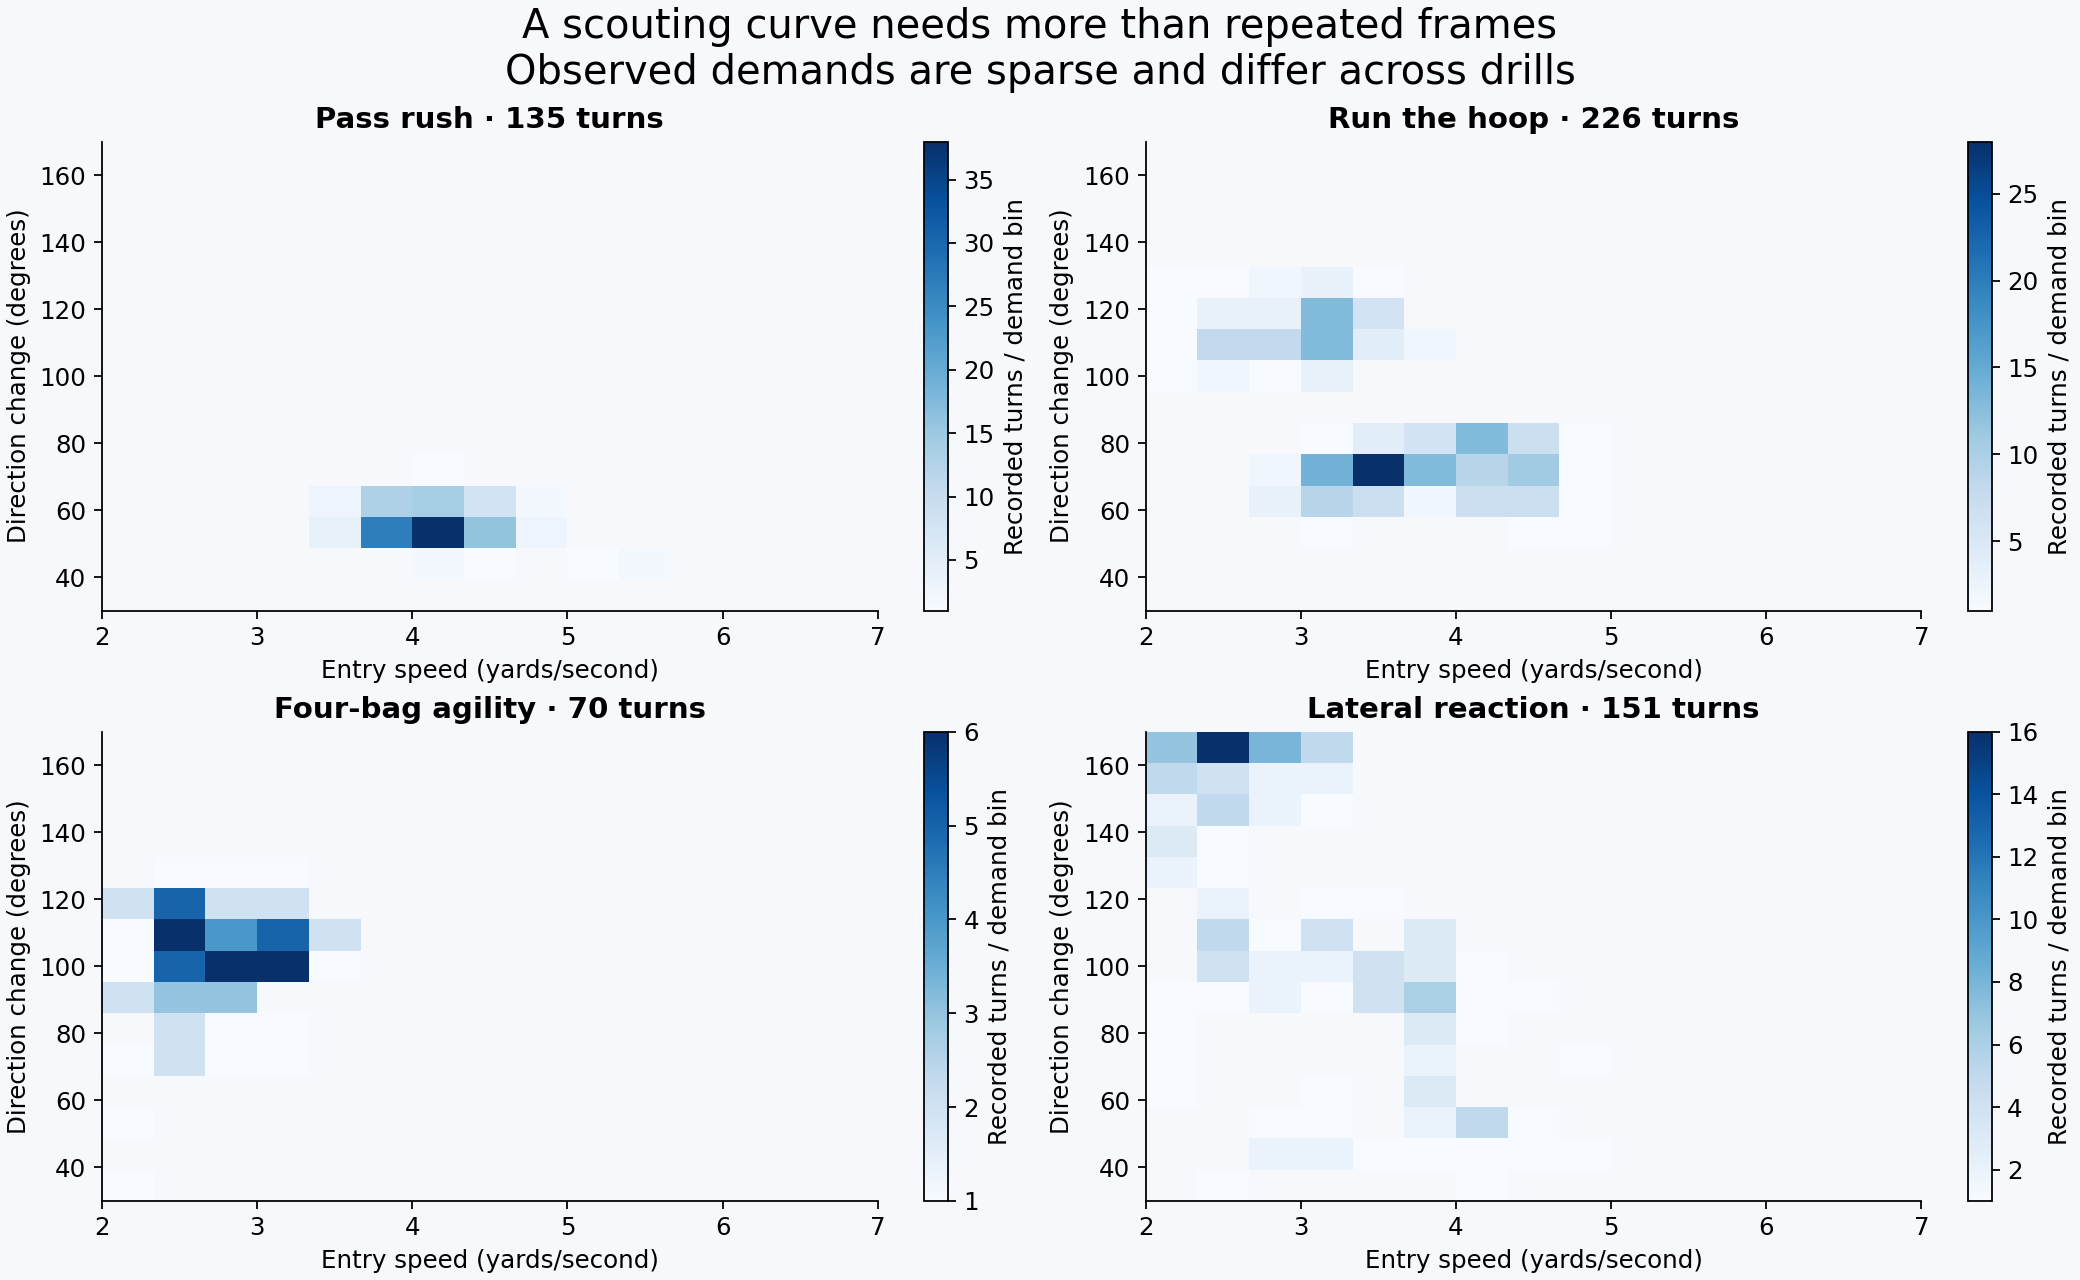

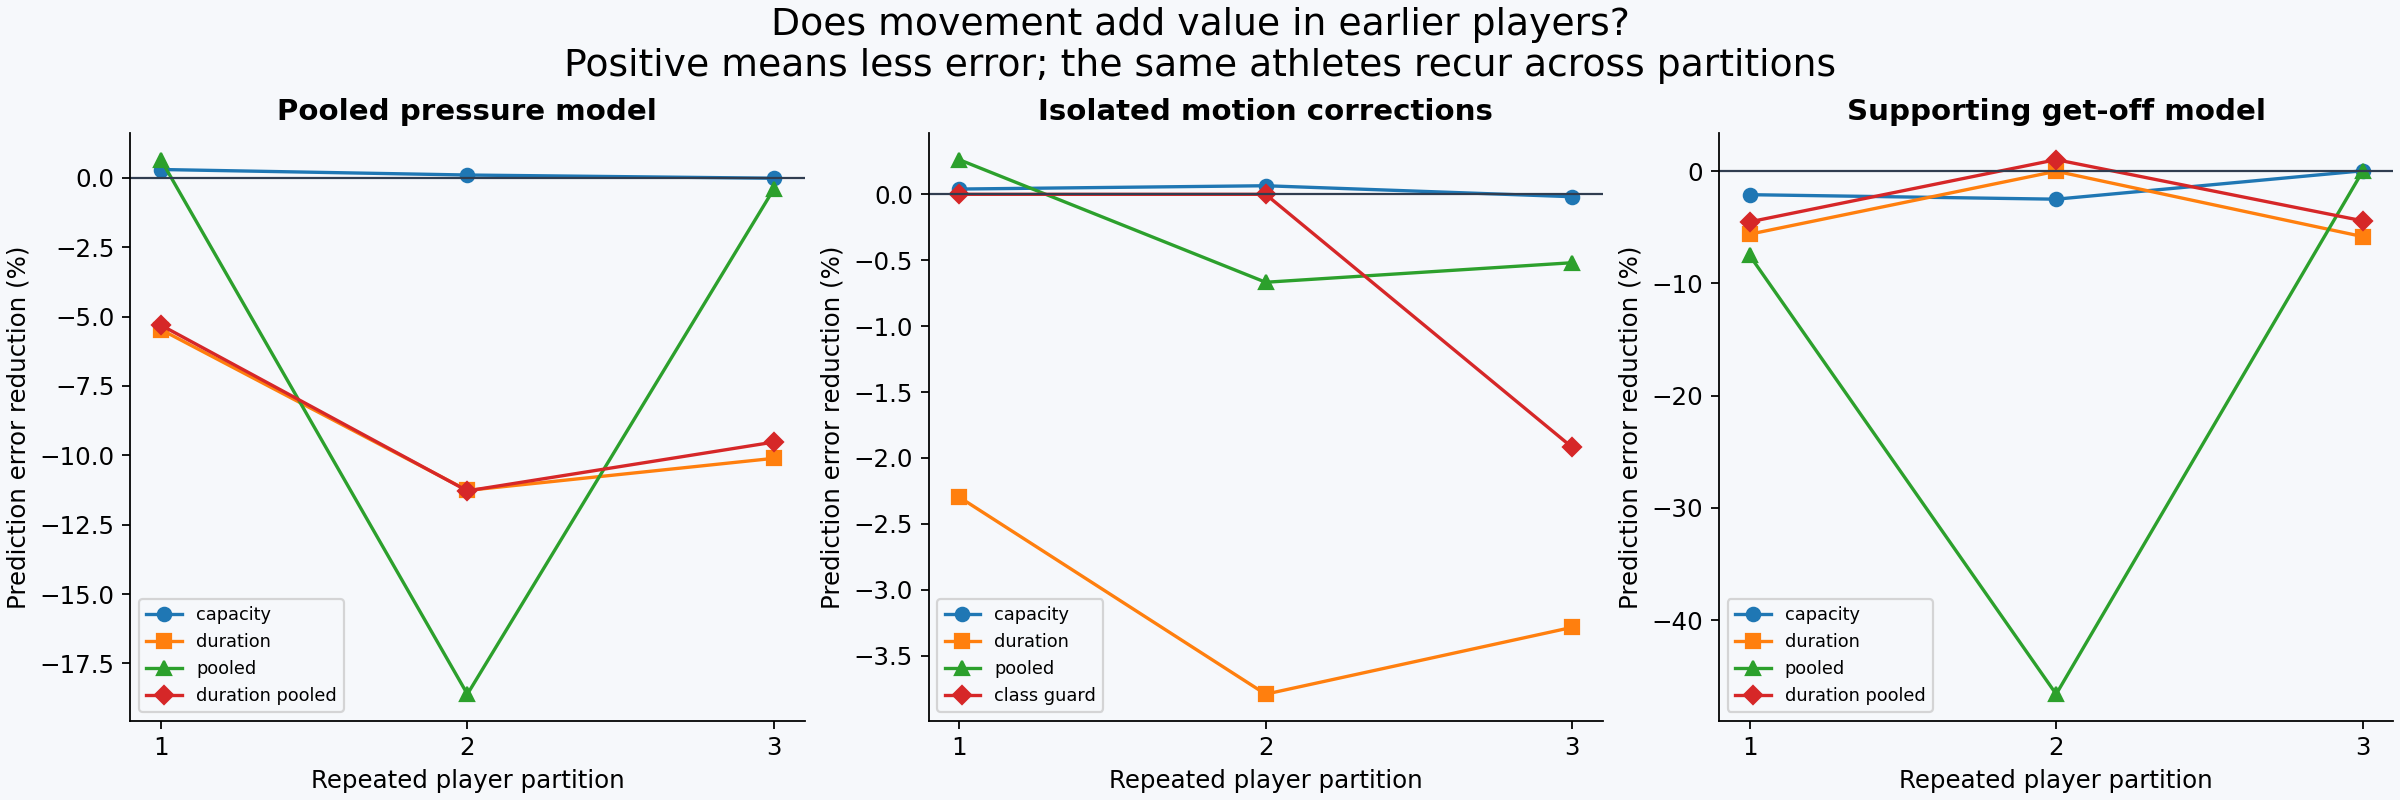

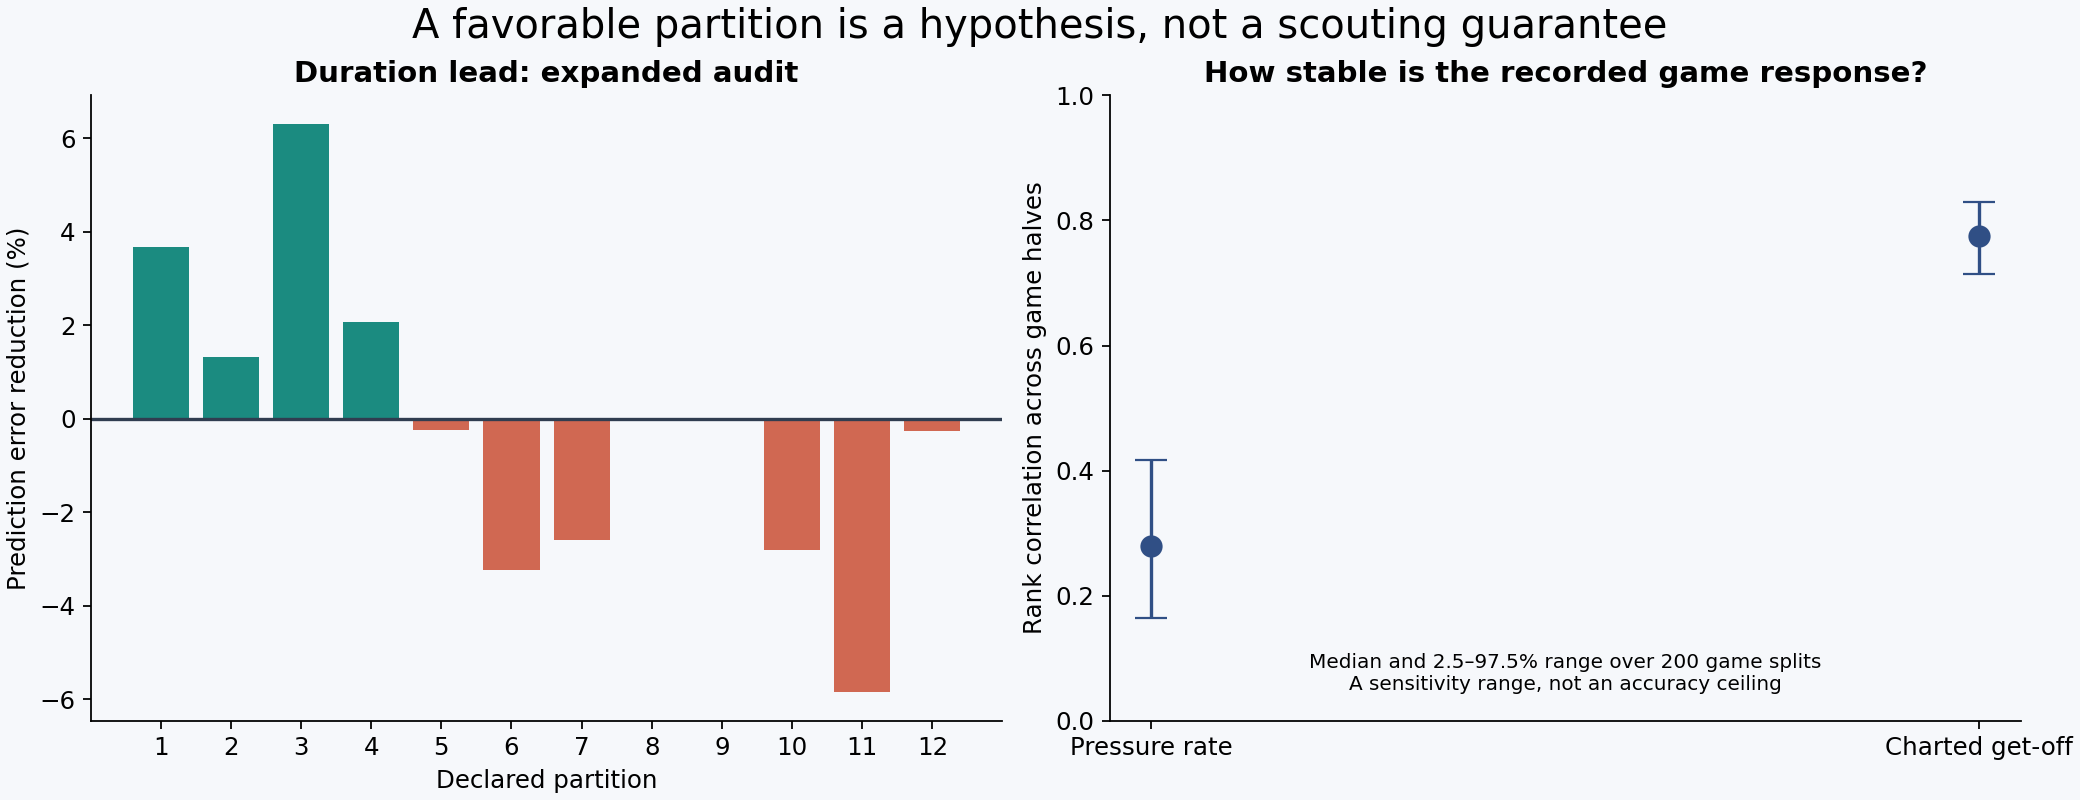

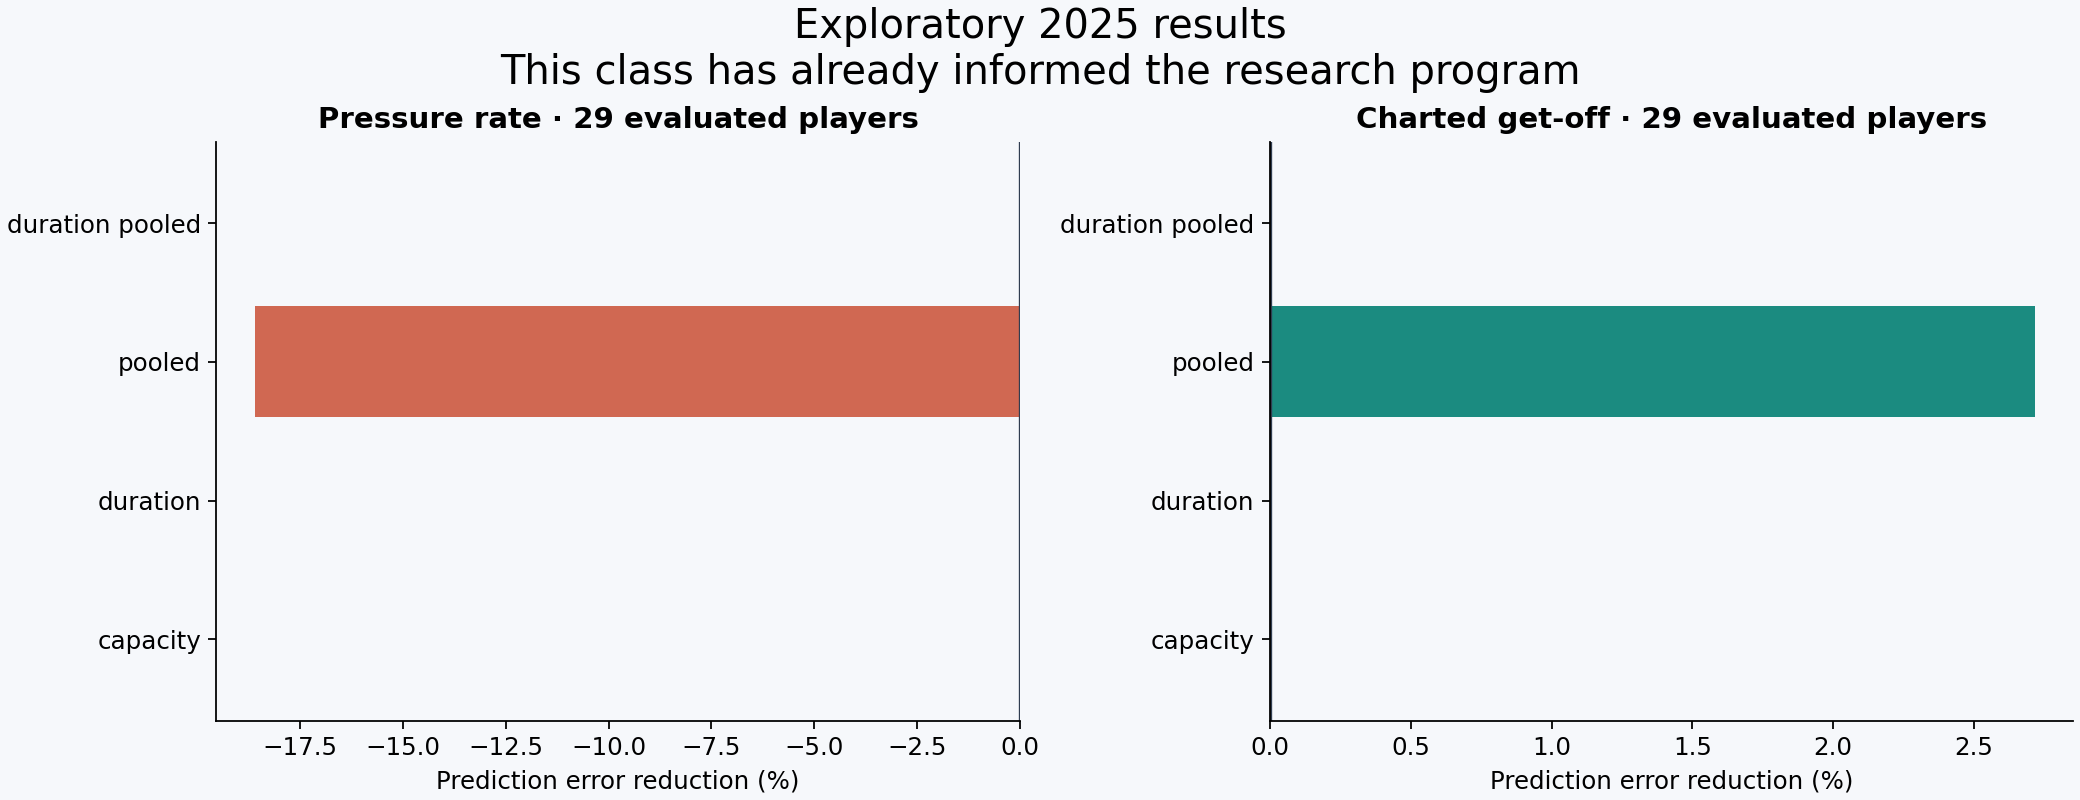

In [4]:
V.render()
for name in ['demand_geometry.png','model_stability.png','signal_and_outcome.png','forward_results.png']:
    display(Image(filename=str(OUT/name)))
print('All adaptive stages and aggregate receipts retained; no public submission or betting-app integration.')
